In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# Table all data

### 5p

In [6]:
md_gut_5p  <- read_csv("../241201_VN_PREDICT2/data/metadata/250121_Gut_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [8]:
md_gut_5p$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
         18771          51934          11276          38339          17587 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         54392          44199          10888          31992          47505 
    Treg naive 
         19573 

In [49]:
md <- md_gut_5p
df4 <- md %>% group_by(data_folder, integrated_snn_res.0.6) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = integrated_snn_res.0.6, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(diagnosis, antitnf_response, 
                                   timepoint, tissue, layer, data_folder) %>% unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


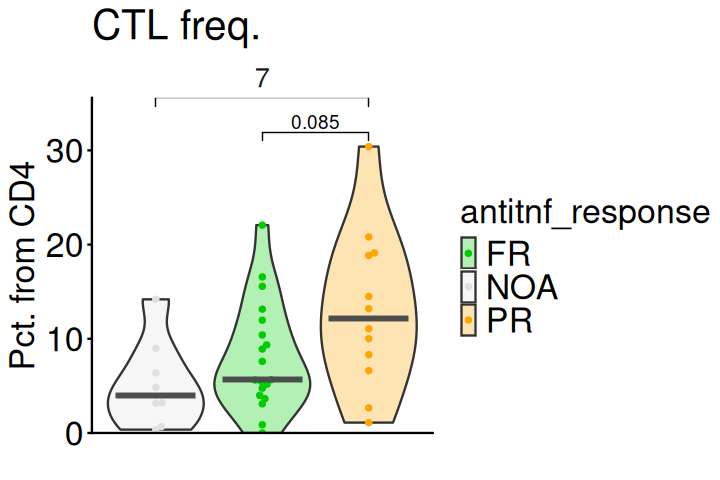

In [50]:
options(repr.plot.width = 6, repr.plot.height = 4)
df_filt <- df4 %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
dplyr::filter(diagnosis %in% c("CD") & tissue == 'ILE' & layer == "LP" &
              timepoint == "T0" & seurat_clusters %in% 7 & freq < 0.99)

stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ antitnf_response, ref.group = "all") %>%
  mutate(p.label = ifelse(p < 0.001, "< 0.001", round(p, 3))) %>%
  rstatix::add_y_position() 

df_filt  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NOA","FR","PR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = 1:11), scales = "free", ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "CTL freq.") +
ggpubr::stat_compare_means(comparisons = list(c(3,2),c(1,3)), label = "p.label") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
ggtheme()
 

### 3p

In [60]:
cd4_gut_3p  <- readRDS("../251029_VN_PREDICT3/data/SCP/Gut_CD4_3p.rds")

In [125]:
library(dplyr)
library(tidyr)
library(tibble)

# Extract metadata
md <- cd4_3p_int@meta.data

# Get all annotations
all_annotations <- sort(unique(as.character(md$annotations2)))
all_annotations <- all_annotations[!is.na(all_annotations)]

# Prepare metadata
md_filt <- md %>%
  mutate(
    data_folder = as.character(data_folder),
    annotations2 = as.character(annotations2),
    participant_id = as.character(patient),

    # Recode timepoints
    timepoint = case_when(
      time %in% c("T0", "T0D") ~ "T0",
      time == "T3M" ~ "R",
      TRUE ~ NA_character_
    ),

    # Recode diagnoses
    diagnosis = case_when(
      disease %in% c("HEA", "Healthy") ~ "HEA",
      disease %in% c("FGID", "DGBI") ~ "FGID",
      disease == "CD" ~ "CD",
      disease == "UC" ~ "UC",
      TRUE ~ "OTH"
    ),

    # Recode anti-TNF response
    antitnf_response = case_when(
      antiTNF_response %in% c("NM", "NOA") ~ "NOA",
      antiTNF_response %in% c("RESP", "FR") ~ "FR",
      antiTNF_response == "PR" ~ "PR",
      TRUE ~ NA_character_
    )
  ) %>%
  filter(
    !is.na(data_folder),
    !is.na(annotations2),
    !is.na(timepoint)
  )

# Count cells per sample and annotation
df_counts <- md_filt %>%
  dplyr::count(
    data_folder,
    participant_id,
    diagnosis,
    antitnf_response,
    timepoint,
    tissue,
    layer,
    annotations2,
    name = "n_cells"
  )

# Add missing annotations with zero cells
df_counts_complete <- df_counts %>%
  group_by(
    data_folder,
    participant_id,
    diagnosis,
    antitnf_response,
    timepoint,
    tissue,
    layer
  ) %>%
  complete(
    annotations2 = all_annotations,
    fill = list(n_cells = 0)
  ) %>%
  ungroup()

# Calculate frequencies
df_freq <- df_counts_complete %>%
  group_by(data_folder) %>%
  mutate(
    freq = n_cells / sum(n_cells)
  ) %>%
  ungroup() %>%
  select(
    data_folder,
    annotations2,
    freq,
    diagnosis,
    antitnf_response,
    participant_id,
    timepoint,
    tissue,
    layer
  ) %>%
  mutate(
    diagnosis = factor(
      diagnosis,
      levels = c("HEA", "FGID", "UC", "CD", "OTH")
    ),
    antitnf_response = factor(
      antitnf_response,
      levels = c("NOA", "FR", "PR")
    ),
    timepoint = factor(
      timepoint,
      levels = c("T0", "R")
    )
  )

# Check resulting data
head(df_freq)

# Number of samples
n_distinct(df_freq$data_folder)

# Number of zero-frequency observations
sum(df_freq$freq == 0)

# Check number of annotations per sample
df_freq %>%
  dplyr::count(data_folder) %>%
  dplyr::count(n)

# Check frequencies sum to 1 per sample
df_freq %>%
  group_by(data_folder) %>%
  summarise(
    total_freq = sum(freq),
    .groups = "drop"
  ) %>%
  print(n = Inf)

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<fct>,<fct>,<chr>,<fct>,<chr>,<chr>
HE-001-014 COL EPI T0,CD4 CTL,0.23076923,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Mixed Teff1,0.00000000,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Mixed Teff2,0.00000000,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Naive,0.15384615,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Proliferating,0.46153846,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Tcm,0.07692308,HEA,NOA,HE-001-014,T0,COL,EPI


[1] 177

[1] 286

Storing counts in `nn`, as `n` already present in input
ℹ Use `name = "new_name"` to pick a new name.


n,nn
<int>,<int>
9,177


# A tibble: 177 × 2
    data_folder           total_freq
    <chr>                      <dbl>
  1 HE-001-014 COL EPI T0          1
  2 HE-001-014 COL LP T0           1
  3 HE-001-014 DUO EPI T0          1
  4 HE-001-014 DUO LP T0           1
  5 HE-001-014 ILE EPI T0          1
  6 HE-001-014 ILE LP T0           1
  7 HE-001-023 COL EPI T0          1
  8 HE-001-023 COL LP T0           1
  9 HE-001-023 DUO EPI T0          1
 10 HE-001-023 DUO LP T0           1
 11 HE-001-023 ILE EPI T0          1
 12 HE-001-023 ILE LP T0           1
 13 HE-001-024 COL LP T0           1
 14 HE-001-024 DUO EPI T0          1
 15 HE-001-024 DUO LP T0           1
 16 HE-001-024 ILE EPI T0          1
 17 HE-001-025 COL LP T0           1
 18 HE-001-025 DUO EPI T0          1
 19 HE-001-025 DUO LP T0           1
 20 HE-001-025 ILE LP T0           1
 21 HE-001-026 COL EPI T0          1
 22 HE-001-026 COL LP T0           1
 23 HE-001-026 DUO LP T0           1
 24 HE-001-026 ILE LP T0           1
 25 p002 COL EPI T

In [126]:
write.csv(df_freq, "tables/261103_making_freq_table_gut_cd4_3p.csv")

In [222]:
write.csv(df4_5p, "tables/260927_making_freq_table_gut_cd4_5p.csv")

## Blood datasets

In [153]:
bl_5p  <- readRDS('../251029_VN_PREDICT3/data/SCP/Blood_CD3NK_5p.rds')

In [154]:
bl_3p  <- readRDS('../251029_VN_PREDICT3/data/SCP/Blood_CD3NK_3p.rds')

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



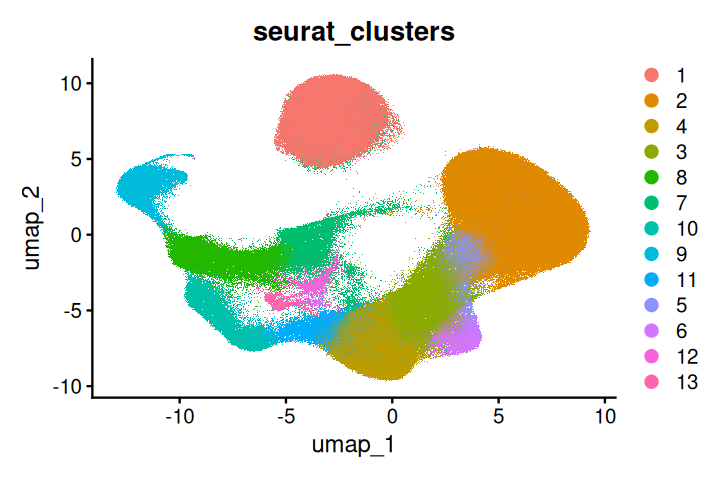

In [158]:
DimPlot(bl_5p, group.by = "seurat_clusters")

In [159]:
bl_5p

An object of class Seurat 
19054 features across 593574 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [160]:
bl_3p

An object of class Seurat 
27782 features across 324539 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [161]:
324539 +593574 

[1] 918113

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



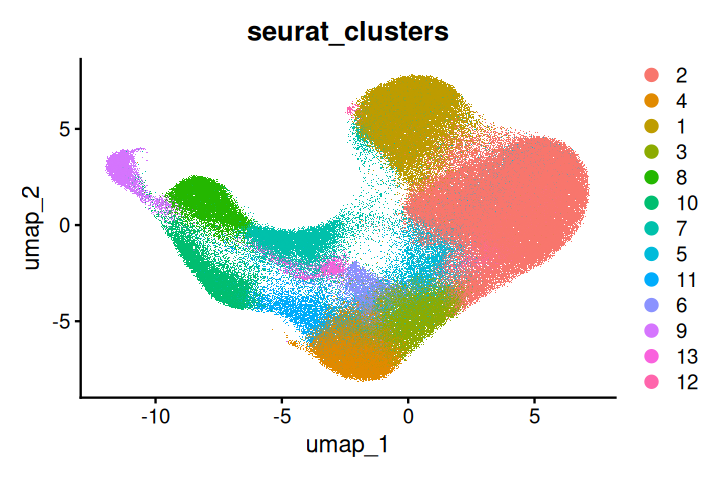

In [157]:
DimPlot(bl_3p, group.by = "seurat_clusters")

In [162]:
bl_3p@meta.data  %>% colnames

[1] "orig.ident"       "nCount_RNA"       "nFeature_RNA"     "seurat_clusters" 
 [5] "participant_id"   "diagnosis"        "timepoint"        "tissue"          
 [9] "layer"            "antitnf_response" "cd4_ctl"

In [163]:
bl_3p$timepoint  %>% table

.
   T0D    T3M 
301084  23455 

In [164]:
bl_5p$timepoint  %>% table

.
     R     R2     T0 
 91012   1421 501141 

### Blood 3p

In [166]:
md  <- bl_3p@meta.data  %>% 
mutate(data_folder = paste(participant_id,
                                   timepoint, tissue, layer))

df4_3p_bl <- md %>% group_by(data_folder, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
ungroup  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "annotations2", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(diagnosis, antitnf_response, participant_id, 
                                   timepoint, tissue, layer, data_folder) %>% 
unique()
df4_3p_bl  <- left_join(df4_3p_bl, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [167]:
df4_3p_bl

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
p002 T0D BLD CD3,2,0.331894037,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,4,0.122884817,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,1,0.159411833,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,3,0.083090209,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,8,0.036293617,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,10,0.065468549,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,7,0.075388027,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,5,0.012720271,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,11,0.027424437,FGID,NM,p002,T0D,BLD,CD3


In [168]:
md  <- bl_3p@meta.data  %>% 
mutate(data_folder = paste(participant_id,
                                   timepoint, tissue, layer))

df4_3p_bl2 <- md %>% group_by(data_folder, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
ungroup  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "annotations2", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(diagnosis, antitnf_response, participant_id, 
                                   timepoint, tissue, layer, data_folder) %>% 
unique()
df4_3p_bl2  <- left_join(df4_3p_bl2, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [169]:
df4_3p_bl2

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
p002 T0D BLD CD3,FALSE,0.9989497024,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,TRUE,0.0010502976,FGID,NM,p002,T0D,BLD,CD3
p003 T0D BLD CD3,FALSE,1.0000000000,FGID,NM,p003,T0D,BLD,CD3
p003 T0D BLD CD3,TRUE,0.0000000000,FGID,NM,p003,T0D,BLD,CD3
p009 T0D BLD CD3,FALSE,1.0000000000,FGID,NM,p009,T0D,BLD,CD3
p009 T0D BLD CD3,TRUE,0.0000000000,FGID,NM,p009,T0D,BLD,CD3
p010 T0D BLD CD3,FALSE,0.9959514170,CD,PR,p010,T0D,BLD,CD3
p010 T0D BLD CD3,TRUE,0.0040485830,CD,PR,p010,T0D,BLD,CD3
p011 T0D BLD CD3,FALSE,0.9998580352,CD,RESP,p011,T0D,BLD,CD3


In [217]:
df4_3p_bl3  <- rbind(df4_3p_bl, df4_3p_bl2  %>% dplyr::filter(annotations2 == "TRUE"))

In [218]:
df4_3p_bl3


data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
p002 T0D BLD CD3,2,0.331894037,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,4,0.122884817,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,1,0.159411833,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,3,0.083090209,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,8,0.036293617,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,10,0.065468549,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,7,0.075388027,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,5,0.012720271,FGID,NM,p002,T0D,BLD,CD3
p002 T0D BLD CD3,11,0.027424437,FGID,NM,p002,T0D,BLD,CD3


In [219]:
df4_3p_bl3  <- df4_3p_bl3  %>% 
mutate(timepoint = gsub(timepoint, pattern = "T0D", replacement = "T0"))  %>% 
mutate(timepoint = gsub(timepoint, pattern = "T3M", replacement = "R"))  %>% 
mutate(layer = gsub(layer, pattern = "LPS", replacement = "LP")) 


### Blood 5p

In [173]:
bl_5p@meta.data  %>% colnames

[1] "orig.ident"       "nCount_RNA"       "nFeature_RNA"     "seurat_clusters" 
 [5] "participant_id"   "diagnosis"        "timepoint"        "age"             
 [9] "sex"              "tissue"           "layer"            "antitnf_response"
[13] "cd4_ctl"

In [174]:
md  <- bl_5p@meta.data %>% 
mutate(data_folder = paste(participant_id,
                                   timepoint, tissue, layer))

df4_5p_bl <- md %>% group_by(data_folder, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
ungroup  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "annotations2", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(diagnosis, antitnf_response, participant_id, 
                                   timepoint, tissue, layer, data_folder) %>% 
unique()
df4_5p_bl  <- left_join(df4_5p_bl, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [175]:
df4_5p_bl

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
001-009 T0 BLD CD3,1,0.187490993,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,2,0.370802709,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,4,0.079406255,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,3,0.063697939,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,8,0.086035452,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,7,0.030119614,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,10,0.027813806,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,9,0.070903588,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,11,0.018734688,FGID,NM,001-009,T0,BLD,CD3


In [176]:
md  <- bl_5p@meta.data  %>% 
mutate(data_folder = paste(participant_id,
                                   timepoint, tissue, layer))

df4_5p_bl2 <- md %>% group_by(data_folder, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
ungroup  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "annotations2", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(diagnosis, antitnf_response, participant_id, 
                                   timepoint, tissue, layer, data_folder) %>% 
unique()
df4_5p_bl2  <- left_join(df4_5p_bl2, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [177]:
df4_5p_bl2

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
001-009 T0 BLD CD3,FALSE,0.9995676610,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,TRUE,0.0004323390,FGID,NM,001-009,T0,BLD,CD3
001-011 R BLD CD3,FALSE,0.9995670371,CD,FR,001-011,R,BLD,CD3
001-011 R BLD CD3,TRUE,0.0004329629,CD,FR,001-011,R,BLD,CD3
001-011 T0 BLD CD3,FALSE,0.9995726496,CD,FR,001-011,T0,BLD,CD3
001-011 T0 BLD CD3,TRUE,0.0004273504,CD,FR,001-011,T0,BLD,CD3
001-014 R BLD CD3,FALSE,0.9983036472,CD,FR,001-014,R,BLD,CD3
001-014 R BLD CD3,TRUE,0.0016963528,CD,FR,001-014,R,BLD,CD3
001-015 T0 BLD CD3,FALSE,1.0000000000,UC,NOA,001-015,T0,BLD,CD3


In [178]:
df4_5p_bl3  <- rbind(df4_5p_bl, df4_5p_bl2  %>% dplyr::filter(annotations2 == "TRUE"))

In [179]:
df4_5p_bl3

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
001-009 T0 BLD CD3,1,0.187490993,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,2,0.370802709,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,4,0.079406255,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,3,0.063697939,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,8,0.086035452,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,7,0.030119614,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,10,0.027813806,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,9,0.070903588,FGID,NM,001-009,T0,BLD,CD3
001-009 T0 BLD CD3,11,0.018734688,FGID,NM,001-009,T0,BLD,CD3


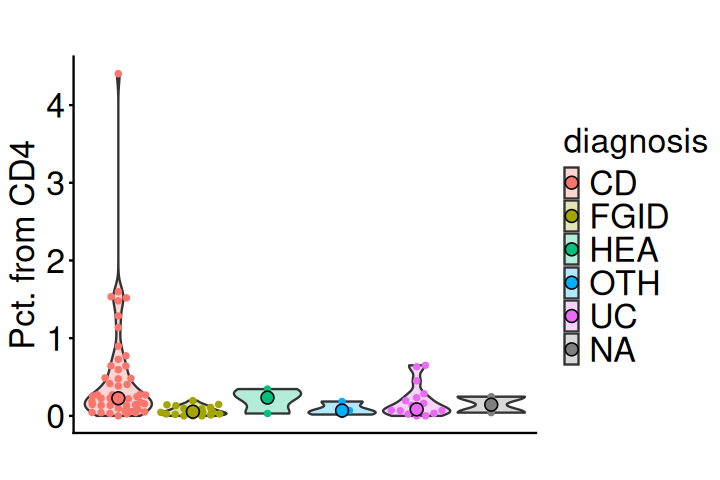

In [181]:
df4_5p_bl3  %>% 
dplyr::filter(annotations2 == "TRUE")  %>% 
ggplot(aes(x=diagnosis, y=freq*100)) +
geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = diagnosis), color = "black") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "")  +
ggtheme()

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


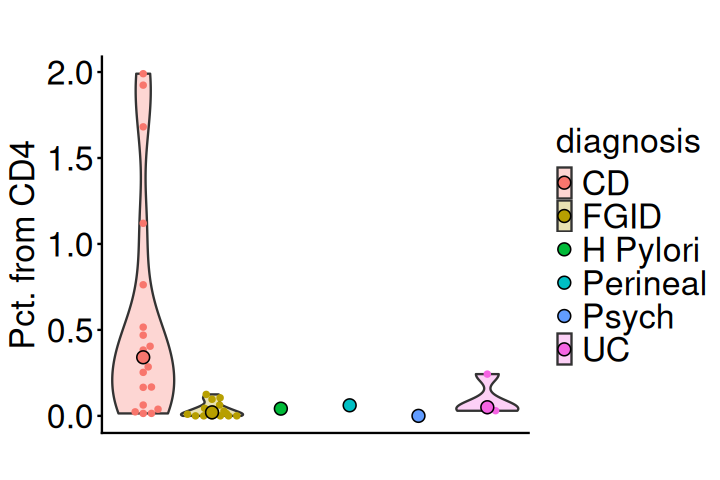

In [182]:
df4_3p_bl3  %>% 
dplyr::filter(annotations2 == "TRUE")  %>% 
ggplot(aes(x=diagnosis, y=freq*100)) +
geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = diagnosis), color = "black") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "")  +
ggtheme()

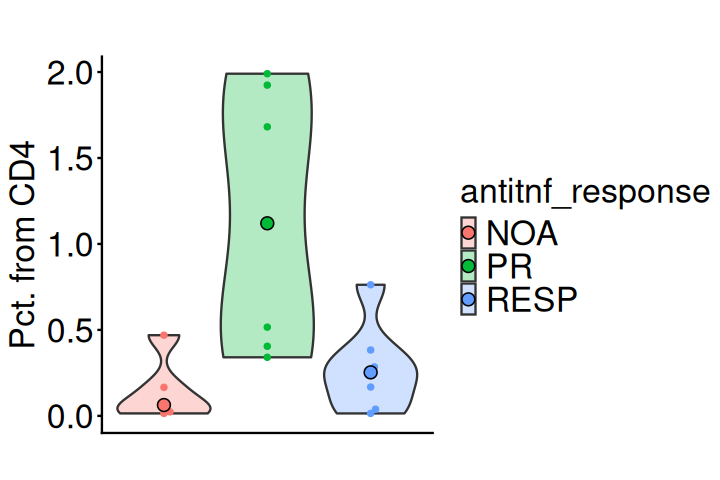

In [184]:
df4_3p_bl3  %>% 
dplyr::filter(annotations2 == "TRUE" & diagnosis == "CD")  %>% 
ggplot(aes(x=antitnf_response, y=freq*100)) +
geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = antitnf_response), color = "black") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "")  +
ggtheme()

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


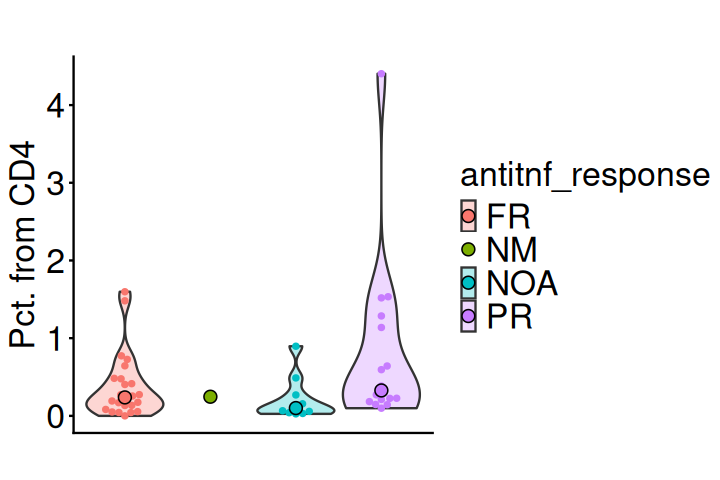

In [185]:
df4_5p_bl3  %>% 
dplyr::filter(annotations2 == "TRUE" & diagnosis == "CD")  %>% 
ggplot(aes(x=antitnf_response, y=freq*100)) +
geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = antitnf_response), color = "black") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "")  +
ggtheme()

In [223]:
write.csv(df4_3p_bl3, "tables/260927_making_freq_table_blood_cd4_3p.csv")
write.csv(df4_5p_bl3, "tables/260927_making_freq_table_blood_cd4_5p.csv")

## Load df_all_data

In [204]:
df4_5p_bl3  <- read_csv("tables/260927_making_freq_table_blood_cd4_5p.csv")
df4_5p  <- read_csv("tables/260927_making_freq_table_gut_cd4_5p.csv")

New names:
• `` -> `...1`
Rows: 1358 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (9): data_folder, annotations2, diagnosis, antitnf_response, participant...
dbl (2): ...1, freq

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 4545 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (9): data_folder, annotations2, diagnosis, antitnf_response, participant...
dbl (2): ...1, freq

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [205]:
df4_3p_bl3  <- read_csv("tables/260927_making_freq_table_blood_cd4_3p.csv")
df4_3p  <- read_csv("tables/261103_making_freq_table_gut_cd4_3p.csv")

New names:
• `` -> `...1`
Rows: 588 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (8): data_folder, annotations2, diagnosis, antitnf_response, participant...
dbl (2): ...1, freq

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 1593 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (8): data_folder, annotations2, diagnosis, antitnf_response, participant...
dbl (2): ...1, freq

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [206]:
df4_5p_bl3$dataset  <- "BLD 5p"

In [207]:
df4_3p_bl3$dataset  <- "BLD 3p"

In [208]:
df4_5p$dataset  <- "GUT 5p"

In [209]:
df4_3p$dataset  <- "GUT 3p"

In [210]:
df4_3p$annotations2  %>% table

.
      CD4 CTL   Mixed Teff1   Mixed Teff2         Naive Proliferating 
          177           177           177           177           177 
          Tcm           Tfh          Th17          Treg 
          177           177           177           177 

In [211]:
df4_5p$annotations2  %>% table

.
  CTL   IEL Naive   Tcm   Tfh   Th1  Th17   Th2  Treg 
  505   505   505   505   505   505   505   505   505 

In [212]:
df4_5p  <- df4_5p  %>% mutate(annotations2 =
                                                                   recode_factor(annotations2, 
                                                                                "Tcm" = "Tcm",
  "Th2" = "Mixed Teff1",
  "Naive" = "Naive",
  "Th17" = "Th17",
  "Treg" = "Treg",
  "Th1" = "Mixed Teff2",
  "Tfh" = "Tfh",
  "CTL" = "CD4 CTL",
  "IEL" = "IEL")
)

In [213]:
df4_5p$annotations2  %>% table

.
        Tcm Mixed Teff1       Naive        Th17        Treg Mixed Teff2 
        505         505         505         505         505         505 
        Tfh     CD4 CTL         IEL 
        505         505         505 

In [214]:
all.equal(colnames(df4_3p), colnames(df4_5p))

[1] TRUE

In [215]:
all.equal(colnames(df4_3p_bl3), colnames(df4_5p_bl3))

[1] TRUE

In [216]:
all.equal(colnames(df4_3p_bl3), colnames(df4_5p))

[1] TRUE

In [217]:
df_all_data  <- rbind(df4_5p, df4_3p, df4_3p_bl3, df4_5p_bl3)

In [218]:
df_all_data  %>% group_by(participant_id, timepoint, tissue, layer)  %>% tally()  %>% arrange(participant_id)

participant_id,timepoint,tissue,layer,n
<chr>,<chr>,<chr>,<chr>,<int>
001-009,T0,BLD,CD3,14
001-009,T0,COL,LP,9
001-009,T0,ILE,LP,9
001-011,R,BLD,CD3,14
001-011,R,COL,EPI,9
001-011,R,COL,LP,9
001-011,R,DUO,EPI,9
001-011,R,DUO,LP,9
001-011,R,ILE,EPI,9


In [130]:
df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
group_by(participant_id2, dataset, timepoint, tissue, layer)  %>% 
tally()  %>% 
ungroup  %>% 
dplyr::select(-n, -dataset)  %>% 
group_by(participant_id2, timepoint, tissue, layer)  %>% 
tally()  %>% arrange(desc(n))

participant_id2,timepoint,tissue,layer,n
<chr>,<chr>,<chr>,<chr>,<int>
001-009,T0,BLD,CD3,2
001-009,T0,COL,LP,2
001-009,T0,ILE,LP,2
001-011,T0,BLD,CD3,2
001-011,T0,COL,LP,2
001-011,T0,DUO,LP,2
001-011,T0,ILE,LP,2
001-014,R,BLD,CD3,2
001-014,R,COL,LP,2


In [131]:
df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>%
mutate(participant_id2 = gsub(participant_id2, pattern = "HE-001-", replacement = "HE-"))  %>%
group_by(participant_id2, dataset, timepoint, tissue, layer)  %>% 
tally()  %>% 
ungroup  %>% 
dplyr::select(-n, -dataset)  %>% 
group_by(participant_id2, timepoint, tissue, layer)  %>% 
tally()  %>% dplyr::filter(n == 2)

participant_id2,timepoint,tissue,layer,n
<chr>,<chr>,<chr>,<chr>,<int>
001-009,T0,BLD,CD3,2
001-009,T0,COL,LP,2
001-009,T0,ILE,LP,2
001-011,T0,BLD,CD3,2
001-011,T0,COL,LP,2
001-011,T0,DUO,LP,2
001-011,T0,ILE,LP,2
001-014,R,BLD,CD3,2
001-014,R,COL,LP,2


In [241]:
df_all_data2  <- df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>%
mutate(participant_id2 = gsub(participant_id2, pattern = "HE-001-", replacement = "HE-"))

## Correlation blood

In [103]:
bld_samples_both  <- df_all_data2  %>% 
group_by(participant_id2, dataset, timepoint, tissue, layer)  %>% 
tally()  %>% 
ungroup  %>% 
dplyr::select(-n, -dataset)  %>% 
group_by(participant_id2, timepoint, tissue, layer)  %>% 
tally()  %>% dplyr::filter(n == 2)  %>% 
dplyr::filter(tissue == "BLD")  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
pull(smp_id)

In [104]:
bld_samples_both

[1] "001-009 T0 BLD CD3" "001-011 T0 BLD CD3" "001-014 R BLD CD3" 
 [4] "001-015 T0 BLD CD3" "001-018 T0 BLD CD3" "001-019 R BLD CD3" 
 [7] "001-019 T0 BLD CD3" "001-022 T0 BLD CD3" "001-023 T0 BLD CD3"
[10] "001-024 T0 BLD CD3" "001-026 T0 BLD CD3" "001-027 T0 BLD CD3"
[13] "001-028 T0 BLD CD3" "001-030 T0 BLD CD3" "001-031 T0 BLD CD3"
[16] "001-032 T0 BLD CD3" "001-033 T0 BLD CD3" "001-034 T0 BLD CD3"
[19] "001-035 T0 BLD CD3" "001-042 T0 BLD CD3" "001-043 T0 BLD CD3"
[22] "001-044 T0 BLD CD3" "001-045 T0 BLD CD3" "001-047 T0 BLD CD3"
[25] "001-048 T0 BLD CD3" "001-049 T0 BLD CD3" "001-050 T0 BLD CD3"

In [243]:
df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% bld_samples_both)  %>% 
ungroup  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")

annotations2,smp_id,BLD 3p,BLD 5p
<chr>,<chr>,<dbl>,<dbl>
2,001-009 T0 BLD CD3,0.422576448,0.370802709
4,001-009 T0 BLD CD3,0.075471698,0.079406255
1,001-009 T0 BLD CD3,0.173389720,0.187490993
3,001-009 T0 BLD CD3,0.053675992,0.063697939
8,001-009 T0 BLD CD3,0.089459987,0.086035452
10,001-009 T0 BLD CD3,0.027976578,0.027813806
7,001-009 T0 BLD CD3,0.033506831,0.030119614
5,001-009 T0 BLD CD3,0.022012579,0.040207523
11,001-009 T0 BLD CD3,0.016482325,0.018734688


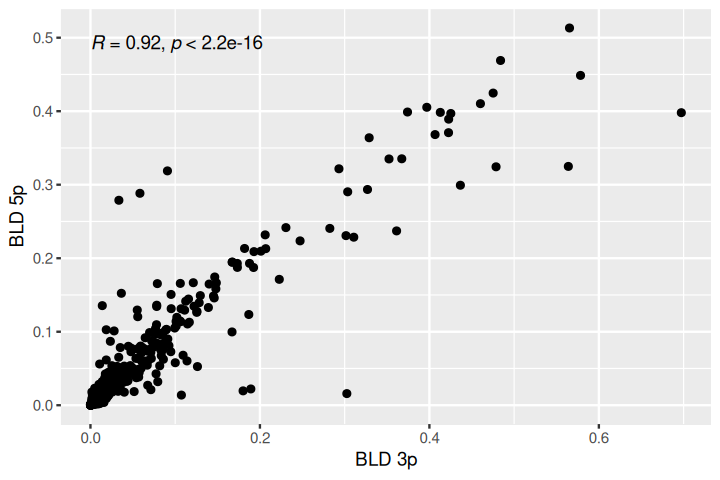

In [246]:
df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% bld_samples_both)  %>% 
ungroup  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")  %>% 
ggplot(aes(x = `BLD 3p`, y = `BLD 5p`)) +
geom_point() +
ggpubr::stat_cor()

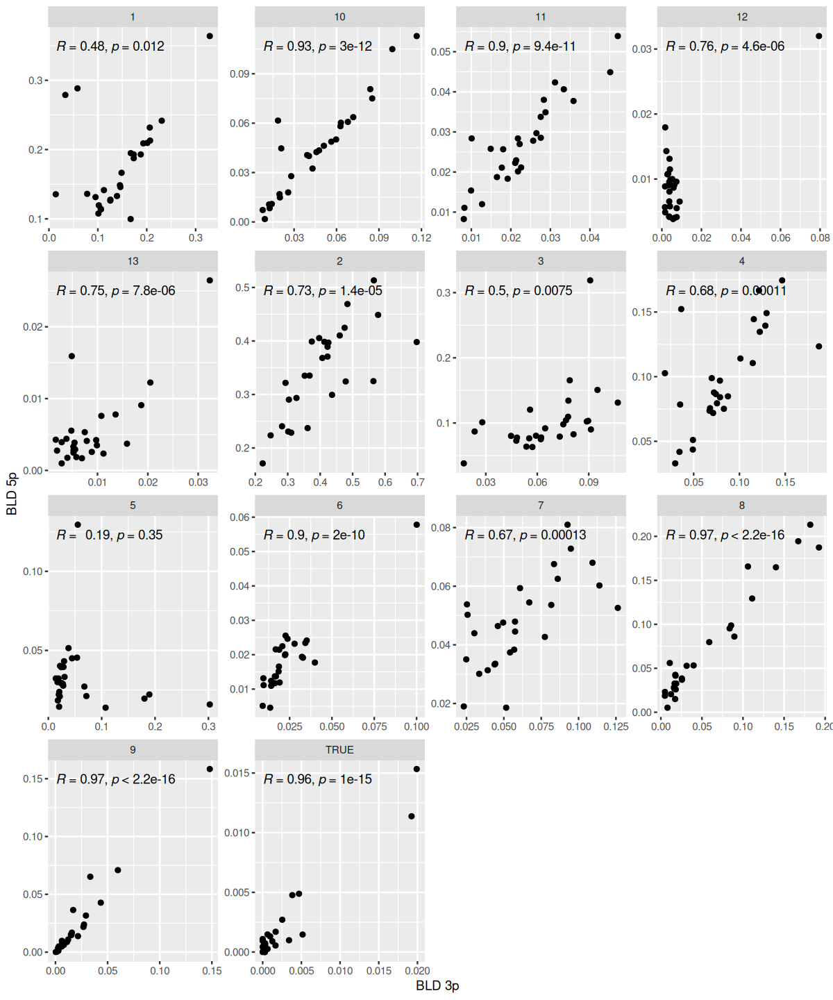

In [249]:
options(repr.plot.width = 10, repr.plot.height = 12)
df_all_data  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% bld_samples_both)  %>% 
ungroup  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")  %>% 
ggplot(aes(x = `BLD 3p`, y = `BLD 5p`)) +
geom_point() +
ggpubr::stat_cor() +
facet_wrap(~annotations2, scales = "free")

## Correlation gut

In [242]:
gut_samples_both  <- df_all_data2  %>% 
group_by(participant_id2, dataset, timepoint, tissue, layer)  %>% 
tally()  %>% 
ungroup  %>% 
dplyr::select(-n, -dataset)  %>% 
group_by(participant_id2, timepoint, tissue, layer)  %>% 
tally()  %>% dplyr::filter(n == 2)  %>% 
dplyr::filter(tissue != "BLD")  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
pull(smp_id)

In [243]:
gut_samples_both

[1] "001-009 T0 COL LP"  "001-009 T0 ILE LP"  "001-011 T0 COL LP" 
  [4] "001-011 T0 DUO LP"  "001-011 T0 ILE LP"  "001-014 R COL LP"  
  [7] "001-014 R DUO LP"   "001-014 R ILE LP"   "001-014 T0 COL LP" 
 [10] "001-014 T0 ILE LP"  "001-015 T0 COL LP"  "001-015 T0 ILE LP" 
 [13] "001-016 T0 COL LP"  "001-016 T0 DUO LP"  "001-016 T0 ILE LP" 
 [16] "001-017 T0 COL LP"  "001-017 T0 DUO LP"  "001-017 T0 ILE LP" 
 [19] "001-018 T0 COL LP"  "001-018 T0 DUO LP"  "001-018 T0 ILE LP" 
 [22] "001-019 R COL LP"   "001-019 R DUO EPI"  "001-019 R DUO LP"  
 [25] "001-019 R ILE EPI"  "001-019 R ILE LP"   "001-019 T0 COL LP" 
 [28] "001-019 T0 DUO LP"  "001-019 T0 ILE LP"  "001-022 T0 COL LP" 
 [31] "001-022 T0 DUO LP"  "001-022 T0 ILE LP"  "001-023 T0 COL LP" 
 [34] "001-023 T0 DUO LP"  "001-023 T0 ILE LP"  "001-024 T0 COL LP" 
 [37] "001-024 T0 DUO LP"  "001-024 T0 ILE LP"  "001-026 T0 COL LP" 
 [40] "001-026 T0 ILE LP"  "001-027 T0 COL LP"  "001-027 T0 DUO LP" 
 [43] "001-027 T0 ILE LP"  "001-028 T0 COL LP"  "001-028 T0 DUO LP" 
 [46] "001-028 T0 ILE LP"  "001-030 T0 COL LP"  "001-030 T0 DUO LP" 
 [49] "001-030 T0 ILE LP"  "001-031 T0 DUO LP"  "001-031 T0 ILE LP" 
 [52] "001-032 T0 COL LP"  "001-032 T0 DUO LP"  "001-032 T0 ILE LP" 
 [55] "001-033 T0 COL LP"  "001-033 T0 DUO LP"  "001-033 T0 ILE LP" 
 [58] "001-034 T0 COL LP"  "001-034 T0 DUO LP"  "001-034 T0 ILE LP" 
 [61] "001-035 T0 DUO LP"  "001-035 T0 ILE LP"  "001-036 T0 COL LP" 
 [64] "001-036 T0 ILE LP"  "001-038 T0 COL LP"  "001-038 T0 ILE LP" 
 [67] "001-041 T0 DUO LP"  "001-041 T0 ILE LP"  "001-042 T0 COL LP" 
 [70] "001-042 T0 DUO LP"  "001-042 T0 ILE LP"  "001-043 T0 COL LP" 
 [73] "001-043 T0 DUO LP"  "001-043 T0 ILE LP"  "001-044 T0 COL LP" 
 [76] "001-044 T0 ILE LP"  "001-045 T0 COL LP"  "001-045 T0 DUO LP" 
 [79] "001-045 T0 ILE LP"  "001-047 T0 COL LP"  "001-047 T0 ILE LP" 
 [82] "001-048 T0 COL EPI" "001-048 T0 COL LP"  "001-048 T0 DUO EPI"
 [85] "001-048 T0 DUO LP"  "001-048 T0 ILE EPI" "001-048 T0 ILE LP" 
 [88] "001-049 T0 COL EPI" "001-049 T0 COL LP"  "001-049 T0 DUO EPI"
 [91] "001-049 T0 DUO LP"  "001-050 T0 COL EPI" "001-050 T0 COL LP" 
 [94] "001-050 T0 DUO EPI" "001-050 T0 DUO LP"  "001-050 T0 ILE EPI"
 [97] "001-050 T0 ILE LP"  "HE-014 T0 COL EPI"  "HE-014 T0 COL LP"  
[100] "HE-014 T0 DUO EPI"  "HE-014 T0 DUO LP"   "HE-014 T0 ILE EPI" 
[103] "HE-014 T0 ILE LP"   "HE-023 T0 COL EPI"  "HE-023 T0 COL LP"  
[106] "HE-023 T0 DUO EPI"  "HE-023 T0 DUO LP"   "HE-023 T0 ILE EPI" 
[109] "HE-023 T0 ILE LP"   "HE-024 T0 COL LP"   "HE-024 T0 DUO EPI" 
[112] "HE-024 T0 DUO LP"   "HE-024 T0 ILE EPI"  "HE-025 T0 COL LP"  
[115] "HE-025 T0 DUO EPI"  "HE-025 T0 DUO LP"   "HE-025 T0 ILE LP"  
[118] "HE-026 T0 COL EPI"  "HE-026 T0 COL LP"   "HE-026 T0 DUO LP"  
[121] "HE-026 T0 ILE LP"

In [244]:
df_all_data2  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% gut_samples_both)  %>% 
ungroup  %>% 
group_by(participant_id2, timepoint, tissue, layer, annotations2, dataset)  %>% 
summarise(freq = mean(freq))

`summarise()` has grouped output by 'participant_id2', 'timepoint', 'tissue',
'layer', 'annotations2'. You can override using the `.groups` argument.


participant_id2,timepoint,tissue,layer,annotations2,dataset,freq
<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>
001-009,T0,COL,LP,Tcm,GUT 3p,0.229995979
001-009,T0,COL,LP,Tcm,GUT 5p,0.142783505
001-009,T0,COL,LP,Mixed Teff2,GUT 3p,0.023723361
001-009,T0,COL,LP,Mixed Teff2,GUT 5p,0.096391753
001-009,T0,COL,LP,Naive,GUT 3p,0.361077604
001-009,T0,COL,LP,Naive,GUT 5p,0.293814433
001-009,T0,COL,LP,Th17,GUT 3p,0.192199437
001-009,T0,COL,LP,Th17,GUT 5p,0.114432990
001-009,T0,COL,LP,Treg,GUT 3p,0.078809811


In [245]:
df_all_data2  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% gut_samples_both)  %>% 
ungroup  %>% 
group_by(participant_id2, timepoint, tissue, layer, annotations2, dataset, smp_id)  %>% 
summarise(freq = mean(freq))  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")

`summarise()` has grouped output by 'participant_id2', 'timepoint', 'tissue',
'layer', 'annotations2', 'dataset'. You can override using the `.groups`
argument.
Adding missing grouping variables: `participant_id2`, `timepoint`, `tissue`,
`layer`


participant_id2,timepoint,tissue,layer,annotations2,smp_id,GUT 3p,GUT 5p
<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>
001-009,T0,COL,LP,Tcm,001-009 T0 COL LP,0.229995979,0.142783505
001-009,T0,COL,LP,Mixed Teff2,001-009 T0 COL LP,0.023723361,0.096391753
001-009,T0,COL,LP,Naive,001-009 T0 COL LP,0.361077604,0.293814433
001-009,T0,COL,LP,Th17,001-009 T0 COL LP,0.192199437,0.114432990
001-009,T0,COL,LP,Treg,001-009 T0 COL LP,0.078809811,0.163917526
001-009,T0,COL,LP,Mixed Teff1,001-009 T0 COL LP,0.065138721,0.137113402
001-009,T0,COL,LP,Tfh,001-009 T0 COL LP,0.032971452,0.038144330
001-009,T0,COL,LP,CD4 CTL,001-009 T0 COL LP,0.005227181,0.010309278
001-009,T0,COL,LP,IEL,001-009 T0 COL LP,NA,0.003092784


`summarise()` has grouped output by 'participant_id2', 'timepoint', 'tissue',
'layer', 'annotations2', 'dataset'. You can override using the `.groups`
argument.
Adding missing grouping variables: `participant_id2`, `timepoint`, `tissue`,
`layer`
Warning message:
“Removed 410 rows containing non-finite outside the scale range (`stat_cor()`).”
Warning message:
“Removed 410 rows containing missing values or values outside the scale range
(`geom_point()`).”


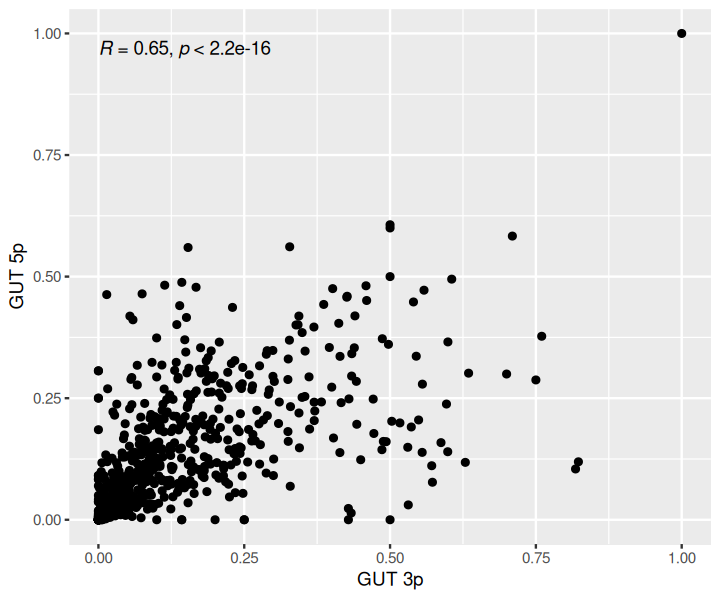

In [246]:
options(repr.plot.width = 6, repr.plot.height = 5)
df_all_data2  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% gut_samples_both)  %>% 
ungroup  %>% 
group_by(participant_id2, timepoint, tissue, layer, annotations2, dataset, smp_id)  %>% 
summarise(freq = mean(freq))  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")  %>%  
ggplot(aes(x = `GUT 3p`, y = `GUT 5p`)) +
geom_point() +
ggpubr::stat_cor()

`summarise()` has grouped output by 'participant_id2', 'timepoint', 'tissue',
'layer', 'annotations2', 'dataset'. You can override using the `.groups`
argument.
Adding missing grouping variables: `participant_id2`, `timepoint`, `tissue`,
`layer`
Warning message:
“Removed 100 rows containing non-finite outside the scale range (`stat_cor()`).”
Warning message:
“Removed 100 rows containing missing values or values outside the scale range
(`geom_point()`).”


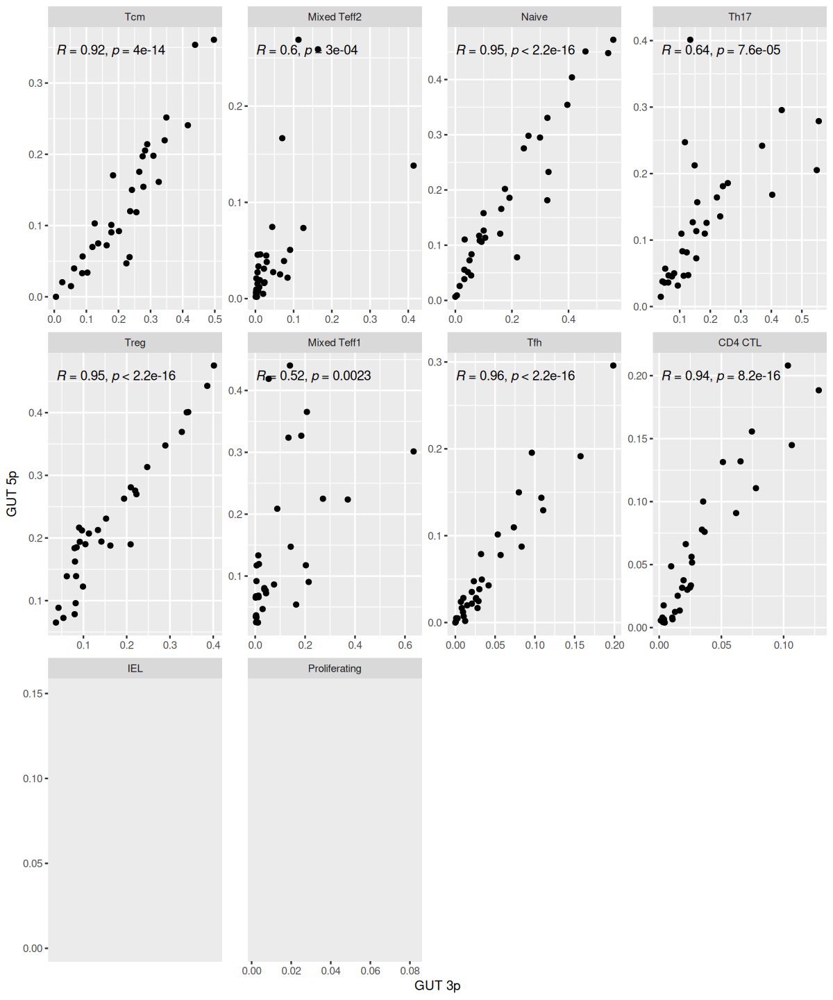

In [247]:
options(repr.plot.width = 10, repr.plot.height = 12)
df_all_data2  %>% 
dplyr::filter(tissue == "ILE" & layer == "LP")  %>% 
mutate(participant_id2 = gsub(participant_id, pattern = "p", replacement = "001-"))  %>% 
mutate(smp_id = paste(participant_id2, timepoint, tissue, layer))  %>% 
dplyr::filter(smp_id %in% gut_samples_both)  %>% 
ungroup  %>% 
group_by(participant_id2, timepoint, tissue, layer, annotations2, dataset, smp_id)  %>% 
summarise(freq = mean(freq))  %>% 
dplyr::select(annotations2, freq, dataset, smp_id)  %>% 
pivot_wider(names_from = "dataset", values_from = "freq")  %>%  
ggplot(aes(x = `GUT 3p`, y = `GUT 5p`)) +
geom_point() +
ggpubr::stat_cor() +
facet_wrap(~annotations2, scales = "free")

# All frequencies - updated metadata

In [248]:
df_all_data  <- df_all_data2  

In [226]:
df_all_data

...1,data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer,dataset,participant_id2
<dbl>,<chr>,<fct>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,001-017_T0_DUO_LP_5p_GEX,CD4 CTL,0.0027700831,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
2,001-017_T0_DUO_LP_5p_GEX,IEL,0.0424746076,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
3,001-017_T0_DUO_LP_5p_GEX,Tcm,0.0027700831,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
4,001-017_T0_DUO_LP_5p_GEX,Mixed Teff1,0.0138504155,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
5,001-017_T0_DUO_LP_5p_GEX,Th17,0.2502308403,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
6,001-017_T0_DUO_LP_5p_GEX,Mixed Teff2,0.6066481994,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
7,001-017_T0_DUO_LP_5p_GEX,Treg,0.0812557710,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
8,001-017_T0_DUO_LP_5p_GEX,Tfh,0.0000000000,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017
9,001-017_T0_DUO_LP_5p_GEX,Naive,0.0000000000,FGID,NM,001-017,T0,DUO,LP,GUT 5p,001-017


In [249]:
df_all_data  %>% dplyr::filter(dataset == "GUT 3p")  %>% pull(participant_id)  %>% unique()

[1] "HE-001-014" "HE-001-023" "HE-001-024" "HE-001-025" "HE-001-026"
 [6] "p002"       "p003"       "p009"       "p010"       "p011"      
[11] "p014"       "p015"       "p016"       "p017"       "p018"      
[16] "p019"       "p020"       "p021"       "p022"       "p023"      
[21] "p024"       "p025"       "p026"       "p027"       "p028"      
[26] "p030"       "p031"       "p032"       "p033"       "p034"      
[31] "p035"       "p036"       "p037"       "p038"       "p040"      
[36] "p041"       "p042"       "p043"       "p044"       "p045"      
[41] "p047"       "p048"       "p049"       "p050"

In [250]:
df_all_data  %>% dplyr::filter(dataset == "GUT 3p")  %>%   pull(diagnosis)  %>% table

.
  CD FGID  HEA  OTH   UC 
 567  540  216   81  189 

In [251]:
pt_3p  <- df_all_data  %>% dplyr::filter(dataset == "GUT 3p")  %>% pull(participant_id2)  %>% unique()

In [252]:
df_all_data  <- df_all_data  %>%
mutate(cohort_gut = if_else(dataset %in% c("GUT 3p", "GUT 5p"),
                            if_else(participant_id2 %in% pt_3p, "Identification", "Validation"),NA_character_))

In [253]:
pt_3p

[1] "HE-014"  "HE-023"  "HE-024"  "HE-025"  "HE-026"  "001-002" "001-003"
 [8] "001-009" "001-010" "001-011" "001-014" "001-015" "001-016" "001-017"
[15] "001-018" "001-019" "001-020" "001-021" "001-022" "001-023" "001-024"
[22] "001-025" "001-026" "001-027" "001-028" "001-030" "001-031" "001-032"
[29] "001-033" "001-034" "001-035" "001-036" "001-037" "001-038" "001-040"
[36] "001-041" "001-042" "001-043" "001-044" "001-045" "001-047" "001-048"
[43] "001-049" "001-050"

In [254]:
df_all_data  %>% dplyr::filter(dataset == "GUT 3p")   %>% group_by(participant_id, cohort_gut)  %>% tally()  %>% 
ungroup  %>% 
dplyr::select(-n)  %>% 
 group_by(cohort_gut)  %>% tally()

cohort_gut,n
<chr>,<int>
Identification,44


In [255]:
df_all_data  %>% dplyr::filter(dataset == "GUT 5p")   %>% group_by(participant_id, cohort_gut)  %>% tally()  %>% 
ungroup  %>% 
dplyr::select(-n)  %>% 
 group_by(cohort_gut)  %>% tally()

cohort_gut,n
<chr>,<int>
Identification,37
Validation,62


### Check if there are changes in the updated metadata

In [256]:
df_all_data$participant_id2  %>% unique()

[1] "001-017" "001-023" "001-028" "001-030" "001-033" "001-034" "001-035"
  [8] "001-043" "001-045" "001-049" "001-050" "001-053" "001-066" "001-077"
 [15] "001-078" "001-079" "001-090" "001-092" "003-043" "001-011" "001-014"
 [22] "001-016" "001-018" "001-019" "001-022" "001-024" "001-027" "001-031"
 [29] "001-032" "001-041" "001-042" "001-048" "001-051" "001-052" "001-058"
 [36] "001-063" "001-064" "001-069" "001-015" "001-055" "001-057" "001-059"
 [43] "001-062" "001-068" "001-009" "001-026" "001-040" "001-044" "001-047"
 [50] "001-070" "001-071" "001-074" "001-082" "001-085" "001-086" "001-089"
 [57] "001-091" "001-094" "001-103" "003-001" "003-002" "003-004" "003-005"
 [64] "003-006" "003-007" "003-008" "003-010" "003-011" "003-012" "001-036"
 [71] "001-038" "003-016" "003-017" "003-024" "003-026" "003-027" "003-030"
 [78] "003-034" "003-036" "003-039" "003-042" "003-046" "003-051" "003-059"
 [85] "003-066" "003-072" "003-074" "003-077" "001-101" "HE-009"  "HE-011" 
 [92] "HE-012"  "HE-014"  "HE-023"  "HE-024"  "HE-025"  "HE-026"  "HE-027" 
 [99] "HE-028"  "001-002" "001-003" "001-010" "001-020" "001-021" "001-025"
[106] "001-037" "003-021"

In [260]:
md_5p_new$antitnf_response  %>% table  

.
 FR  NM NOA  NR  PR 
318 374 245  38 247 

In [262]:

# Function to standardize diagnosis and response
standardize_metadata <- function(df) {
  df %>%
    mutate(
      diagnosis = case_when(
        as.character(diagnosis) %in% c("CD", "HEA", "UC", "FGID") ~
          as.character(diagnosis),
        is.na(diagnosis) ~ NA_character_,
        TRUE ~ "OTH"
      ),
      antitnf_response = case_when(
        as.character(antitnf_response) %in% c("NOA", "NM") ~ "NOA",
        as.character(antitnf_response) %in% c("FR", "RESP") ~ "FR",
        TRUE ~ as.character(antitnf_response)
      )
    )
}

# Unique combinations from both datasets
df1 <- df_all_data %>%
  transmute(
    participant_id = as.character(participant_id2),
    diagnosis,
    antitnf_response
  ) %>%
  standardize_metadata() %>%
  distinct()

df2 <- md_5p_new %>%
  transmute(
    participant_id = as.character(participant_id),
    diagnosis,
    antitnf_response
  ) %>%
  standardize_metadata() %>%
  distinct()

# Check combinations from df_all_data absent in md_5p_new
missing_combinations <- anti_join(
  df1, df2,
  by = c("participant_id", "diagnosis", "antitnf_response"),
  na_matches = "na"
)

cat("Total unique combinations in df_all_data:", nrow(df1), "\n")
cat("Matching combinations:",
    nrow(df1) - nrow(missing_combinations), "\n")
cat("Missing or mismatched combinations:",
    nrow(missing_combinations), "\n\n")

print(missing_combinations, n = Inf)

# Identify reason for each mismatch
mismatch_details <- missing_combinations %>%
  left_join(
    df2 %>%
      group_by(participant_id) %>%
      summarise(
        diagnosis_md = paste(unique(diagnosis), collapse = ", "),
        response_md = paste(unique(antitnf_response), collapse = ", "),
        .groups = "drop"
      ),
    by = "participant_id"
  ) %>%
  mutate(
    issue = case_when(
      is.na(diagnosis_md) ~ "Participant missing in md_5p_new",
      TRUE ~ "Diagnosis and/or response mismatch"
    )
  )

print(mismatch_details, n = Inf)

# Reverse comparison
extra_in_md <- anti_join(
  df2, df1,
  by = c("participant_id", "diagnosis", "antitnf_response"),
  na_matches = "na"
)

cat("\nCombinations in md_5p_new absent from df_all_data:",
    nrow(extra_in_md), "\n")

print(extra_in_md, n = Inf)

Total unique combinations in df_all_data: 113 
Matching combinations: 102 
Missing or mismatched combinations: 11 

# A tibble: 11 × 3
   participant_id diagnosis antitnf_response
   <chr>          <chr>     <chr>           
 1 001-101        OTH       Unknown         
 2 HE-014         HEA       NOA             
 3 001-003        FGID      NOA             
 4 001-020        OTH       NOA             
 5 001-021        OTH       NOA             
 6 001-025        OTH       NOA             
 7 001-042        CD        FR              
 8 001-047        UC        PR              
 9 001-048        CD        NOA             
10 001-032        NA        NA              
11 001-101        NA        NA              
# A tibble: 11 × 6
   participant_id diagnosis antitnf_response diagnosis_md response_md issue     
   <chr>          <chr>     <chr>            <chr>        <chr>       <chr>     
 1 001-101        OTH       Unknown          OTH          NA          Diagnosis…
 2 HE-014         

In [268]:
library(dplyr)

# Function to select one nonmissing value
get_nonmissing <- function(x) {
  x <- unique(as.character(x[!is.na(x)]))

  if (length(x) == 0) {
    return(NA_character_)
  }

  if (length(x) > 1) {
    stop("Conflicting nonmissing values found!")
  }

  x[1]
}

# 1. Prepare reference metadata
md_reference_clean <- md_5p_new %>%
  dplyr::transmute(
    participant_id = as.character(participant_id),
    diagnosis = as.character(diagnosis),
    antitnf_response = as.character(antitnf_response)
  ) %>%
  standardize_metadata() %>%
  dplyr::group_by(participant_id) %>%
  dplyr::summarise(
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    .groups = "drop"
  )

# Check reference
print(md_reference_clean, n = Inf)

# 2. Update df_all_data
df_all_data_corrected <- df_all_data %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2)
  ) %>%
  standardize_metadata() %>%
  dplyr::left_join(
    md_reference_clean %>%
      dplyr::rename(
        diagnosis_ref = diagnosis,
        response_ref = antitnf_response
      ),
    by = c("participant_id2" = "participant_id")
  ) %>%
  dplyr::mutate(
    diagnosis = dplyr::coalesce(diagnosis_ref, diagnosis),
    antitnf_response = dplyr::coalesce(
      response_ref, antitnf_response
    )
  ) %>%
  dplyr::select(-diagnosis_ref, -response_ref)

# 3. Verify row count
stopifnot(nrow(df_all_data_corrected) == nrow(df_all_data))

# 4. Check actual mismatches, ignoring missing reference values
remaining_mismatches <- df_all_data_corrected %>%
  dplyr::inner_join(
    md_reference_clean %>%
      dplyr::rename(
        diagnosis_ref = diagnosis,
        response_ref = antitnf_response
      ),
    by = c("participant_id2" = "participant_id")
  ) %>%
  dplyr::filter(
    (!is.na(diagnosis_ref) & 
       (is.na(diagnosis) | diagnosis != diagnosis_ref)) |
    (!is.na(response_ref) &
       (is.na(antitnf_response) |
          antitnf_response != response_ref))
  )

cat("Remaining mismatches:", nrow(remaining_mismatches), "\n")
print(remaining_mismatches, n = Inf)

# A tibble: 116 × 3
    participant_id diagnosis antitnf_response
    <chr>          <chr>     <chr>           
  1 001-002        FGID      NOA             
  2 001-004        CD        FR              
  3 001-006        UC        NOA             
  4 001-009        FGID      NOA             
  5 001-010        CD        PR              
  6 001-011        CD        FR              
  7 001-014        CD        FR              
  8 001-015        UC        NOA             
  9 001-016        CD        FR              
 10 001-017        FGID      NOA             
 11 001-018        CD        PR              
 12 001-019        CD        NOA             
 13 001-022        CD        FR              
 14 001-023        FGID      NOA             
 15 001-024        CD        PR              
 16 001-026        CD        NOA             
 17 001-027        CD        NOA             
 18 001-028        FGID      NOA             
 19 001-030        FGID      NOA             
 20 001-031   

In [273]:
df_all_data <- df_all_data_corrected

### Plot diagnosis

In [277]:
df_all_data  %>% 
dplyr::filter(dataset %in% c("GUT 3p", "GUT 5p"))  %>% 
group_by(diagnosis, participant_id2, cohort_gut)  %>% tally()    %>% 
ungroup  %>% 
group_by(diagnosis, cohort_gut)  %>% 
tally()


diagnosis,cohort_gut,n
<chr>,<chr>,<int>
CD,Identification,16
CD,Validation,26
FGID,Identification,16
FGID,Validation,12
HEA,Identification,4
HEA,Validation,5
OTH,Identification,4
OTH,Validation,4
UC,Identification,4


In [276]:
df_all_data  %>% 
dplyr::filter(dataset %in% c("GUT 3p"), cohort_gut == "Identification")  %>% pull(participant_id2)  %>% unique()

[1] "HE-014"  "HE-023"  "HE-024"  "HE-025"  "HE-026"  "001-002" "001-003"
 [8] "001-009" "001-010" "001-011" "001-014" "001-015" "001-016" "001-017"
[15] "001-018" "001-019" "001-020" "001-021" "001-022" "001-023" "001-024"
[22] "001-025" "001-026" "001-027" "001-028" "001-030" "001-031" "001-032"
[29] "001-033" "001-034" "001-035" "001-036" "001-037" "001-038" "001-040"
[36] "001-041" "001-042" "001-043" "001-044" "001-045" "001-047" "001-048"
[43] "001-049" "001-050"


GUT 3p | DUO EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    3 Identification GUT 3p  DUO    EPI  
2 FGID                   5 Identification GUT 3p  DUO    EPI  
3 UC                     3 Identification GUT 3p  DUO    EPI  
4 CD                     4 Identification GUT 3p  DUO    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               3     5     3     4
 2 Mixed Teff2       3     5     3     4
 3 Naive             3     5     3     4
 4 Th17              3     5     3     4
 5 Treg              3     5     3     4
 6 Mixed Teff1       3     5     3     4
 7 Tfh               3     5     3     4
 8 CD4 CTL           3     5     3     4
 9 IEL               0     0     0     0
10 Proliferating     3     5     3     4
11 2                 0     0     0     0
12 4                 0     0     

Warning message in wilcox.test.default(c(52.1739130434783, 20, 33.0935251798561, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(52.1739130434783, 20, 33.0935251798561, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(50, 5, 25), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(16.6666666666667, 14.2857142857143, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(0, 0, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(13.0434782608696, 0, 23.7410071942446, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(13.0434782608696, 0, 23.7410071942446, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(13.0434782608696, 0, 23.7410071942446, :
“cannot compute exact p-value with ties

Warning message in wilcox.test.default(c(4.34782608695652, 0, 0, 40), c(0, 7.5, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(4.34782608695652, 0, 0, 40), c(33.3333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(4.34782608695652, 0, 0, 40), c(0, 0, 100:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 2.87769784172662, 0), c(0, 2.5, 0:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 2.87769784172662, 0), c(16.6666666666667, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 2.87769784172662, 0), c(0, 9.09090909090909, :
“cannot compute exact p-value with ties”



GUT 5p | DUO EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    5 Validation GUT 5p  DUO    EPI  
2 FGID                   9 Validation GUT 5p  DUO    EPI  
3 UC                     5 Validation GUT 5p  DUO    EPI  
4 CD                    21 Validation GUT 5p  DUO    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               5     9     5    21
 2 Mixed Teff2       5     9     5    21
 3 Naive             5     9     5    21
 4 Th17              5     9     5    21
 5 Treg              5     9     5    21
 6 Mixed Teff1       5     9     5    21
 7 Tfh               5     9     5    21
 8 CD4 CTL           5     9     5    21
 9 IEL               5     9     5    21
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1            

Warning message in wilcox.test.default(c(0, 0, 0, 0, 11.8918918918919, 11.0738255033557, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 11.8918918918919, 11.0738255033557, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 11.8918918918919, 11.0738255033557, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.896860986547085, 0, 0, 1.08108108108108, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.896860986547085, 0, 0, 1.08108108108108, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.896860986547085, 0, 0, 1.08108108108108, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.896860986547085, 0, 0, 5.94594594594595, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.896860986547085, 0, 0, 5.9459459459459

Warning message in wilcox.test.default(c(0, 1.79372197309417, 0, 0, 2.16216216216216, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 1.79372197309417, 0, 0, 2.16216216216216, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 3.58744394618834, 66.6666666666667, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 3.58744394618834, 66.6666666666667, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 3.58744394618834, 66.6666666666667, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 1.34529147982063, 0, 0, 1.08108108108108, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 1.34529147982063, 0, 0, 1.08108108108108, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 1.34529147982063, 0, 0, 1.08108108108108, :
“cannot compute exact p-val


GUT 3p | DUO LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    4 Identification GUT 3p  DUO    LP   
2 FGID                  16 Identification GUT 3p  DUO    LP   
3 UC                     4 Identification GUT 3p  DUO    LP   
4 CD                    14 Identification GUT 3p  DUO    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               4    16     4    14
 2 Mixed Teff2       4    16     4    14
 3 Naive             4    16     4    14
 4 Th17              4    16     4    14
 5 Treg              4    16     4    14
 6 Mixed Teff1       4    16     4    14
 7 Tfh               4    16     4    14
 8 CD4 CTL           4    16     4    14
 9 IEL               0     0     0     0
10 Proliferating     4    16     4    14
11 2                 0     0     0     0
12 4                 0     0     0

Warning message in wilcox.test.default(c(1.82203389830508, 0.161864681126578, 0.892060660124889, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.720338983050847, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.720338983050847, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.423728813559322, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.82203389830508, 0.1

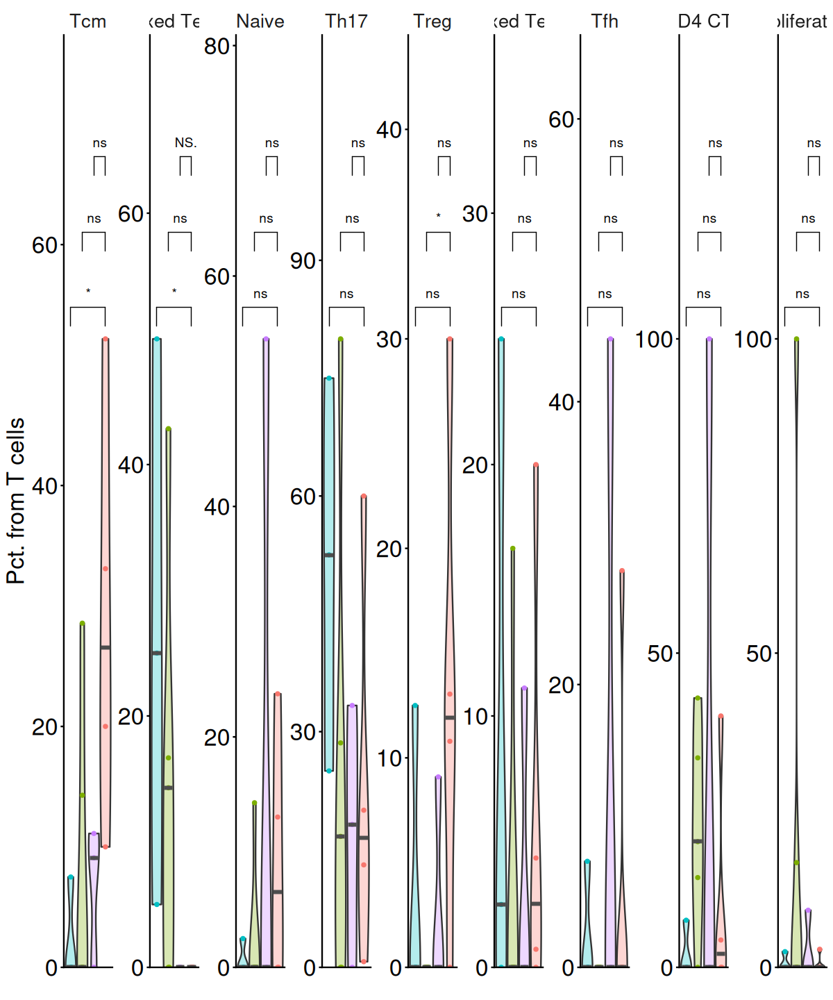

Warning message in wilcox.test.default(c(1.82203389830508, 0.161864681126578, 0.892060660124889, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.847457627118644, 0.129491744901263, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.720338983050847, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.720338983050847, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.423728813559322, 0.356102298478472, 0.178412132024978, :
“cannot compute exact p-value with ties”



GUT 5p | DUO LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    5 Validation GUT 5p  DUO    LP   
2 FGID                  11 Validation GUT 5p  DUO    LP   
3 UC                     5 Validation GUT 5p  DUO    LP   
4 CD                    24 Validation GUT 5p  DUO    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               5    11     5    24
 2 Mixed Teff2       5    11     5    24
 3 Naive             5    11     5    24
 4 Th17              5    11     5    24
 5 Treg              5    11     5    24
 6 Mixed Teff1       5    11     5    24
 7 Tfh               5    11     5    24
 8 CD4 CTL           5    11     5    24
 9 IEL               5    11     5    24
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1             

Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.4651162790698, 13.3333333333333, 10.8452950558214, :
“cannot compute exact p-value with ties”
Warning message in wilcox.te

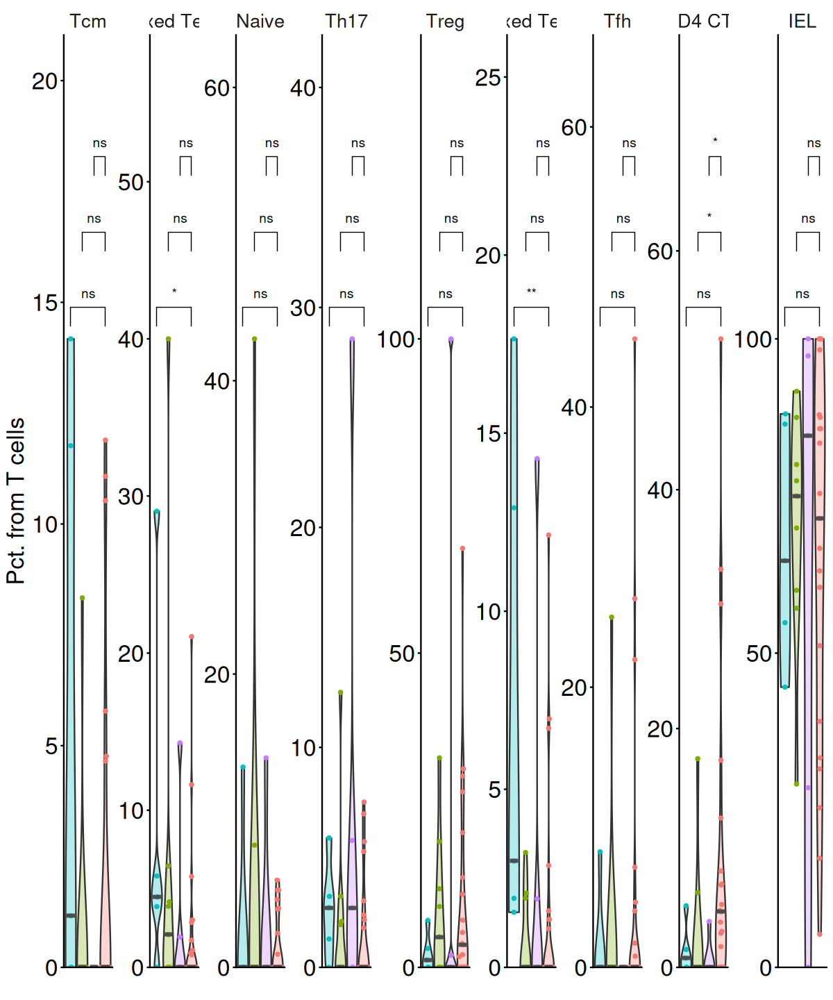

Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.15946843853821, 1.11111111111111, 1.59489633173844, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.830564784053156, 1.11111111111111, 0.637958532695375, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.4651162790698, 13.3333333333333, 10.8452950558214, :
“cannot compute exact p-value with ties”
Warning message in wilcox.te


GUT 3p | COL EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    2 Identification GUT 3p  COL    EPI  
2 FGID                   6 Identification GUT 3p  COL    EPI  
3 UC                     3 Identification GUT 3p  COL    EPI  
4 CD                     4 Identification GUT 3p  COL    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               2     6     3     4
 2 Mixed Teff2       2     6     3     4
 3 Naive             2     6     3     4
 4 Th17              2     6     3     4
 5 Treg              2     6     3     4
 6 Mixed Teff1       2     6     3     4
 7 Tfh               2     6     3     4
 8 CD4 CTL           2     6     3     4
 9 IEL               0     0     0     0
10 Proliferating     2     6     3     4
11 2                 0     0     0     0
12 4                 0     0     

Warning message in wilcox.test.default(c(38.6440677966102, 33.3333333333333, 25, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0, 0), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.1864406779661, 33.3333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.1864406779661, 33.3333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.1864406779661, 0, 50, 0), c(0, 11.1111111111111:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.1864406779661, 0, 50, 0), c(33.3333333333333, :
“cannot compute exac

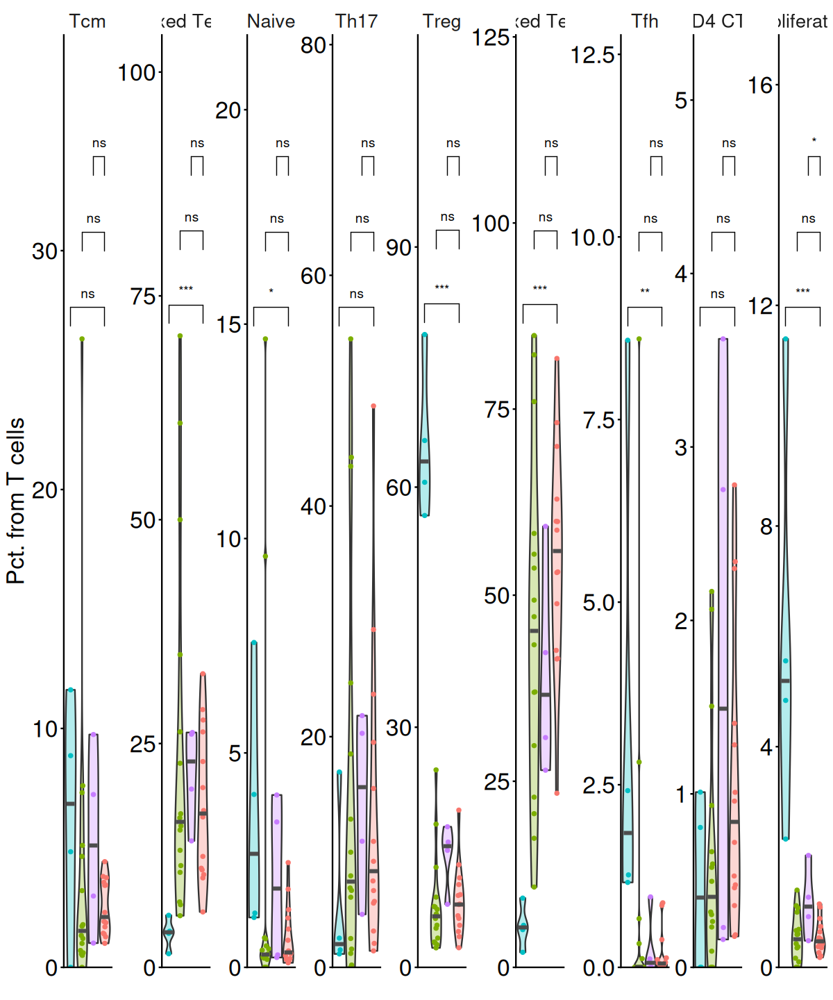

Warning message in wilcox.test.default(c(38.6440677966102, 33.3333333333333, 25, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.169491525423729, 0, 0, 0), c(0, 0, 0), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.1864406779661, 33.3333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.1864406779661, 33.3333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.1864406779661, 0, 50, 0), c(0, 11.1111111111111:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.1864406779661, 0, 50, 0), c(33.3333333333333, :
“cannot compute exac


GUT 5p | COL EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    3 Validation GUT 5p  COL    EPI  
2 FGID                   7 Validation GUT 5p  COL    EPI  
3 UC                    12 Validation GUT 5p  COL    EPI  
4 CD                    18 Validation GUT 5p  COL    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               3     7    12    18
 2 Mixed Teff2       3     7    12    18
 3 Naive             3     7    12    18
 4 Th17              3     7    12    18
 5 Treg              3     7    12    18
 6 Mixed Teff1       3     7    12    18
 7 Tfh               3     7    12    18
 8 CD4 CTL           3     7    12    18
 9 IEL               3     7    12    18
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1            

Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 18.1818181818182, 25.5639097744361, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 18.18

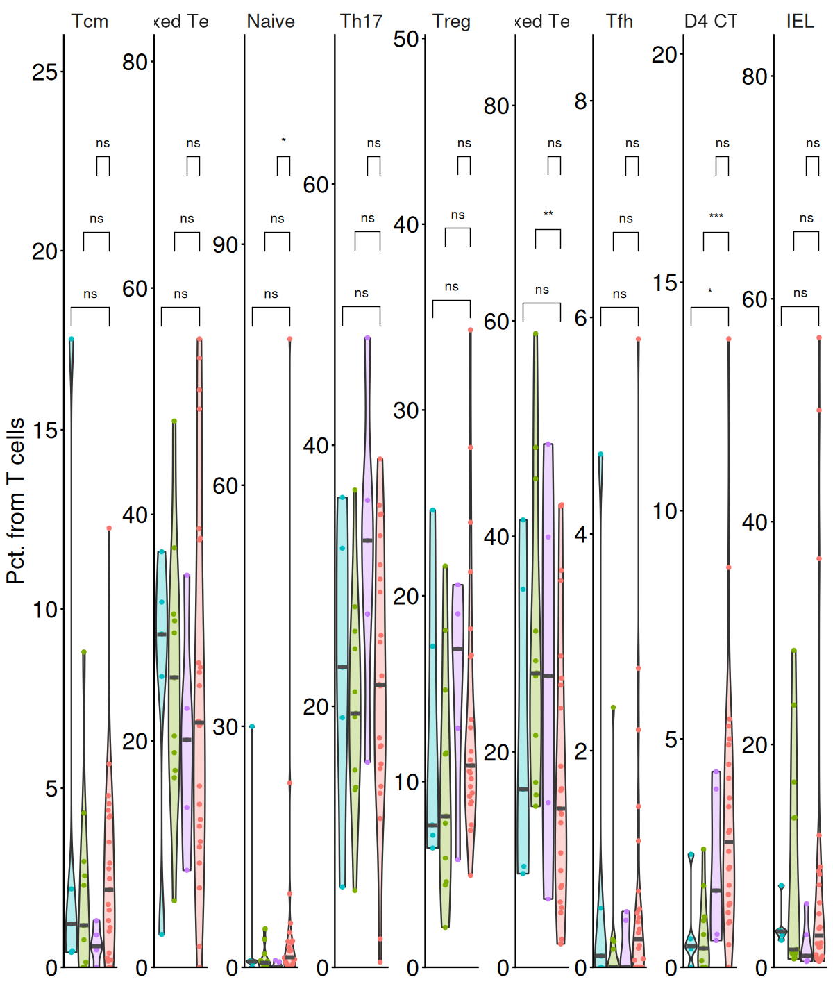

Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(10.3448275862069, 22.2222222222222, 27.2727272727273, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 5.26315789473684, 0, 0, 0.574712643678161, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 18.1818181818182, 25.5639097744361, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 18.18


GUT 3p | COL LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    4 Identification GUT 3p  COL    LP   
2 FGID                  16 Identification GUT 3p  COL    LP   
3 UC                     4 Identification GUT 3p  COL    LP   
4 CD                    15 Identification GUT 3p  COL    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               4    16     4    15
 2 Mixed Teff2       4    16     4    15
 3 Naive             4    16     4    15
 4 Th17              4    16     4    15
 5 Treg              4    16     4    15
 6 Mixed Teff1       4    16     4    15
 7 Tfh               4    16     4    15
 8 CD4 CTL           4    16     4    15
 9 IEL               0     0     0     0
10 Proliferating     4    16     4    15
11 2                 0     0     0     0
12 4                 0     0     0

Warning message in wilcox.test.default(c(2.76402640264026, 15.0943396226415, 3.7914691943128, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(12.5412541254125, 1.22086570477248, 4.062288422478, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.76402640264026, 15.0943396226415, 3.7914691943128, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(12.5412541254125, 1.22086570477248, 4.062288422478, :
“cannot compute exact p-value with ties”


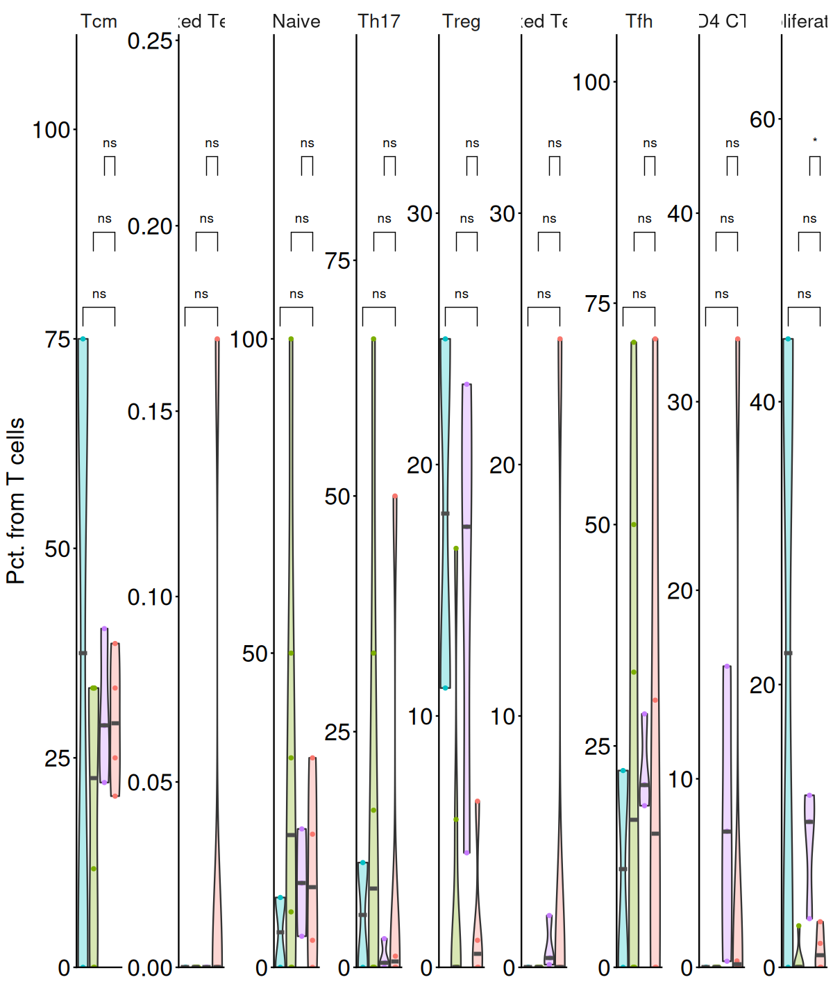

Warning message in wilcox.test.default(c(2.76402640264026, 15.0943396226415, 3.7914691943128, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(12.5412541254125, 1.22086570477248, 4.062288422478, :
“cannot compute exact p-value with ties”



GUT 5p | COL LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    5 Validation GUT 5p  COL    LP   
2 FGID                  12 Validation GUT 5p  COL    LP   
3 UC                    13 Validation GUT 5p  COL    LP   
4 CD                    26 Validation GUT 5p  COL    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               5    12    13    26
 2 Mixed Teff2       5    12    13    26
 3 Naive             5    12    13    26
 4 Th17              5    12    13    26
 5 Treg              5    12    13    26
 6 Mixed Teff1       5    12    13    26
 7 Tfh               5    12    13    26
 8 CD4 CTL           5    12    13    26
 9 IEL               5    12    13    26
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1             

Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(16.2346521145975, 16.0919540229885, 1.19047619047619, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.682128240109141, 0.383141762452107, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.t

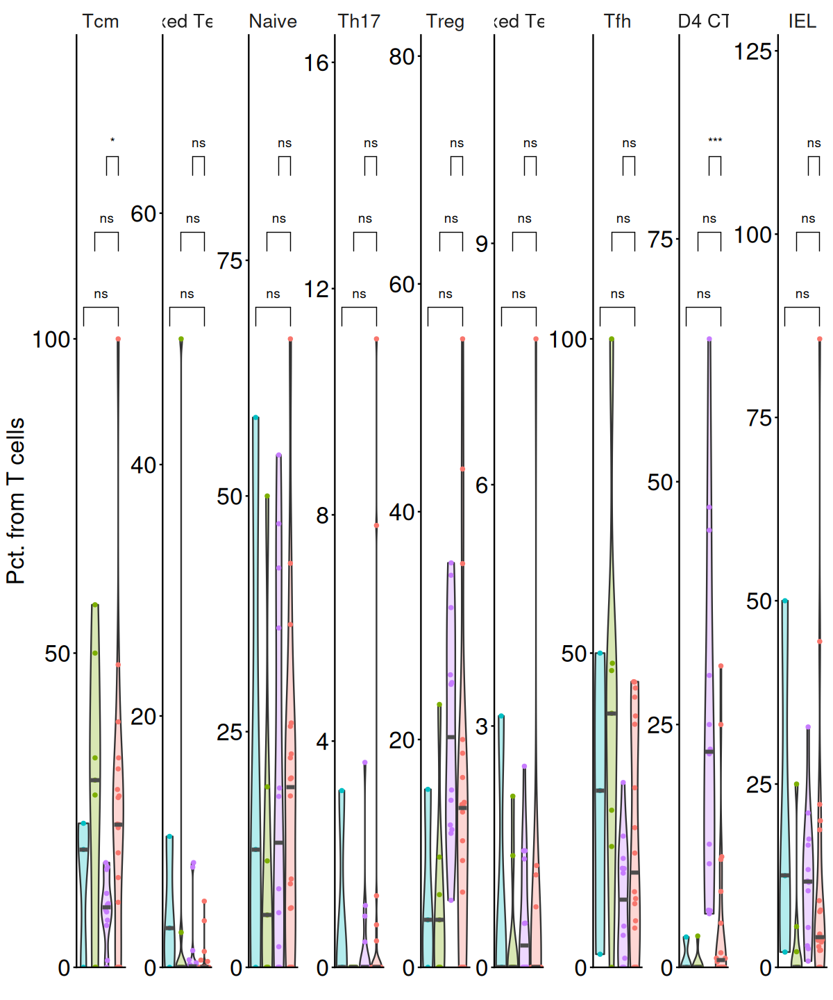

Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.545702592087312, 12.2605363984674, 1.78571428571429, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(16.2346521145975, 16.0919540229885, 1.19047619047619, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.682128240109141, 0.383141762452107, 1.78571428571429, :
“cannot compute exact p-value with ties”



GUT 3p | ILE EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    2 Identification GUT 3p  ILE    EPI  
2 FGID                   3 Identification GUT 3p  ILE    EPI  
3 UC                     3 Identification GUT 3p  ILE    EPI  
4 CD                     4 Identification GUT 3p  ILE    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               2     3     3     4
 2 Mixed Teff2       2     3     3     4
 3 Naive             2     3     3     4
 4 Th17              2     3     3     4
 5 Treg              2     3     3     4
 6 Mixed Teff1       2     3     3     4
 7 Tfh               2     3     3     4
 8 CD4 CTL           2     3     3     4
 9 IEL               0     0     0     0
10 Proliferating     2     3     3     4
11 2                 0     0     0     0
12 4                 0     0     

Warning message in wilcox.test.default(c(42.2413793103448, 16.6666666666667, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(2.56410256410256, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(0, 0, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(0.367647058823529, 0, 0), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(18.1034482758621, 41.6666666666667, 50, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(18.1034482758621, 41.6666666666667, 50, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.48275862068965, 8.33333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.48275862068965, 8.33333333333333, 0, :
“cannot compute exact p-value with ties

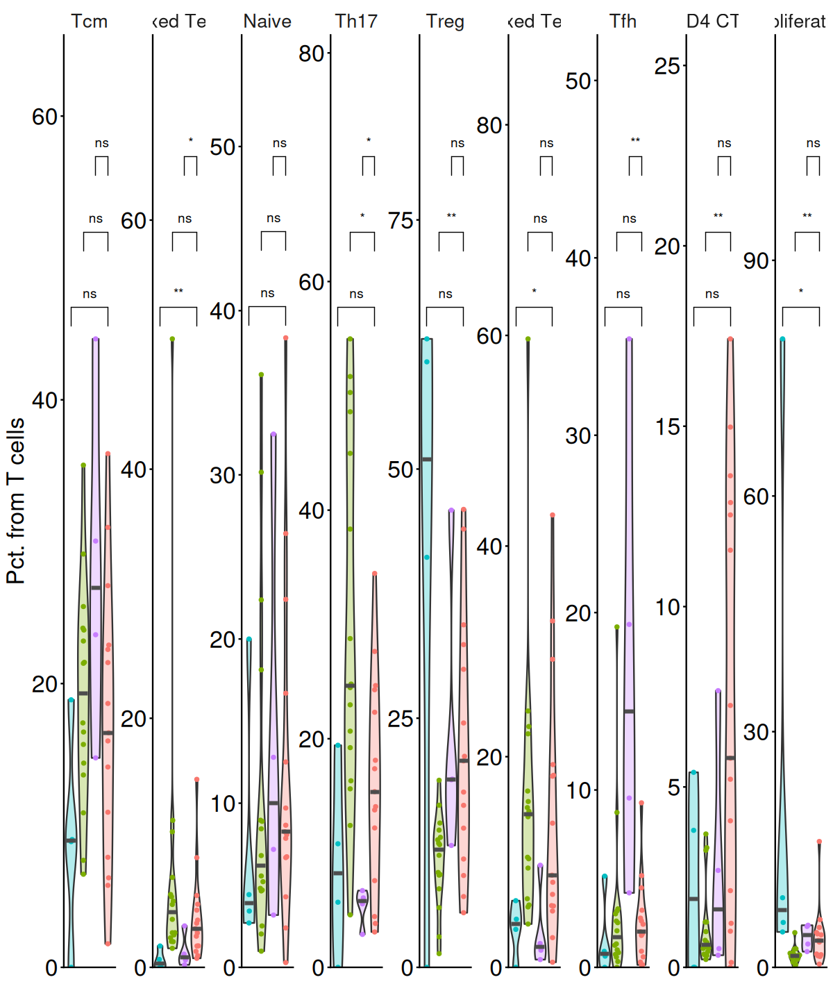

Warning message in wilcox.test.default(c(42.2413793103448, 16.6666666666667, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(2.56410256410256, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(0, 0, 0), paired = FALSE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0), c(0.367647058823529, 0, 0), :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(18.1034482758621, 41.6666666666667, 50, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(18.1034482758621, 41.6666666666667, 50, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.48275862068965, 8.33333333333333, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.48275862068965, 8.33333333333333, 0, :
“cannot compute exact p-value with ties


GUT 5p | ILE EPI 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    5 Validation GUT 5p  ILE    EPI  
2 FGID                   9 Validation GUT 5p  ILE    EPI  
3 UC                    11 Validation GUT 5p  ILE    EPI  
4 CD                    20 Validation GUT 5p  ILE    EPI  
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               5     9    11    20
 2 Mixed Teff2       5     9    11    20
 3 Naive             5     9    11    20
 4 Th17              5     9    11    20
 5 Treg              5     9    11    20
 6 Mixed Teff1       5     9    11    20
 7 Tfh               5     9    11    20
 8 CD4 CTL           5     9    11    20
 9 IEL               5     9    11    20
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1            

Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.04977375565611, 18.3381088825215, 75, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.04977375565611, 18.3381

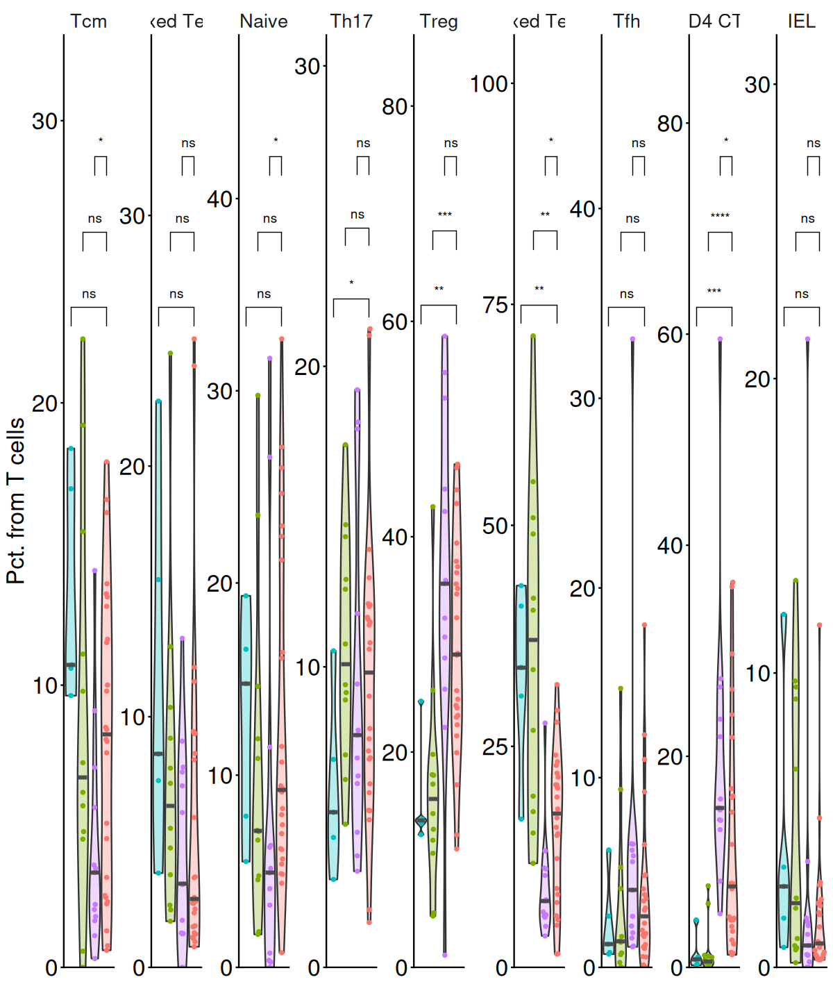

Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(2.71493212669683, 31.5186246418338, 8.33333333333333, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.80995475113122, 0, 0, 0, 0, 2.77777777777778, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.04977375565611, 18.3381088825215, 75, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.04977375565611, 18.3381


GUT 3p | ILE LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut     dataset tissue layer
  <fct>              <int> <chr>          <chr>   <chr>  <chr>
1 HEA                    3 Identification GUT 3p  ILE    LP   
2 FGID                  14 Identification GUT 3p  ILE    LP   
3 UC                     4 Identification GUT 3p  ILE    LP   
4 CD                    14 Identification GUT 3p  ILE    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               3    14     4    14
 2 Mixed Teff2       3    14     4    14
 3 Naive             3    14     4    14
 4 Th17              3    14     4    14
 5 Treg              3    14     4    14
 6 Mixed Teff1       3    14     4    14
 7 Tfh               3    14     4    14
 8 CD4 CTL           3    14     4    14
 9 IEL               0     0     0     0
10 Proliferating     3    14     4    14
11 2                 0     0     0     0
12 4                 0     0     0

Warning message in wilcox.test.default(c(1.04761904761905, 2.32828870779977, 3.32986472424558, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.04761904761905, 2.32828870779977, 3.32986472424558, :
“cannot compute exact p-value with ties”


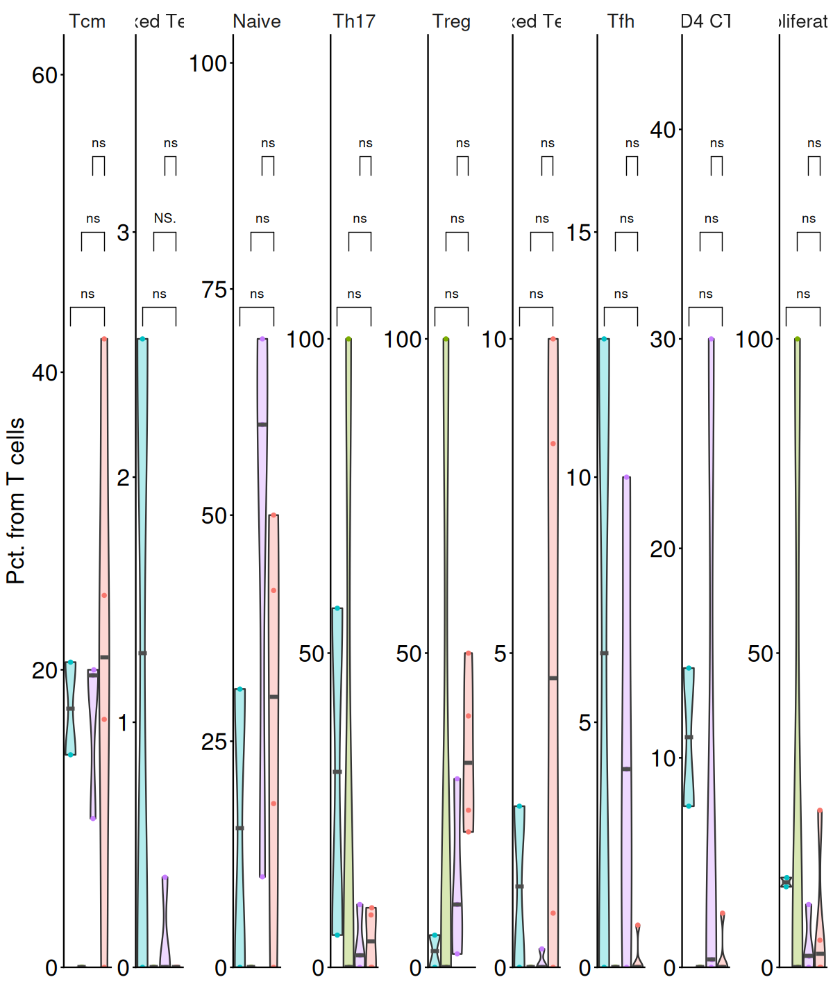

Warning message in wilcox.test.default(c(1.04761904761905, 2.32828870779977, 3.32986472424558, :
“cannot compute exact p-value with ties”



GUT 5p | ILE LP 
# A tibble: 4 × 6
  diagnosis n_participants cohort_gut dataset tissue layer
  <fct>              <int> <chr>      <chr>   <chr>  <chr>
1 HEA                    5 Validation GUT 5p  ILE    LP   
2 FGID                  12 Validation GUT 5p  ILE    LP   
3 UC                    15 Validation GUT 5p  ILE    LP   
4 CD                    25 Validation GUT 5p  ILE    LP   
# A tibble: 24 × 5
   annotations2    HEA  FGID    UC    CD
   <fct>         <int> <int> <int> <int>
 1 Tcm               5    12    15    25
 2 Mixed Teff2       5    12    15    25
 3 Naive             5    12    15    25
 4 Th17              5    12    15    25
 5 Treg              5    12    15    25
 6 Mixed Teff1       5    12    15    25
 7 Tfh               5    12    15    25
 8 CD4 CTL           5    12    15    25
 9 IEL               5    12    15    25
10 Proliferating     0     0     0     0
11 2                 0     0     0     0
12 4                 0     0     0     0
13 1             

Warning message in wilcox.test.default(c(3.37423312883436, 18.3836084234491, 12.2516556291391, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(7.66871165644172, 43.5970404097894, 17.5496688741722, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.511247443762781, 4.55321570859419, 4.3046357615894, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.511247443762781, 4.55321570859419, 4.3046357615894, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(16.5644171779141, 6.37450199203187, 3.64238410596026, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 0.910643141718839, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 0.910643141718839, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 

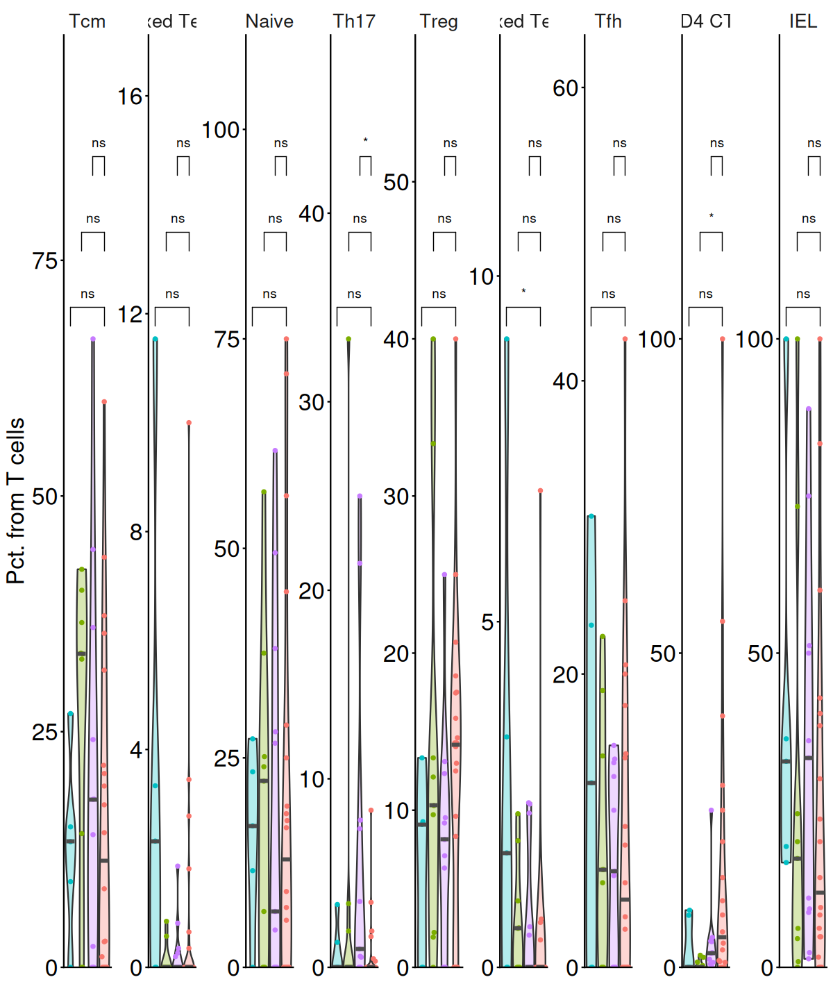

Warning message in wilcox.test.default(c(3.37423312883436, 18.3836084234491, 12.2516556291391, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(7.66871165644172, 43.5970404097894, 17.5496688741722, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.511247443762781, 4.55321570859419, 4.3046357615894, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.511247443762781, 4.55321570859419, 4.3046357615894, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(16.5644171779141, 6.37450199203187, 3.64238410596026, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 0.910643141718839, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 0.910643141718839, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.920245398773006, 

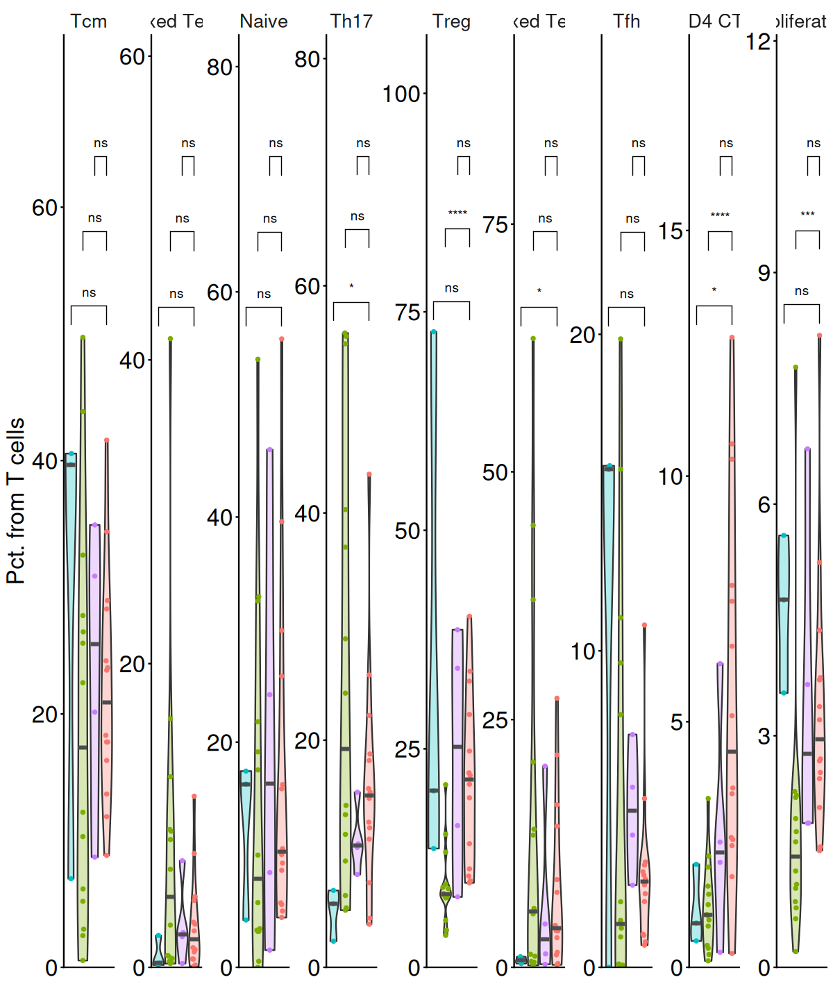

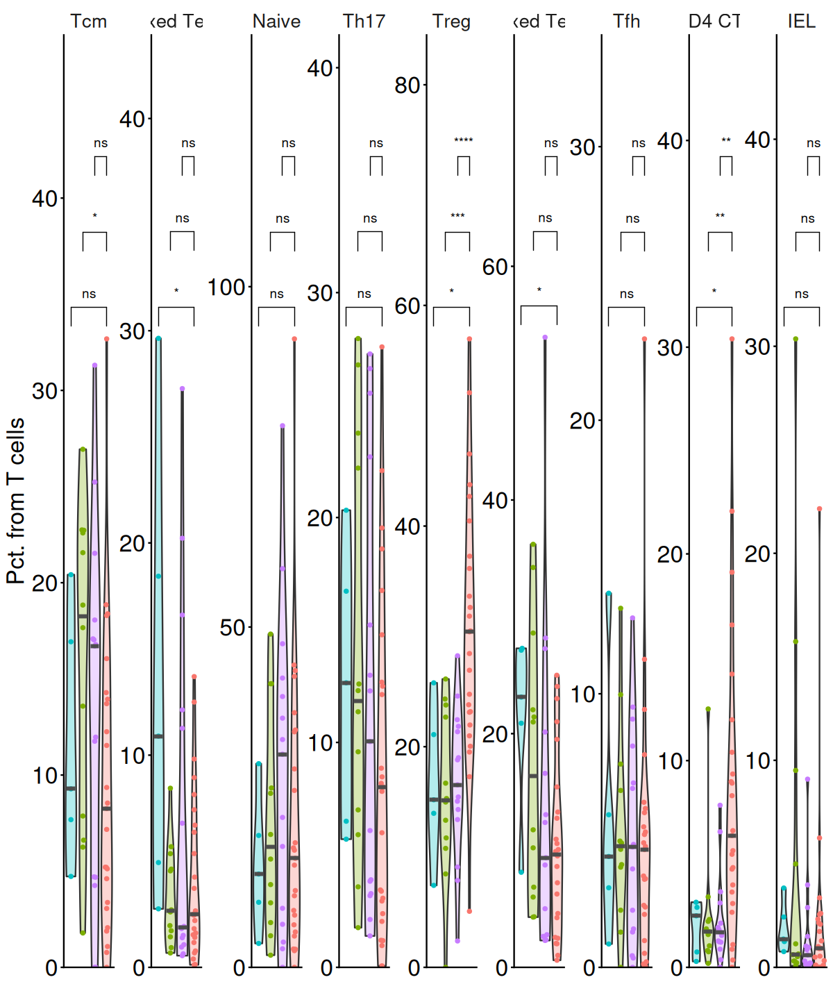

In [278]:

out_dir <- paste0(
  "figures/cd4_freq_violin/diagnosis_",
  format(Sys.time(), "%Y%m%d_%H%M%S")
)

dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
# Diagnosis order and colors
diagnosis_levels <- c("HEA", "FGID", "UC", "CD")

diagnosis_colors <- setNames(
  scales::hue_pal()(4)[c(3, 2, 4, 1)],
  diagnosis_levels
)

# Cohort/dataset combinations
cohorts <- tibble(
  cohort_gut = c("Identification", "Validation"),
  dataset = c("GUT 3p", "GUT 5p"),
  prefix = c("3p", "5p")
)

# All tissue/layer combinations present in the selected data
tissue_layers <- df_all_data %>%
  semi_join(cohorts, by = c("cohort_gut", "dataset")) %>%
  filter(
    diagnosis %in% diagnosis_levels,
    timepoint == "T0",
    !is.na(tissue),
    !is.na(layer)
  ) %>%
  distinct(tissue, layer)

all_counts <- list()

for (i in seq_len(nrow(tissue_layers))) {

  tissue_i <- tissue_layers$tissue[i]
  layer_i <- tissue_layers$layer[i]

  for (j in seq_len(nrow(cohorts))) {

    cohort_i <- cohorts$cohort_gut[j]
    dataset_i <- cohorts$dataset[j]
    prefix_i <- cohorts$prefix[j]

    # Filter data
    df_filt <- df_all_data %>%
      filter(
        cohort_gut == cohort_i,
        dataset == dataset_i,
        tissue == tissue_i,
        layer == layer_i,
        timepoint == "T0",
        diagnosis %in% diagnosis_levels,
        !is.na(annotations2),
        !is.na(freq)
      ) %>%
      mutate(
        diagnosis = factor(
          diagnosis,
          levels = diagnosis_levels
        ),
        freq_pct = freq * 100
      )

    if (nrow(df_filt) == 0) next

    # File prefix
    file_prefix <- paste(
      prefix_i, tissue_i, layer_i,
      sep = "_"
    )

    # Save source data
    write_csv(
      df_filt,
      file.path(out_dir, paste0(file_prefix, "_source.csv"))
    )

    # Participant counts by diagnosis
    participant_counts <- df_filt %>%
      group_by(diagnosis, .drop = FALSE) %>%
      summarise(
        n_participants = n_distinct(
          participant_id, na.rm = TRUE
        ),
        .groups = "drop"
      ) %>%
      mutate(
        cohort_gut = cohort_i,
        dataset = dataset_i,
        tissue = tissue_i,
        layer = layer_i
      )

    cat("\n====================================\n")
    cat(dataset_i, "|", tissue_i, layer_i, "\n")
    cat("====================================\n")
    print(participant_counts)

    # Participant counts per annotation
    annotation_counts <- df_filt %>%
      group_by(annotations2, diagnosis, .drop = FALSE) %>%
      summarise(
        n_participants = n_distinct(
          participant_id, na.rm = TRUE
        ),
        .groups = "drop"
      )

    print(
      pivot_wider(
        annotation_counts,
        names_from = diagnosis,
        values_from = n_participants
      ),
      n = Inf
    )

    write_csv(
      annotation_counts,
      file.path(out_dir, paste0(file_prefix, "_counts.csv"))
    )

    all_counts[[file_prefix]] <- participant_counts

    # Plot
    p <- ggplot(
      df_filt,
      aes(x = diagnosis, y = freq_pct)
    ) +
      geom_violin(
        aes(fill = diagnosis),
        alpha = 0.3,
        scale = "width"
      ) +
      ggbeeswarm::geom_beeswarm(
        aes(color = diagnosis),
        size = 1.5,
        cex = 2,
        shape = 16,
        corral = "random"
      ) +
      stat_summary(
        fun = "median",
        geom = "crossbar",
        width = 0.75,
        color = "grey30"
      ) +
      facet_wrap(
        ~annotations2,
        scales = "free_y",
        ncol = 11
      ) +
      ggpubr::stat_compare_means(
        comparisons = list(
          c("CD", "HEA"),
          c("CD", "FGID"),
          c("CD", "UC")
        ),
        label = "p.signif"
      ) +
      scale_fill_manual(values = diagnosis_colors) +
      scale_color_manual(values = diagnosis_colors) +
      scale_y_continuous(
        limits = c(0, NA),
        expand = expansion(mult = c(0, 0.15))
      ) +
      labs(
        x = "",
        y = "Pct. from T cells"
      ) +
      theme_classic() +
      theme(
        strip.background = element_blank(),
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank(),
        legend.position = "none"
      ) +
      ggtheme()

    # Save SVG
    ggsave(
      filename = file.path(
        out_dir, paste0(file_prefix, ".svg")
      ),
      plot = p,
      width = 20,
      height = 4,
      units = "in"
    )

    # Save PNG
    ggsave(
      filename = file.path(
        out_dir, paste0(file_prefix, ".png")
      ),
      plot = p,
      width = 20,
      height = 4,
      units = "in",
      dpi = 300
    )

    print(p)
  }
}

# Save combined participant counts
write_csv(
  bind_rows(all_counts),
  file.path(out_dir, "all_participant_counts.csv")
)


### Response


3p | COL LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 3p           COL    LP   
2 FR                            5 3p           COL    LP   
3 PR                            7 3p           COL    LP   

5p | COL LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           6 5p           COL    LP   
2 FR                           14 5p           COL    LP   
3 PR                            6 5p           COL    LP   

all5p | COL LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           9 all5p        COL    LP   
2 FR                           19 all5p        COL    LP   
3 PR                           11 all5p        COL    LP   


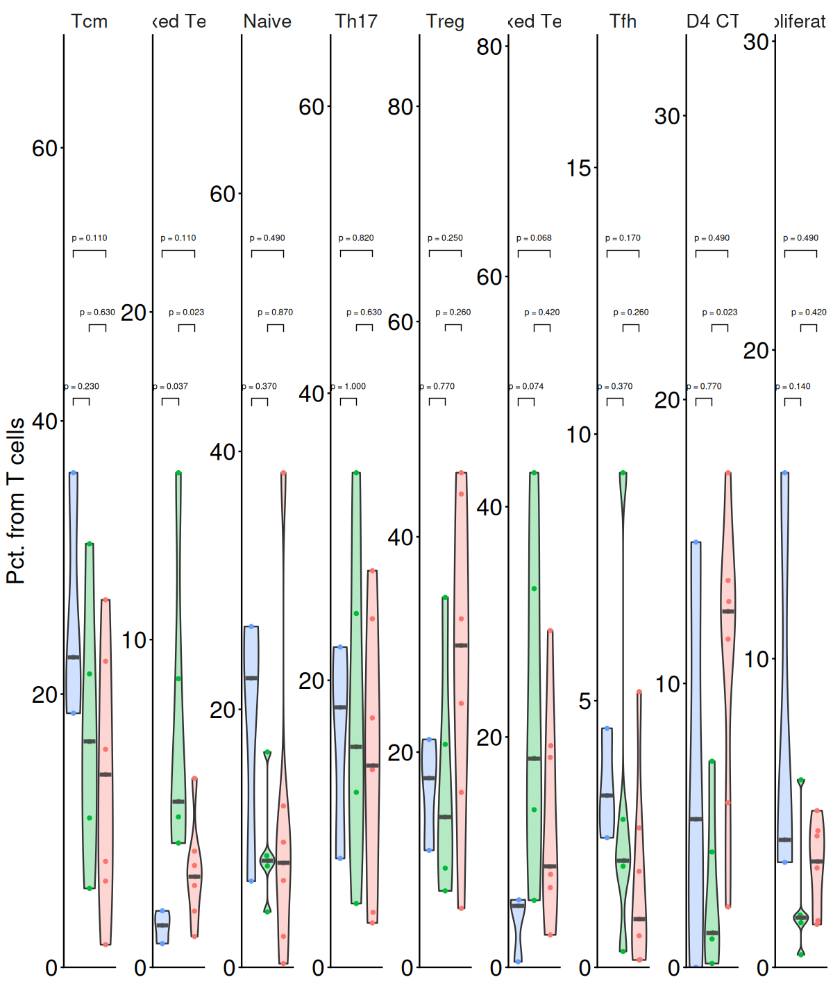


all | COL LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           9 all          COL    LP   
2 FR                           19 all          COL    LP   
3 PR                           14 all          COL    LP   


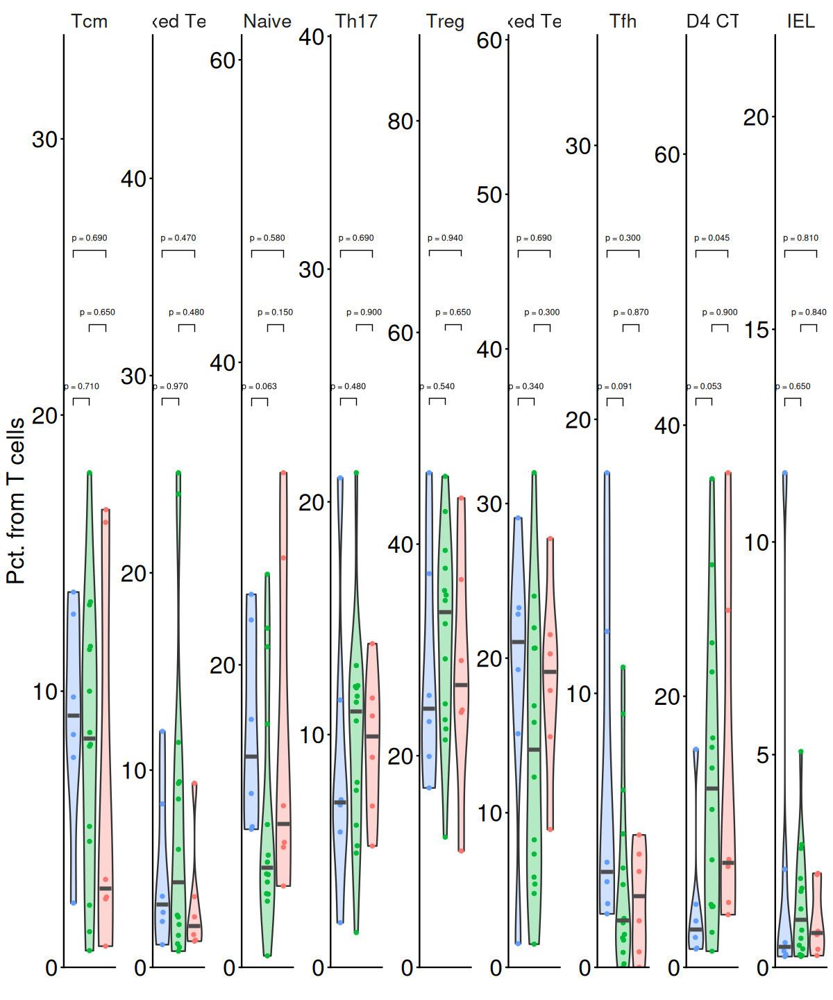


3p | DUO LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           2 3p           DUO    LP   
2 FR                            4 3p           DUO    LP   
3 PR                            8 3p           DUO    LP   


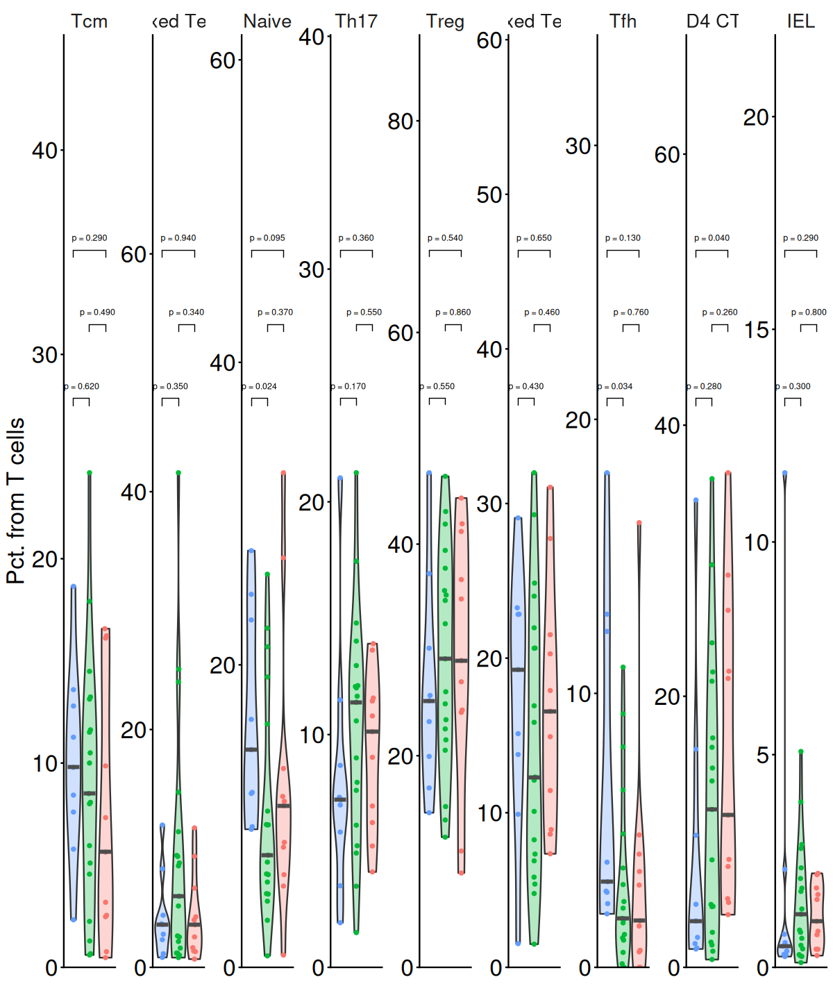


5p | DUO LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 5p           DUO    LP   
2 FR                           13 5p           DUO    LP   
3 PR                            6 5p           DUO    LP   


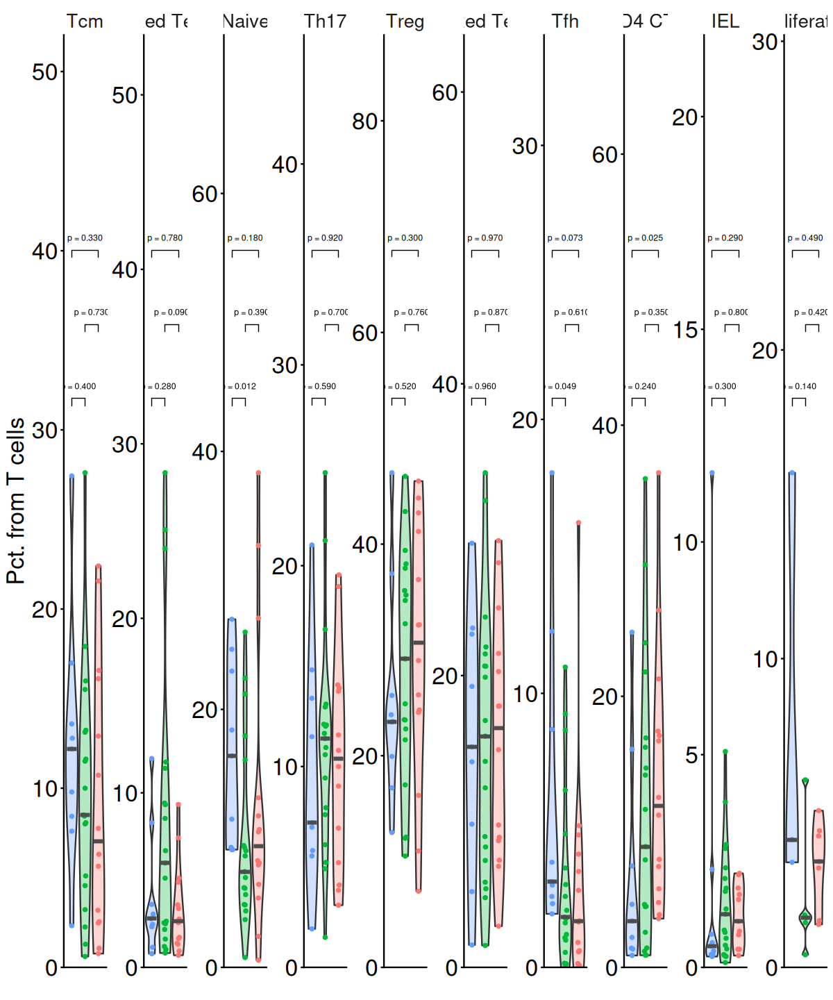


all5p | DUO LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           7 all5p        DUO    LP   
2 FR                           17 all5p        DUO    LP   
3 PR                           12 all5p        DUO    LP   


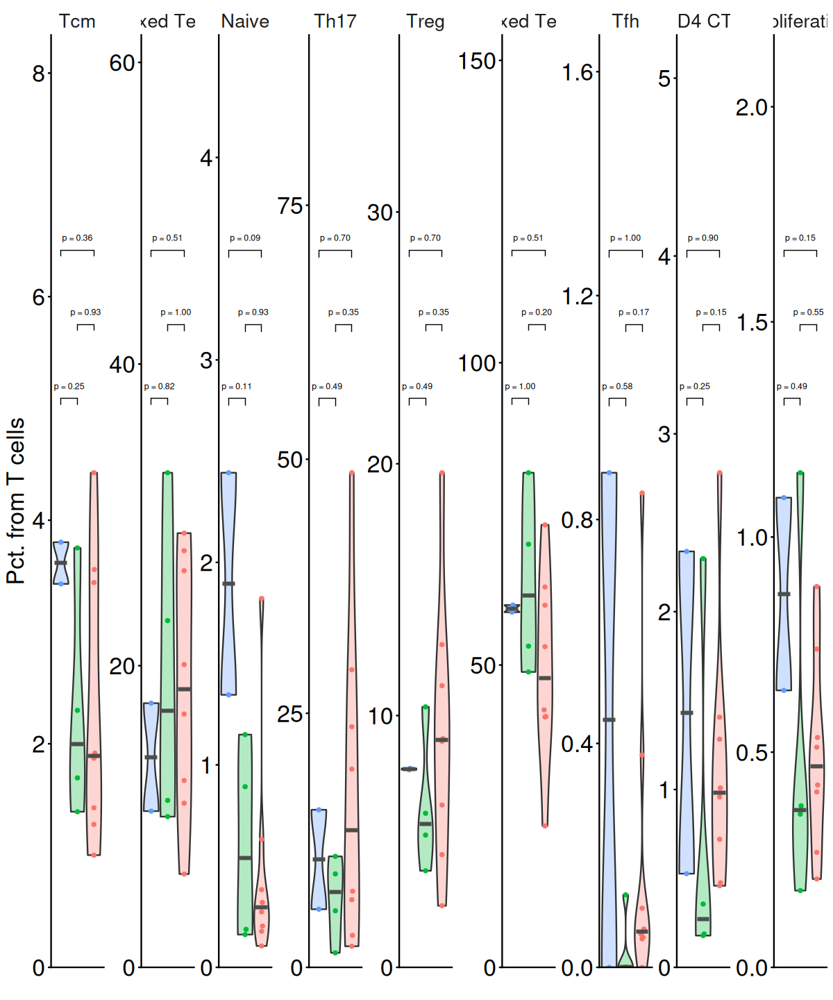


all | DUO LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           7 all          DUO    LP   
2 FR                           17 all          DUO    LP   
3 PR                           14 all          DUO    LP   


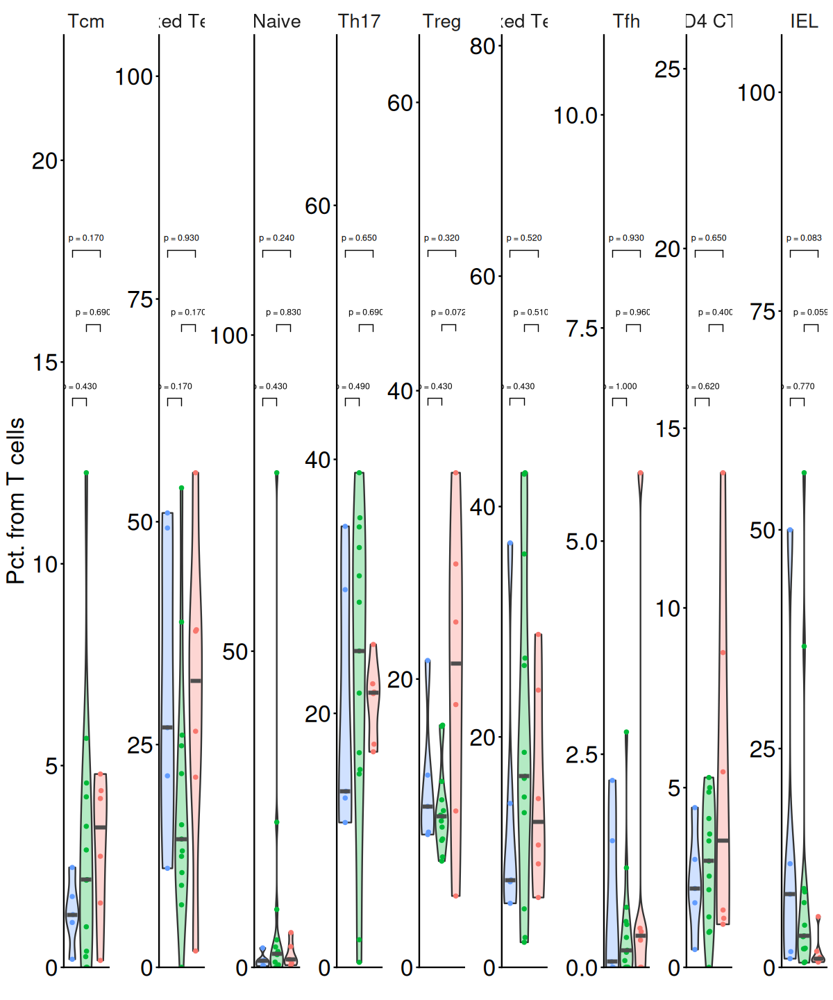


3p | ILE LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 3p           ILE    LP   
2 FR                            5 3p           ILE    LP   
3 PR                            6 3p           ILE    LP   


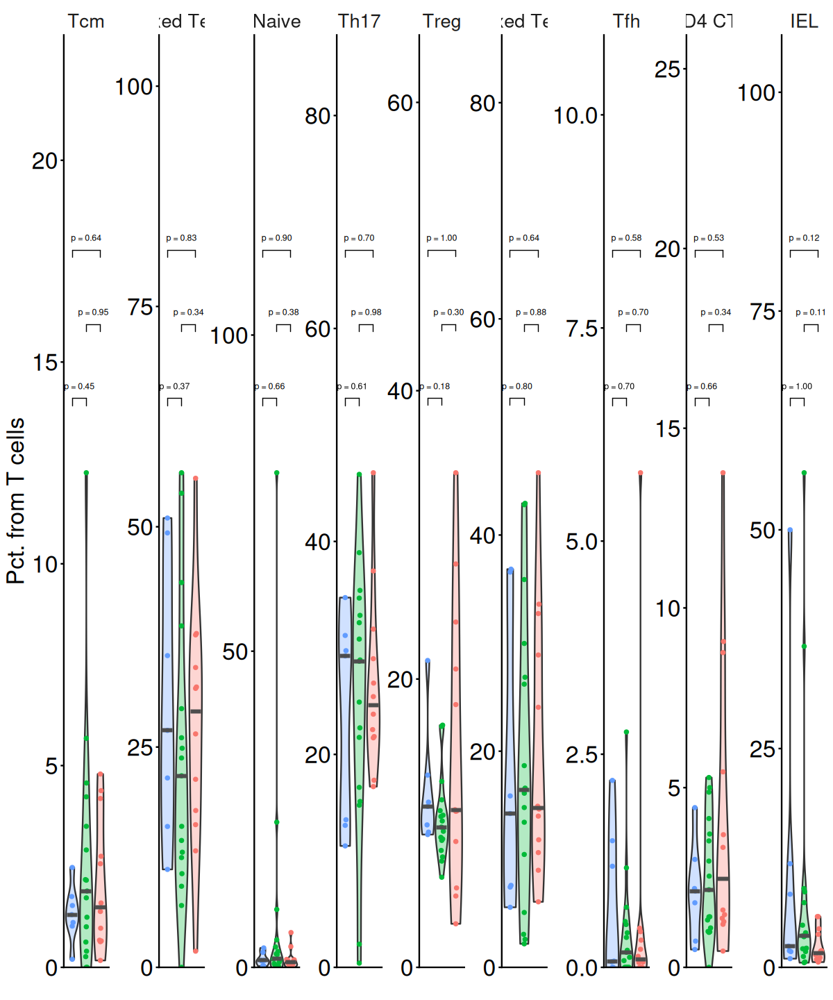


5p | ILE LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 5p           ILE    LP   
2 FR                           14 5p           ILE    LP   
3 PR                            6 5p           ILE    LP   


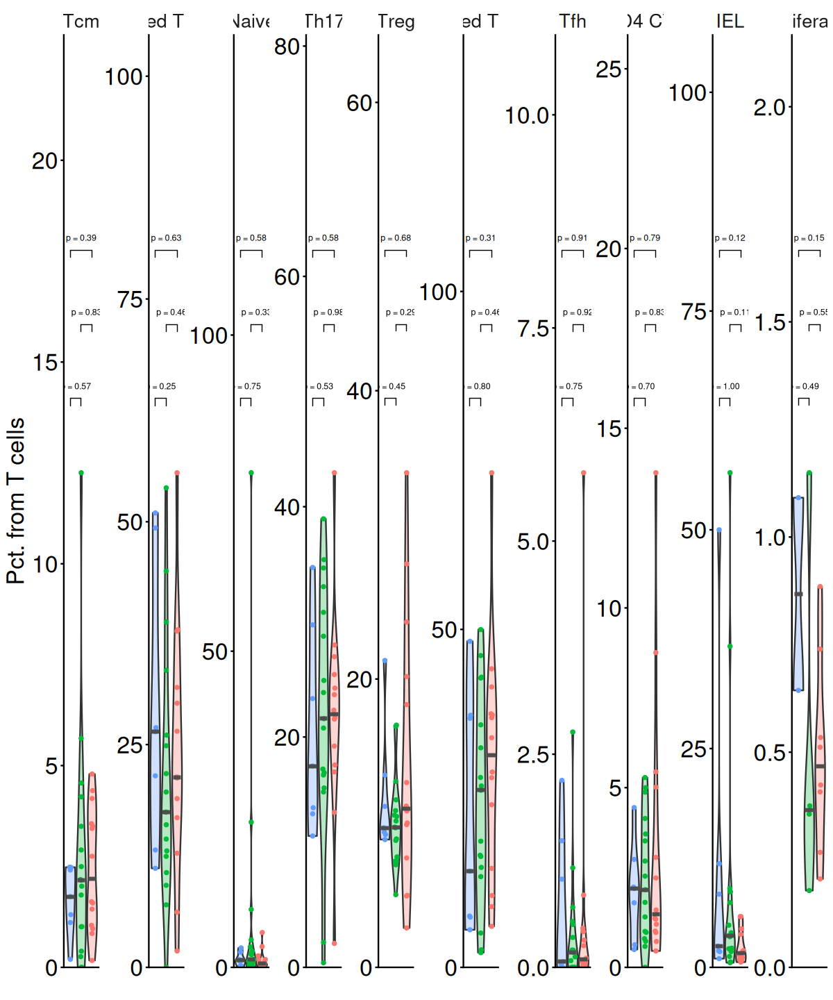


all5p | ILE LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           8 all5p        ILE    LP   
2 FR                           19 all5p        ILE    LP   
3 PR                           12 all5p        ILE    LP   


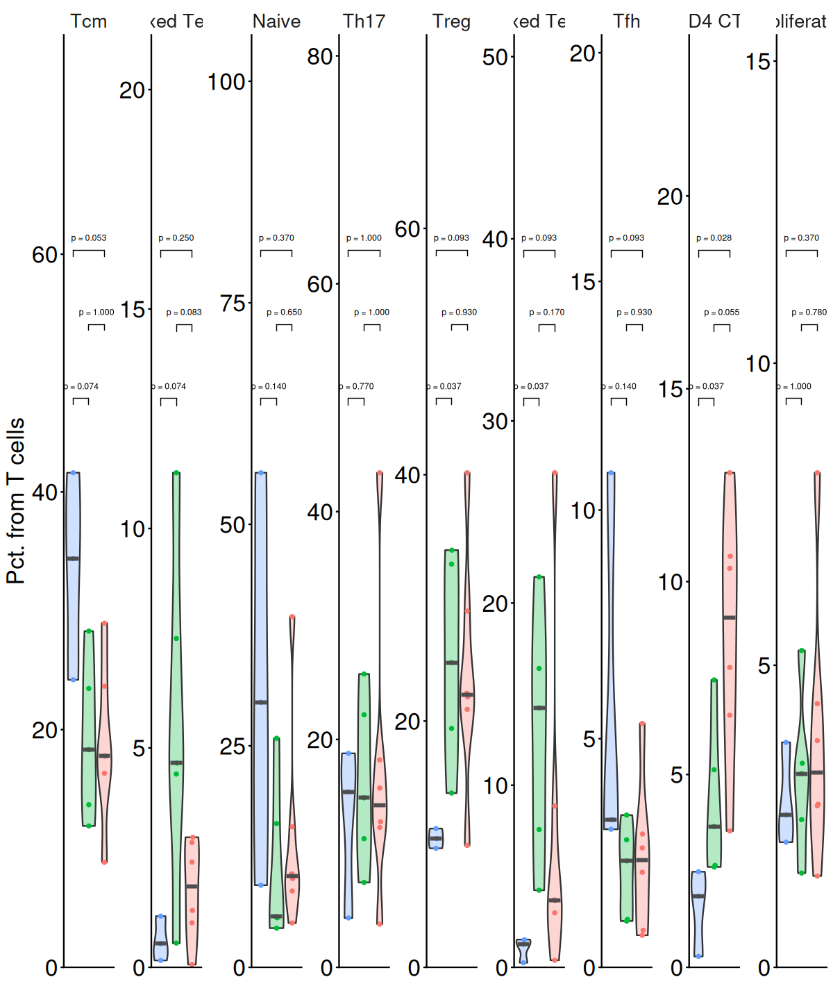


all | ILE LP 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           8 all          ILE    LP   
2 FR                           19 all          ILE    LP   
3 PR                           12 all          ILE    LP   


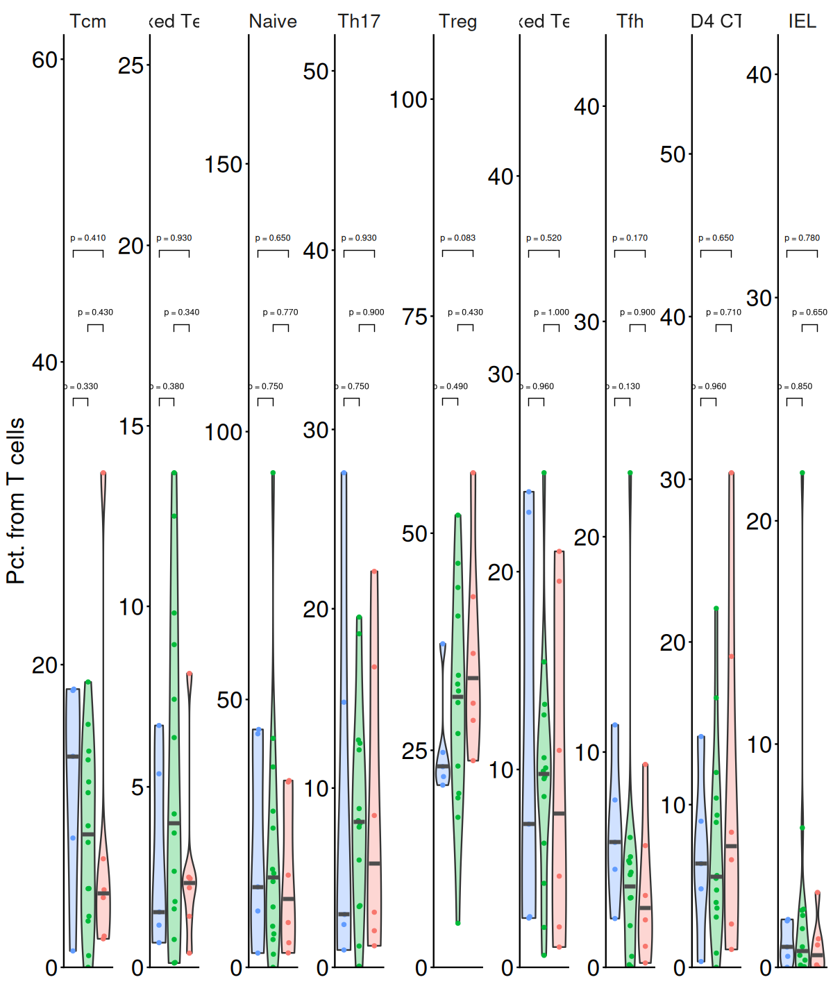


3p | COL EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           0 3p           COL    EPI  
2 FR                            1 3p           COL    EPI  
3 PR                            3 3p           COL    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop

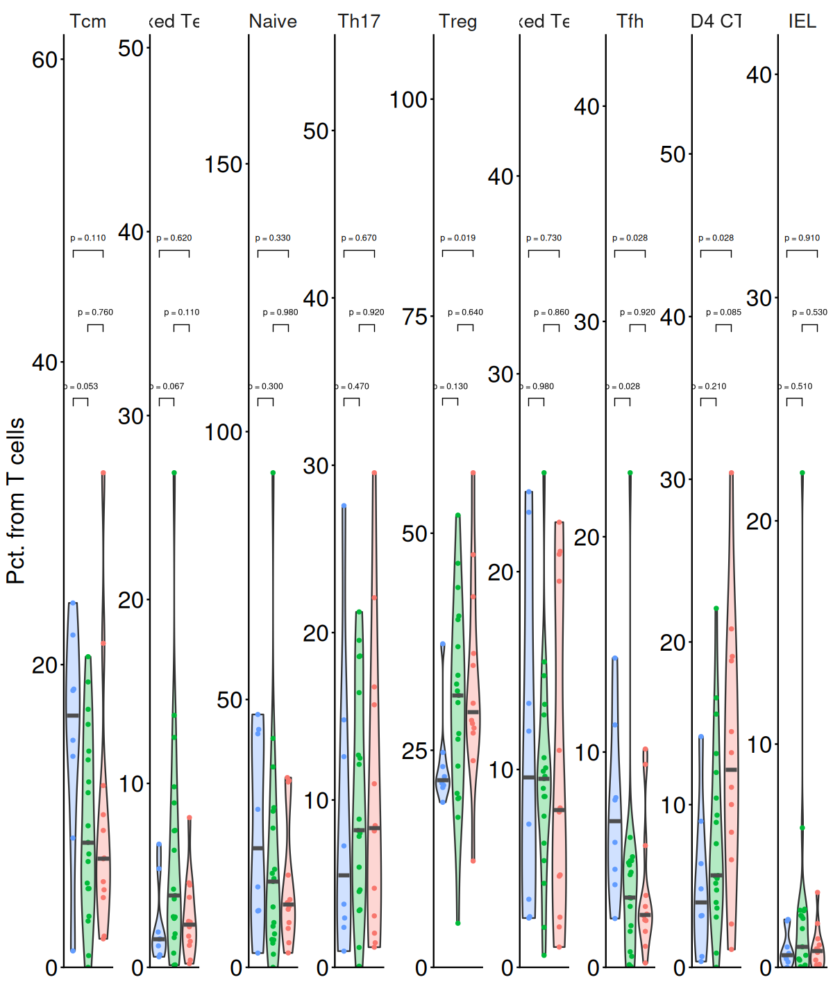

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop


5p | COL EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 5p           COL    EPI  
2 FR                            7 5p           COL    EPI  
3 PR                            6 5p           COL    EPI  


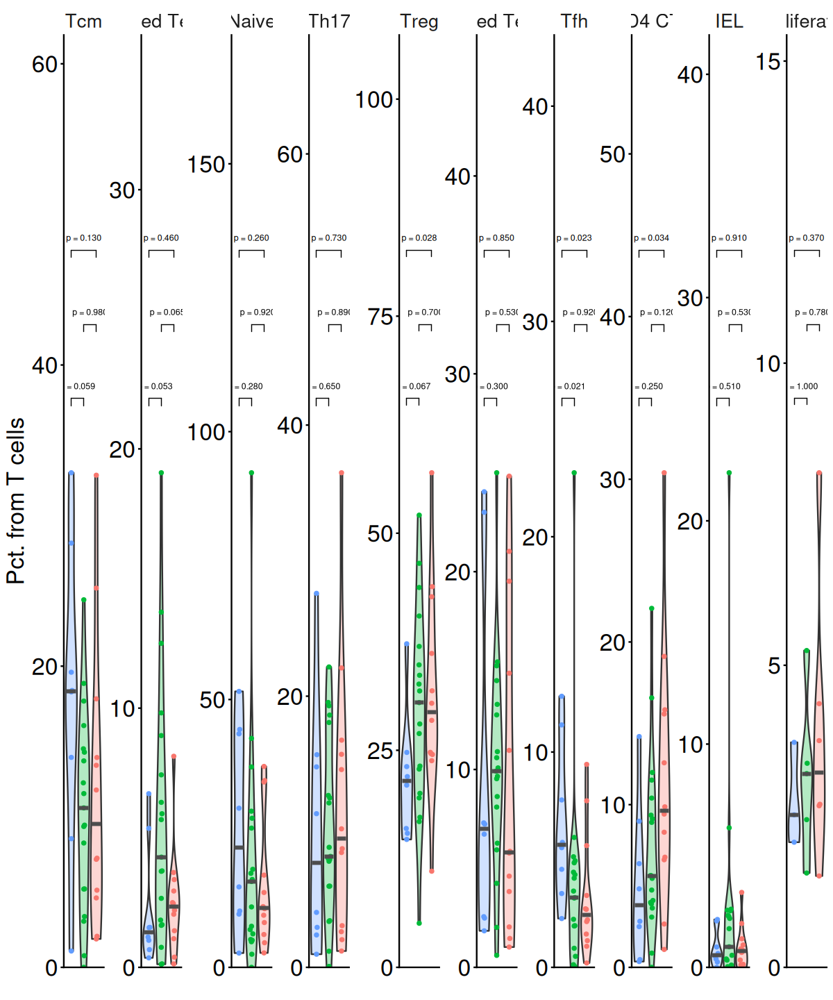


all5p | COL EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 all5p        COL    EPI  
2 FR                            8 all5p        COL    EPI  
3 PR                            6 all5p        COL    EPI  


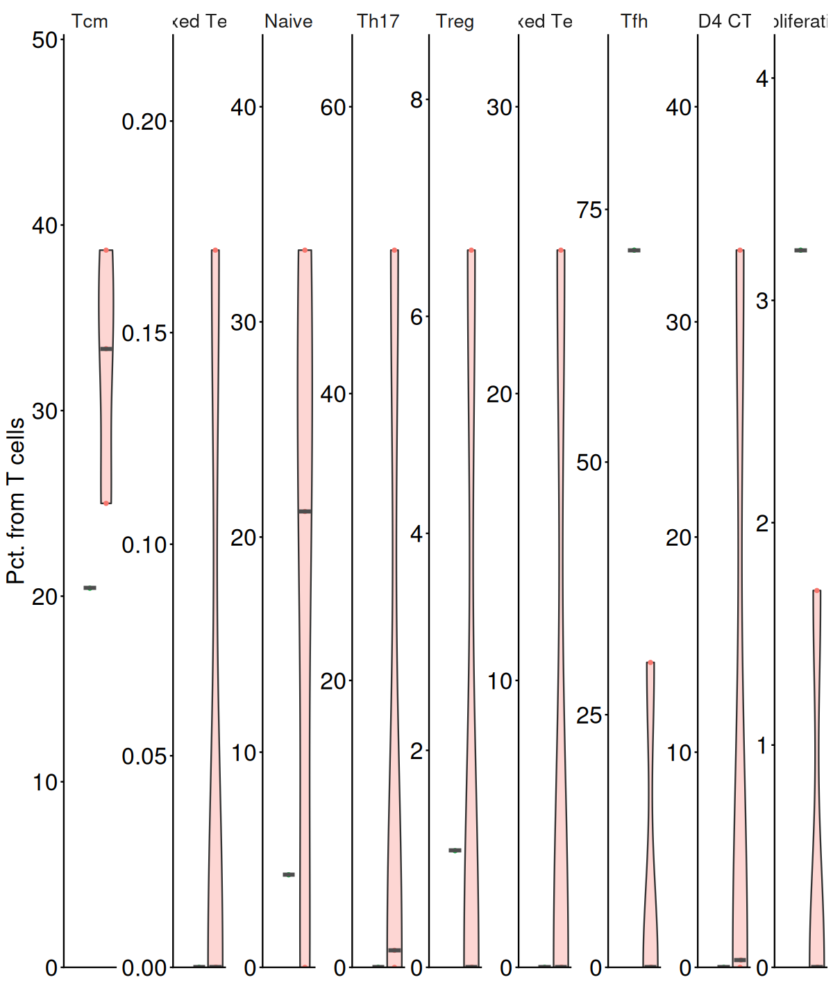


all | COL EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 all          COL    EPI  
2 FR                            8 all          COL    EPI  
3 PR                            9 all          COL    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


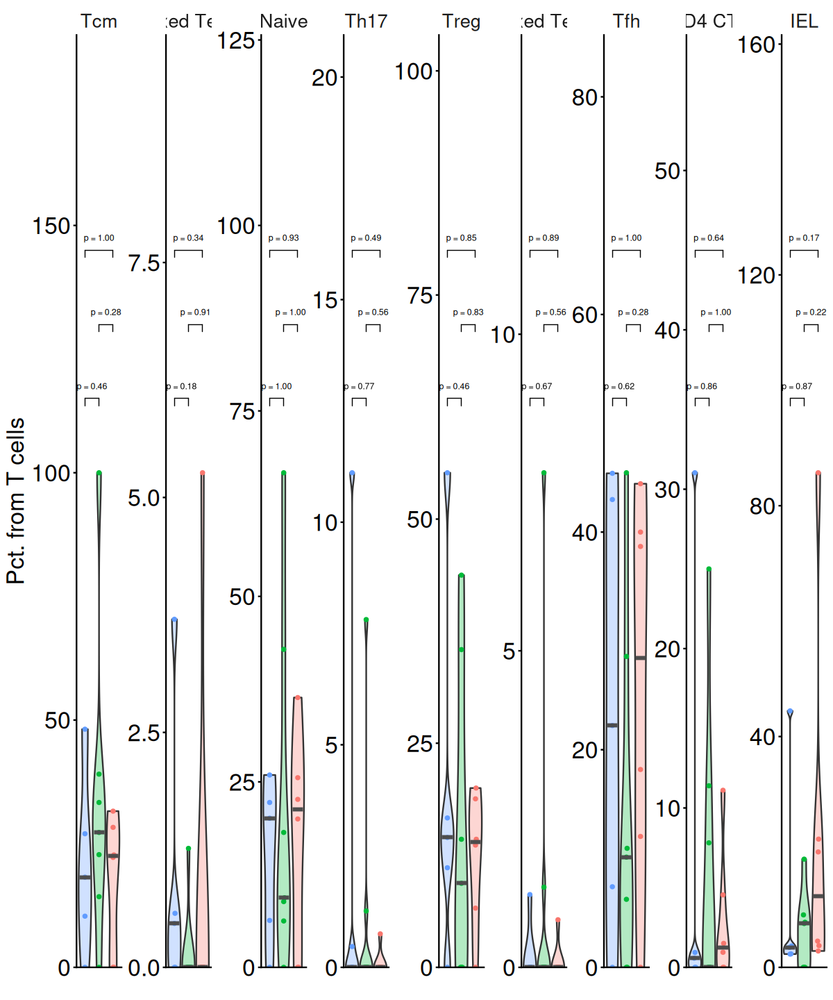

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”



3p | DUO EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           0 3p           DUO    EPI  
2 FR                            1 3p           DUO    EPI  
3 PR                            3 3p           DUO    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop

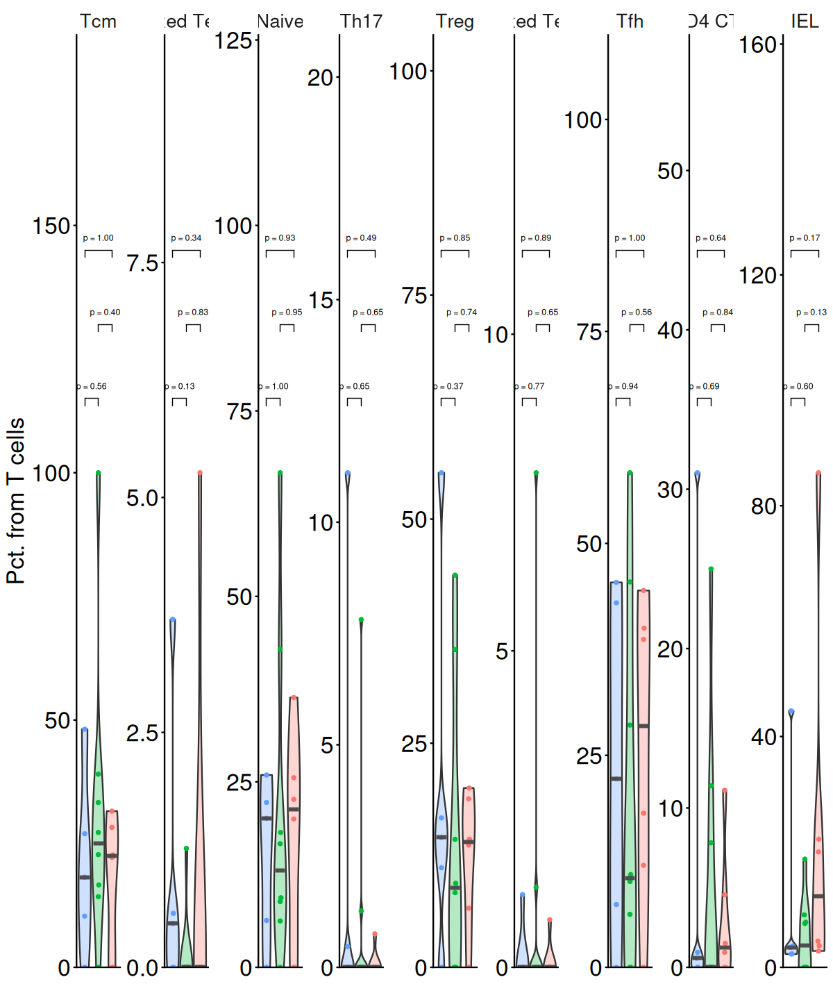

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop


5p | DUO EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 5p           DUO    EPI  
2 FR                           10 5p           DUO    EPI  
3 PR                            6 5p           DUO    EPI  


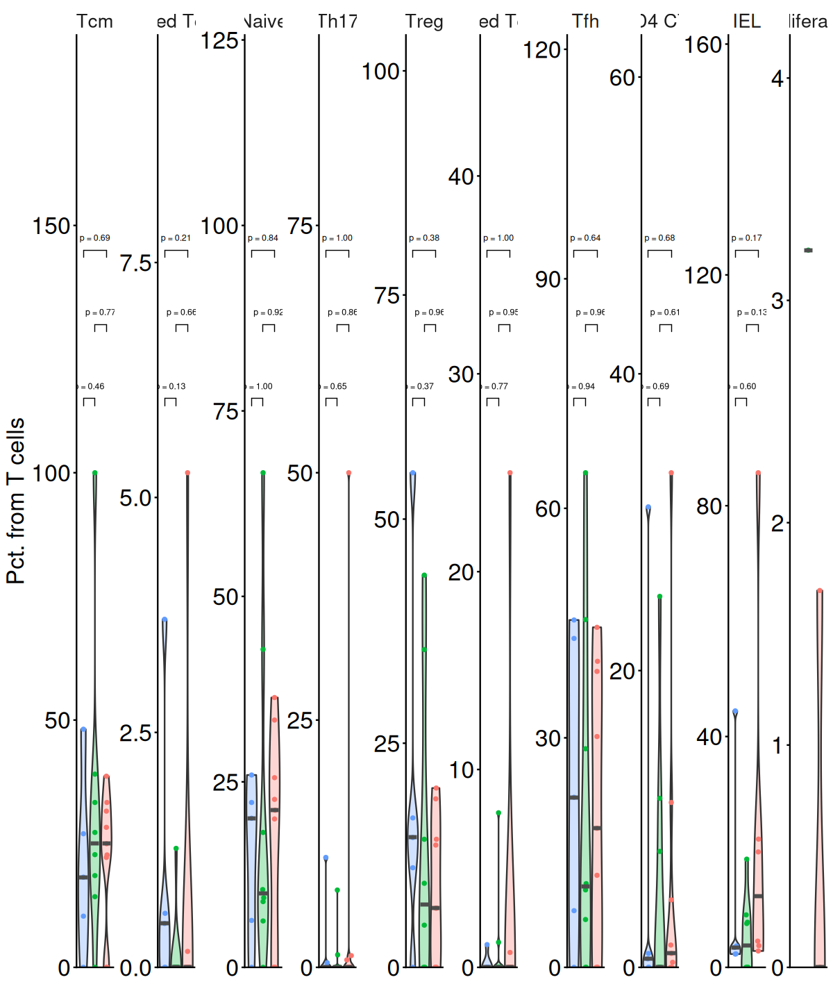


all5p | DUO EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 all5p        DUO    EPI  
2 FR                           11 all5p        DUO    EPI  
3 PR                            6 all5p        DUO    EPI  


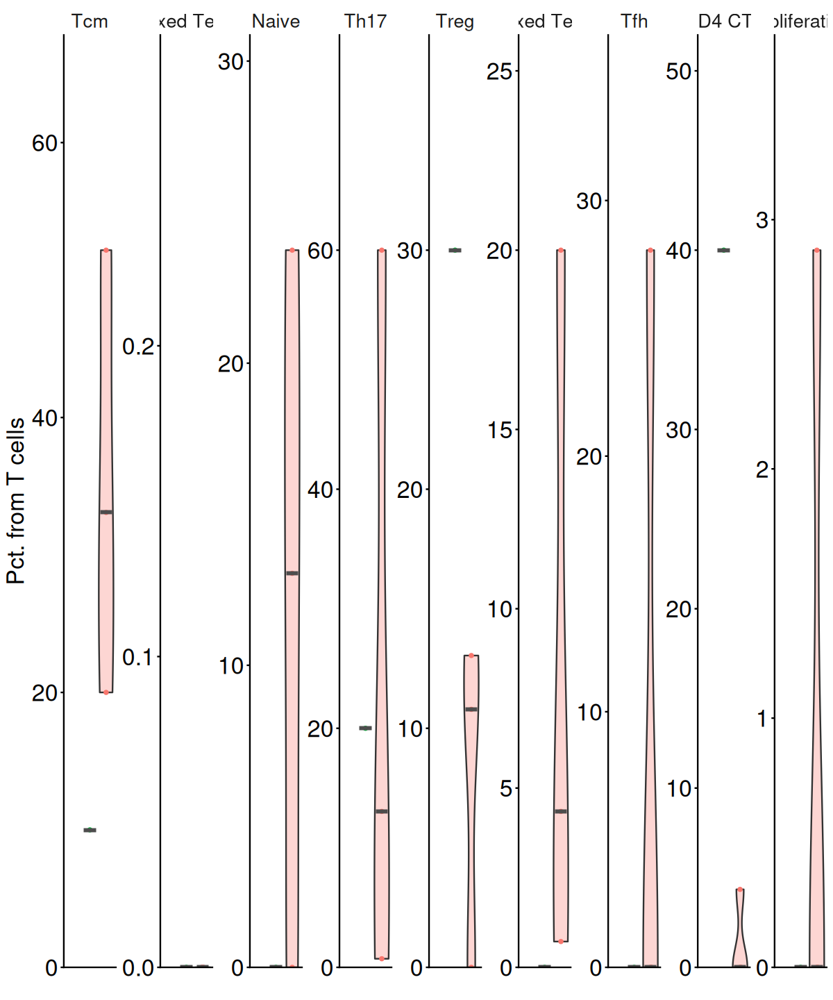


all | DUO EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 all          DUO    EPI  
2 FR                           11 all          DUO    EPI  
3 PR                            9 all          DUO    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


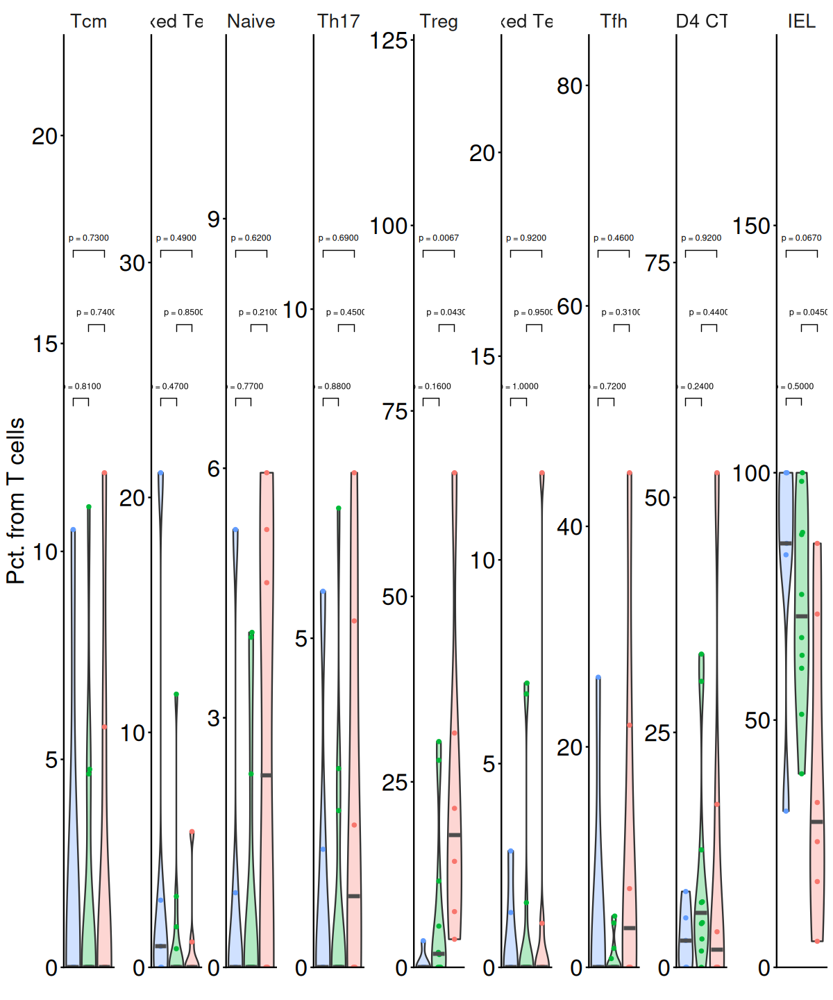

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”



3p | ILE EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           0 3p           ILE    EPI  
2 FR                            1 3p           ILE    EPI  
3 PR                            3 3p           ILE    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop

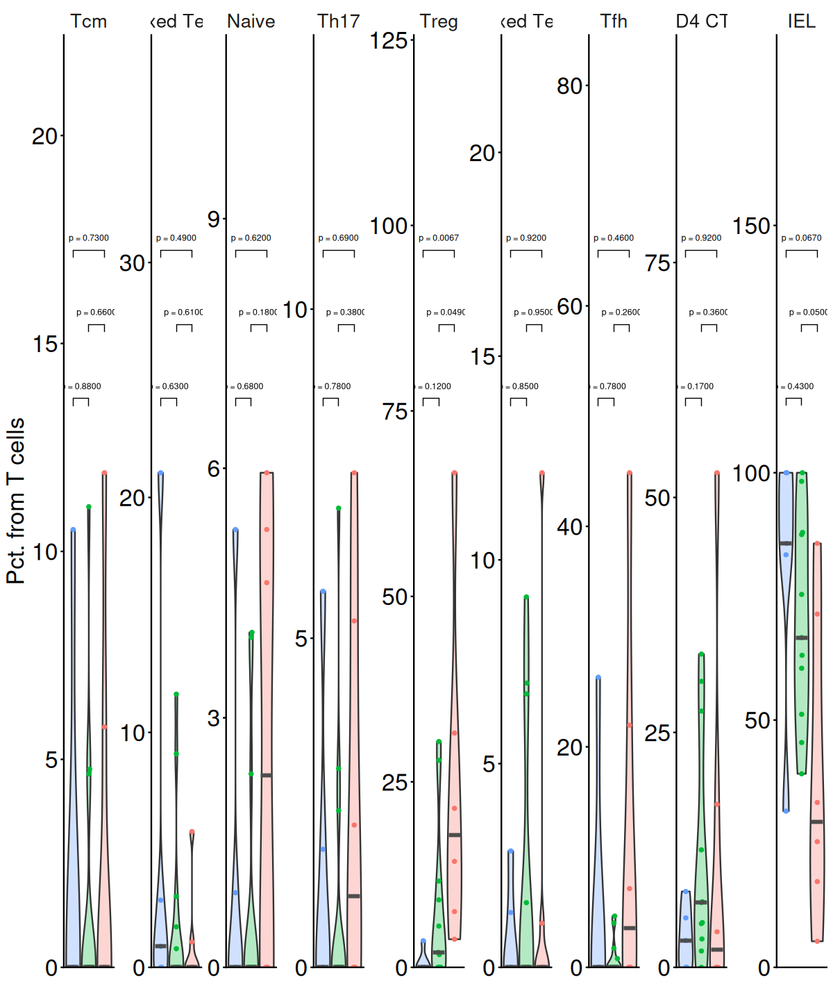

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been drop


5p | ILE EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 5p           ILE    EPI  
2 FR                           11 5p           ILE    EPI  
3 PR                            6 5p           ILE    EPI  


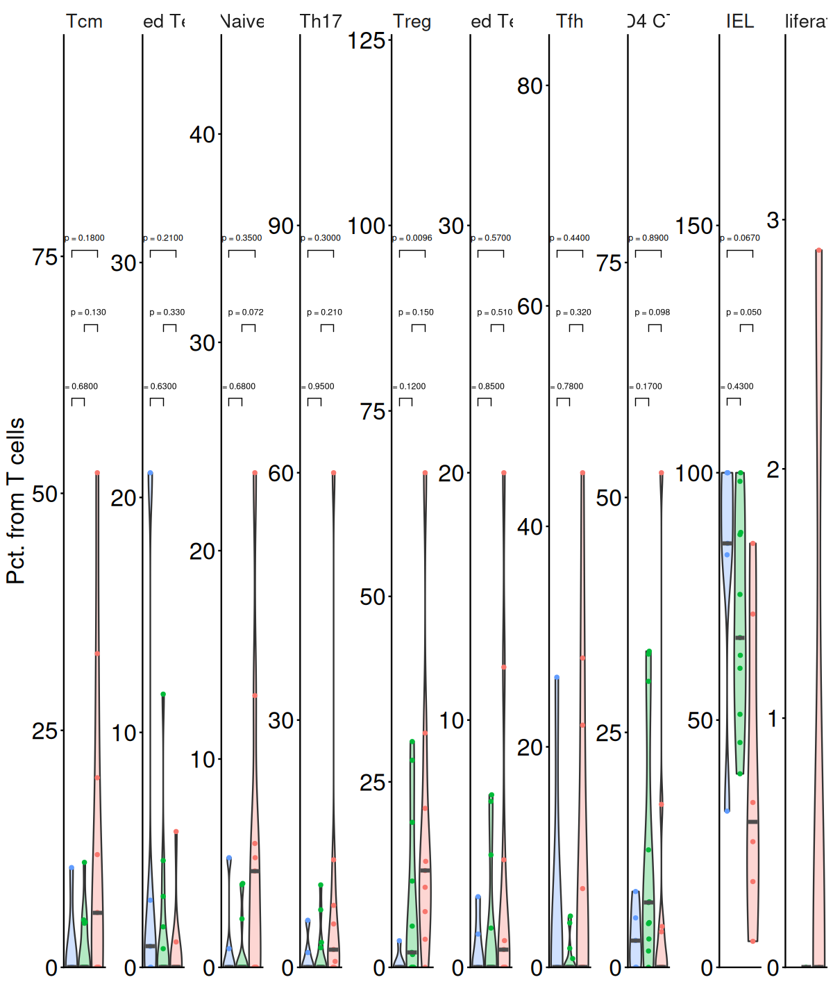


all5p | ILE EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 all5p        ILE    EPI  
2 FR                           12 all5p        ILE    EPI  
3 PR                            6 all5p        ILE    EPI  


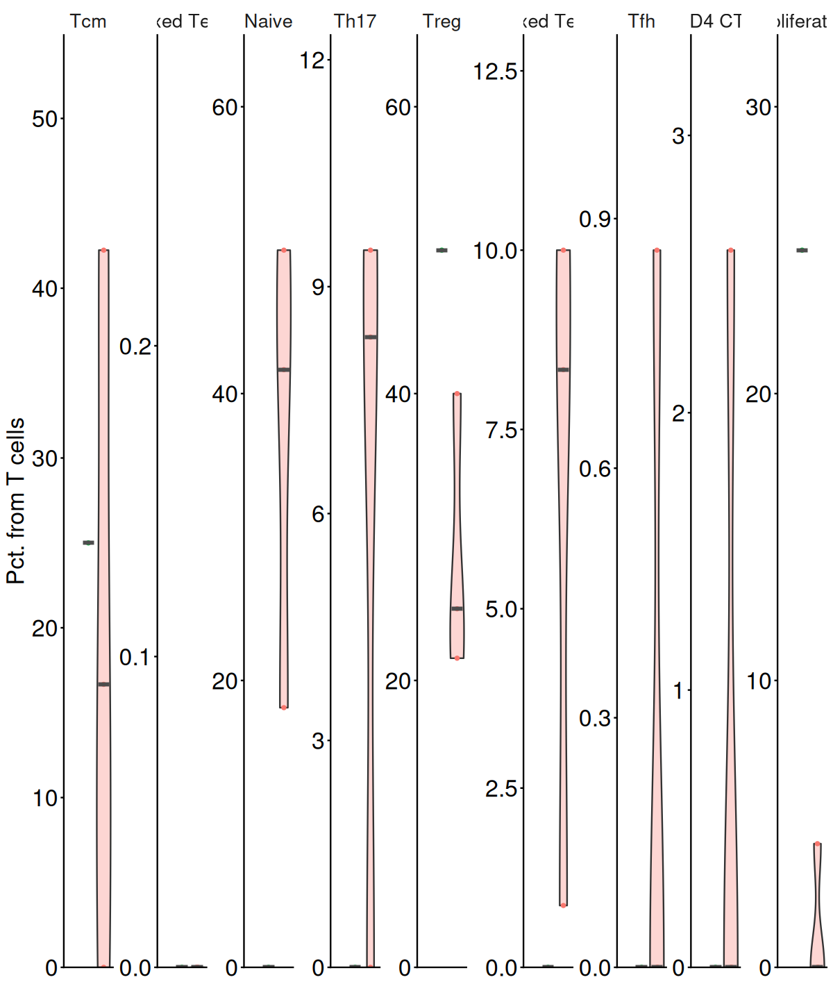


all | ILE EPI 
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 all          ILE    EPI  
2 FR                           12 all          ILE    EPI  
3 PR                            9 all          ILE    EPI  


Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


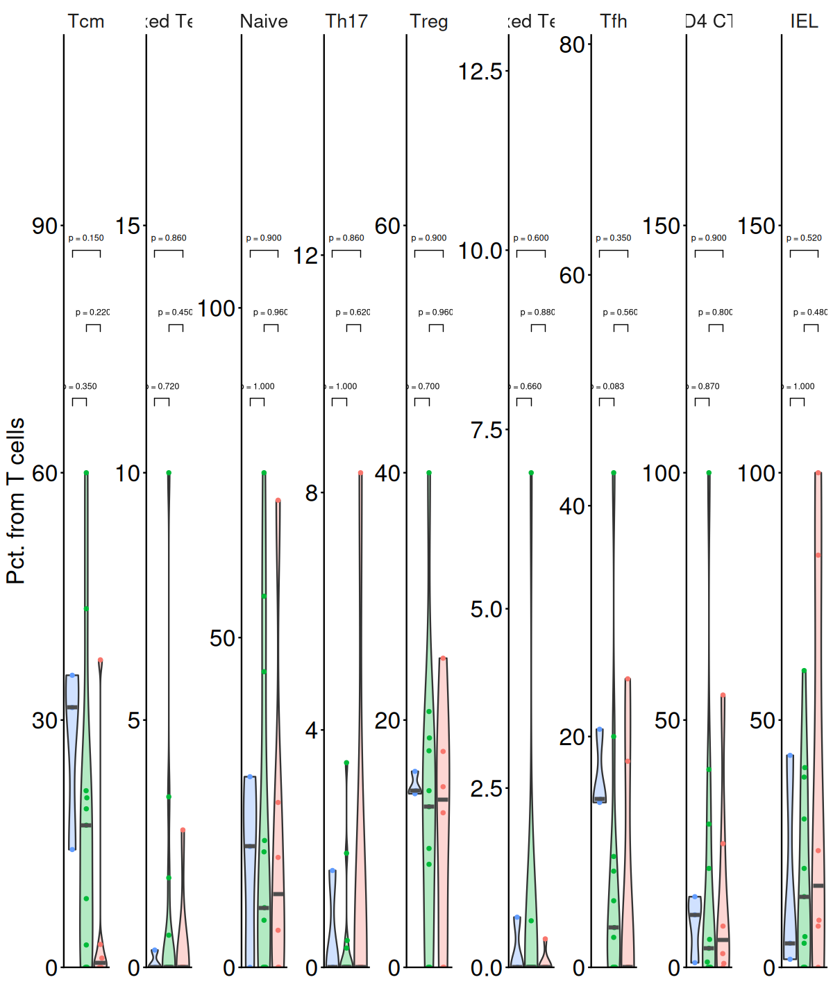

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


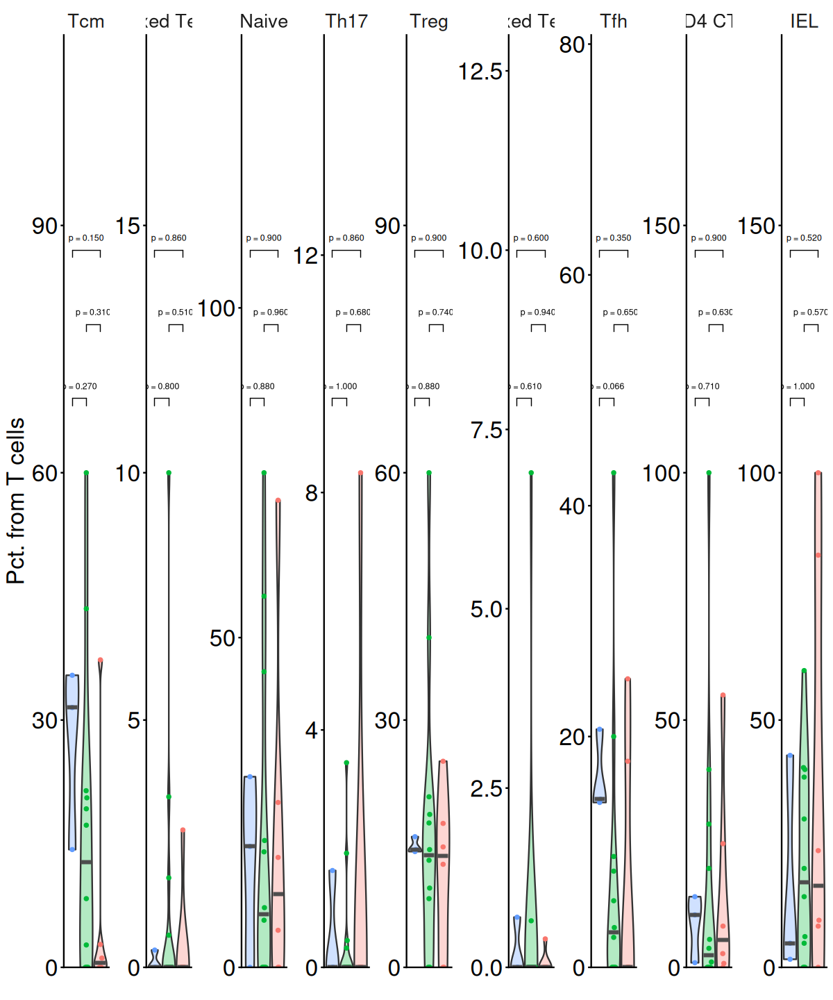

# A tibble: 6 × 5
  tissue layer n_total n_both n_single
  <chr>  <chr>   <int>  <int>    <int>
1 COL    EPI        22      1       22
2 COL    LP         42     12       42
3 DUO    EPI        25      1       25
4 DUO    LP         38     12       38
5 ILE    EPI        24      1       24
6 ILE    LP         39     14       39


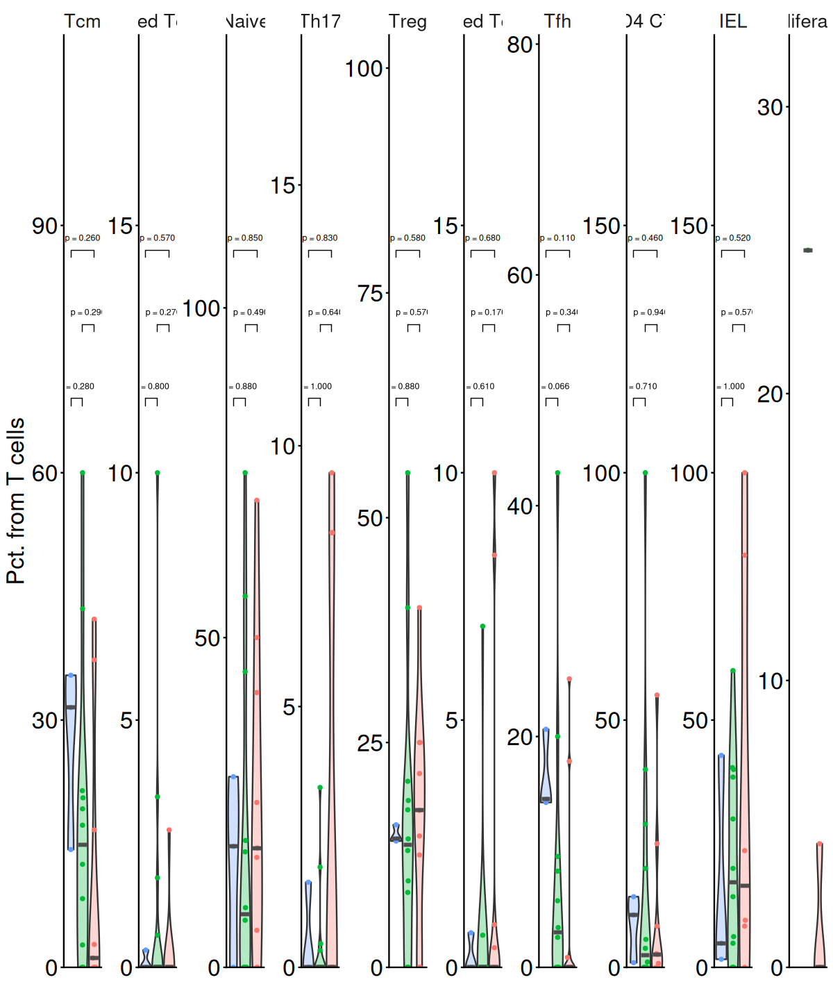

In [283]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(readr)
library(ggbeeswarm)
library(ggpubr)
library(purrr)

# ============================================================
# 1. Output directory and settings
# ============================================================

out_dir <- paste0(
  "figures/cd4_freq_violin/response_CD_",
  format(Sys.time(), "%Y%m%d_%H%M%S")
)

dir.create(
  out_dir,
  recursive = TRUE,
  showWarnings = FALSE
)

response_levels <- c("NOA", "FR", "PR")

response_colors <- setNames(
  scales::hue_pal()(3)[c(3, 2, 1)],
  response_levels
)

comparisons <- list(
  c("NOA", "FR"),
  c("NOA", "PR"),
  c("FR", "PR")
)

# Format p-values to two significant digits
format_p <- function(p) {
  ifelse(
    is.na(p),
    NA_character_,
    format(
      signif(p, digits = 2),
      scientific = FALSE,
      trim = TRUE
    )
  )
}

# ============================================================
# 2. Prepare baseline CD data
# ============================================================

df_base <- df_all_data %>%
  dplyr::filter(
    dataset %in% c("GUT 3p", "GUT 5p"),
    diagnosis == "CD",
    timepoint == "T0",
    antitnf_response %in% response_levels,
    !is.na(participant_id2),
    !is.na(annotations2),
    !is.na(freq),
    !is.na(tissue),
    !is.na(layer)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2),
    antitnf_response = as.character(antitnf_response)
  )

# ============================================================
# 3. Check response metadata consistency
# ============================================================

response_conflicts <- df_base %>%
  dplyr::group_by(participant_id2) %>%
  dplyr::summarise(
    n_responses = dplyr::n_distinct(antitnf_response),
    responses = paste(
      sort(unique(antitnf_response)),
      collapse = ", "
    ),
    .groups = "drop"
  ) %>%
  dplyr::filter(n_responses > 1)

if (nrow(response_conflicts) > 0) {
  print(response_conflicts, n = Inf)
  stop("Conflicting response metadata for the same participant.")
}

# Check for duplicated frequency entries
duplicate_rows <- df_base %>%
  dplyr::count(
    dataset,
    participant_id2,
    tissue,
    layer,
    annotations2
  ) %>%
  dplyr::filter(n > 1)

if (nrow(duplicate_rows) > 0) {
  print(duplicate_rows, n = Inf)
  stop(
    "Multiple frequency rows per participant/dataset/",
    "tissue/layer/annotation. Resolve before plotting."
  )
}

# ============================================================
# 4. Construct four plotting datasets
# ============================================================

# 3p: Identification cohort only
df_3p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 3p",
    cohort_gut == "Identification"
  ) %>%
  dplyr::mutate(
    plot_dataset = "3p",
    n_datasets = 1L
  )

# 5p: Validation cohort only
df_5p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 5p",
    cohort_gut == "Validation"
  ) %>%
  dplyr::mutate(
    plot_dataset = "5p",
    n_datasets = 1L
  )

# all5p: all participants from 5p
df_all5p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 5p"
  ) %>%
  dplyr::mutate(
    plot_dataset = "all5p",
    n_datasets = 1L
  )

# all: average 3p and 5p for overlapping participants
df_all_combined <- df_base %>%
  dplyr::group_by(
    participant_id2,
    diagnosis,
    antitnf_response,
    tissue,
    layer,
    annotations2
  ) %>%
  dplyr::summarise(
    freq = mean(freq),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  ) %>%
  dplyr::mutate(
    plot_dataset = "all"
  )

# Combine all four
df_plot_all <- dplyr::bind_rows(
  df_3p,
  df_5p,
  df_all5p,
  df_all_combined
) %>%
  dplyr::mutate(
    plot_dataset = factor(
      plot_dataset,
      levels = c("3p", "5p", "all5p", "all")
    ),
    antitnf_response = factor(
      antitnf_response,
      levels = response_levels
    ),
    freq_pct = freq * 100
  )

# ============================================================
# 5. Wilcoxon test function
# ============================================================

run_wilcox <- function(df, comparisons) {

  purrr::map_dfr(comparisons, function(comp) {

    group1 <- comp[1]
    group2 <- comp[2]

    x <- df$freq_pct[
      df$antitnf_response == group1
    ]

    y <- df$freq_pct[
      df$antitnf_response == group2
    ]

    n1 <- length(x)
    n2 <- length(y)

    if (n1 < 2 || n2 < 2) {
      return(
        tibble::tibble(
          group1 = group1,
          group2 = group2,
          n1 = n1,
          n2 = n2,
          p = NA_real_
        )
      )
    }

    test <- stats::wilcox.test(
      x,
      y,
      exact = FALSE,
      alternative = "two.sided"
    )

    tibble::tibble(
      group1 = group1,
      group2 = group2,
      n1 = n1,
      n2 = n2,
      p = test$p.value
    )
  })
}

# ============================================================
# 6. Plot all four datasets for each tissue/layer
# ============================================================

tissue_layers <- df_plot_all %>%
  dplyr::distinct(tissue, layer)

all_counts <- list()
all_tests <- list()

for (i in seq_len(nrow(tissue_layers))) {

  tissue_i <- tissue_layers$tissue[i]
  layer_i <- tissue_layers$layer[i]

  for (dataset_i in c("3p", "5p", "all5p", "all")) {

    df_filt <- df_plot_all %>%
      dplyr::filter(
        plot_dataset == dataset_i,
        tissue == tissue_i,
        layer == layer_i
      )

    if (nrow(df_filt) == 0) next

    file_prefix <- paste(
      dataset_i,
      tissue_i,
      layer_i,
      sep = "_"
    )

    # --------------------------------------------------------
    # Save source data
    # --------------------------------------------------------

    readr::write_csv(
      df_filt,
      file.path(
        out_dir,
        paste0(file_prefix, "_source.csv")
      )
    )

    # --------------------------------------------------------
    # Participant counts by response
    # --------------------------------------------------------

    participant_counts <- df_filt %>%
      dplyr::group_by(
        antitnf_response,
        .drop = FALSE
      ) %>%
      dplyr::summarise(
        n_participants = dplyr::n_distinct(
          participant_id2,
          na.rm = TRUE
        ),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        plot_dataset = dataset_i,
        tissue = tissue_i,
        layer = layer_i
      )

    all_counts[[file_prefix]] <- participant_counts

    cat("\n====================================\n")
    cat(dataset_i, "|", tissue_i, layer_i, "\n")
    cat("====================================\n")
    print(participant_counts)

    # Counts per annotation
    annotation_counts <- df_filt %>%
      dplyr::group_by(
        annotations2,
        antitnf_response,
        .drop = FALSE
      ) %>%
      dplyr::summarise(
        n_participants = dplyr::n_distinct(
          participant_id2,
          na.rm = TRUE
        ),
        .groups = "drop"
      )

    readr::write_csv(
      annotation_counts,
      file.path(
        out_dir,
        paste0(file_prefix, "_counts.csv")
      )
    )

    # --------------------------------------------------------
    # Wilcoxon tests per annotation
    # --------------------------------------------------------

    test_results <- df_filt %>%
      dplyr::group_by(annotations2) %>%
      dplyr::group_modify(
        ~ run_wilcox(.x, comparisons)
      ) %>%
      dplyr::ungroup() %>%
      dplyr::mutate(
        plot_dataset = dataset_i,
        tissue = tissue_i,
        layer = layer_i,
        p.format = format_p(p),
        p.label = ifelse(
          is.na(p),
          NA_character_,
          paste0("p = ", p.format)
        )
      )

    all_tests[[file_prefix]] <- test_results

    readr::write_csv(
      test_results,
      file.path(
        out_dir,
        paste0(file_prefix, "_wilcox.csv")
      )
    )

    # --------------------------------------------------------
    # Position p-value brackets within each annotation
    # --------------------------------------------------------

    y_positions <- df_filt %>%
      dplyr::group_by(annotations2) %>%
      dplyr::summarise(
        y_max = max(freq_pct, na.rm = TRUE),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        y_step = pmax(y_max * 0.15, 0.05)
      )

    stat_labels <- test_results %>%
      dplyr::filter(!is.na(p)) %>%
      dplyr::left_join(
        y_positions,
        by = "annotations2"
      ) %>%
      dplyr::group_by(annotations2) %>%
      dplyr::mutate(
        comparison_order = dplyr::case_when(
          group1 == "NOA" & group2 == "FR" ~ 1L,
          group1 == "FR" & group2 == "PR" ~ 2L,
          group1 == "NOA" & group2 == "PR" ~ 3L
        )
      ) %>%
      dplyr::arrange(comparison_order, .by_group = TRUE) %>%
      dplyr::mutate(
        y.position = y_max +
          dplyr::row_number() * y_step
      ) %>%
      dplyr::ungroup()

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    p <- ggplot(
      df_filt,
      aes(
        x = antitnf_response,
        y = freq_pct
      )
    ) +
      geom_violin(
        aes(fill = antitnf_response),
        alpha = 0.3,
        scale = "width"
      ) +
      ggbeeswarm::geom_beeswarm(
        aes(color = antitnf_response),
        size = 1.5,
        cex = 2,
        shape = 16,
        corral = "random"
      ) +
      stat_summary(
        fun = "median",
        geom = "crossbar",
        width = 0.75,
        color = "grey30"
      ) +
      facet_wrap(
        ~ annotations2,
        scales = "free_y",
        ncol = 11
      ) +
      scale_fill_manual(
        values = response_colors,
        drop = FALSE
      ) +
      scale_color_manual(
        values = response_colors,
        drop = FALSE
      ) +
      scale_x_discrete(drop = FALSE) +
      scale_y_continuous(
        limits = c(0, NA),
        expand = expansion(
          mult = c(0, 0.30)
        )
      ) +
      labs(
        x = "",
        y = "Pct. from T cells"
      ) +
      theme_classic() +
      theme(
        strip.background = element_blank(),
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank(),
        legend.position = "none"
      ) +
      ggtheme()

    # Add numerical p-value brackets
    if (nrow(stat_labels) > 0) {

      p <- p +
        ggpubr::stat_pvalue_manual(
          stat_labels,
          label = "p.label",
          xmin = "group1",
          xmax = "group2",
          y.position = "y.position",
          tip.length = 0.01,
          bracket.size = 0.3,
          size = 2.5,
          inherit.aes = FALSE
        )
    }

    # --------------------------------------------------------
    # Save plots
    # --------------------------------------------------------

    ggsave(
      filename = file.path(
        out_dir,
        paste0(file_prefix, ".svg")
      ),
      plot = p,
      width = 20,
      height = 4,
      units = "in"
    )

    ggsave(
      filename = file.path(
        out_dir,
        paste0(file_prefix, ".png")
      ),
      plot = p,
      width = 20,
      height = 4,
      units = "in",
      dpi = 300
    )

    print(p)
  }
}

# ============================================================
# 7. Save combined counts and statistical results
# ============================================================

readr::write_csv(
  dplyr::bind_rows(all_counts),
  file.path(
    out_dir,
    "all_participant_counts.csv"
  )
)

readr::write_csv(
  dplyr::bind_rows(all_tests),
  file.path(
    out_dir,
    "all_wilcox_results.csv"
  )
)

# ============================================================
# 8. Check participants represented in both chemistries
# ============================================================

overlap_summary <- df_all_combined %>%
  dplyr::group_by(tissue, layer) %>%
  dplyr::summarise(
    n_total = dplyr::n_distinct(participant_id2),
    n_both = dplyr::n_distinct(
      participant_id2[n_datasets == 2]
    ),
    n_single = dplyr::n_distinct(
      participant_id2[n_datasets == 1]
    ),
    .groups = "drop"
  )

print(overlap_summary, n = Inf)

readr::write_csv(
  overlap_summary,
  file.path(
    out_dir,
    "overlap_summary.csv"
  )
)


3p | COL LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 3p           COL    LP   
2 FR                            5 3p           COL    LP   
3 PR                            7 3p           COL    LP   

5p | COL LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           6 5p           COL    LP   
2 FR                           14 5p           COL    LP   
3 PR                            6 5p           COL    LP   

all5p | COL LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           9 all5p        COL    LP   
2 FR                           19 all5p        COL    LP   
3 PR                           11 all5p        COL    LP   


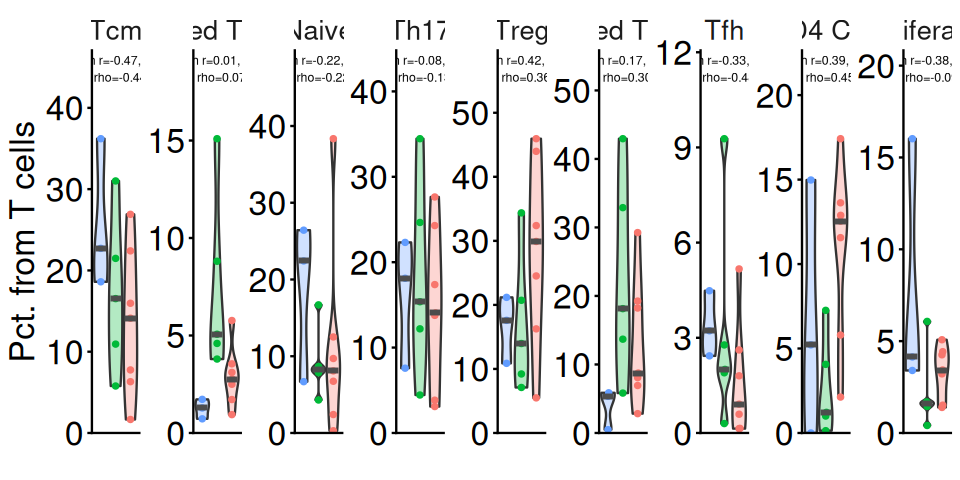


all | COL LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           9 all          COL    LP   
2 FR                           19 all          COL    LP   
3 PR                           14 all          COL    LP   


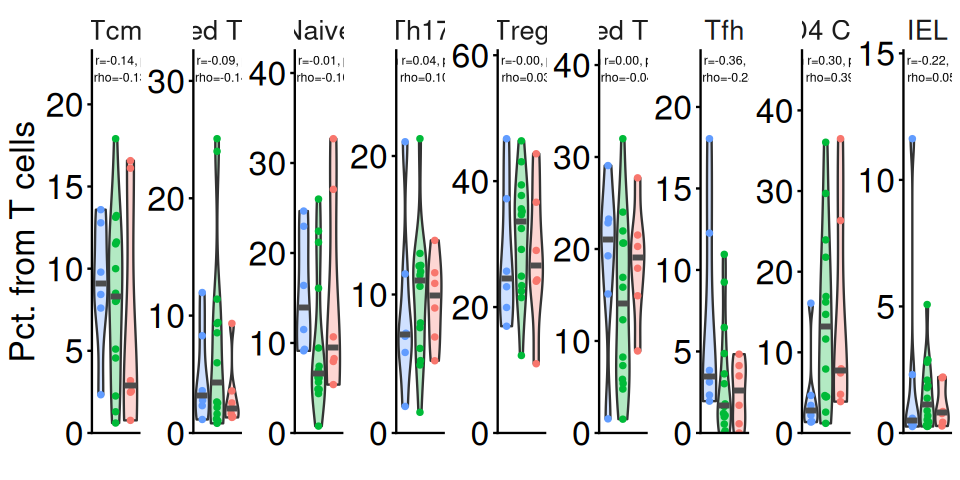


3p | ILE LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           3 3p           ILE    LP   
2 FR                            5 3p           ILE    LP   
3 PR                            6 3p           ILE    LP   


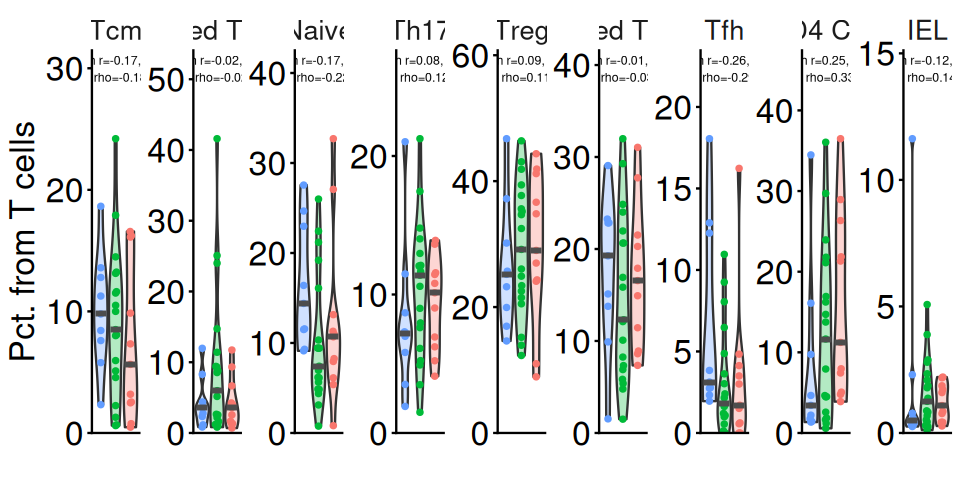


5p | ILE LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           5 5p           ILE    LP   
2 FR                           14 5p           ILE    LP   
3 PR                            6 5p           ILE    LP   


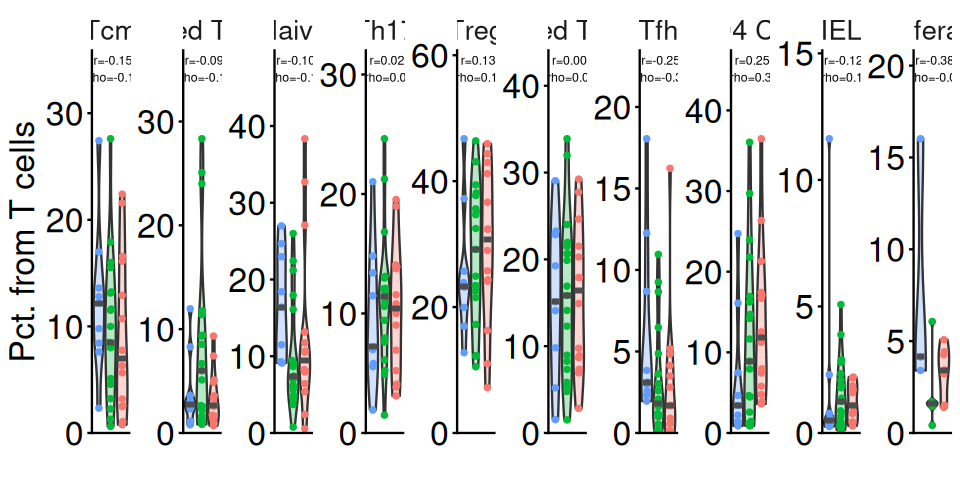


all5p | ILE LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           8 all5p        ILE    LP   
2 FR                           19 all5p        ILE    LP   
3 PR                           12 all5p        ILE    LP   


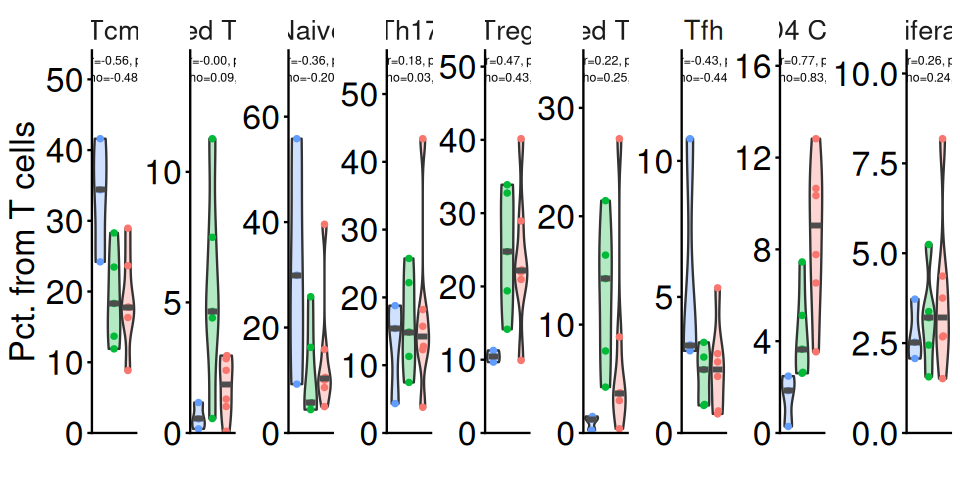


all | ILE LP
# A tibble: 3 × 5
  antitnf_response n_participants plot_dataset tissue layer
  <fct>                     <int> <chr>        <chr>  <chr>
1 NOA                           8 all          ILE    LP   
2 FR                           19 all          ILE    LP   
3 PR                           12 all          ILE    LP   


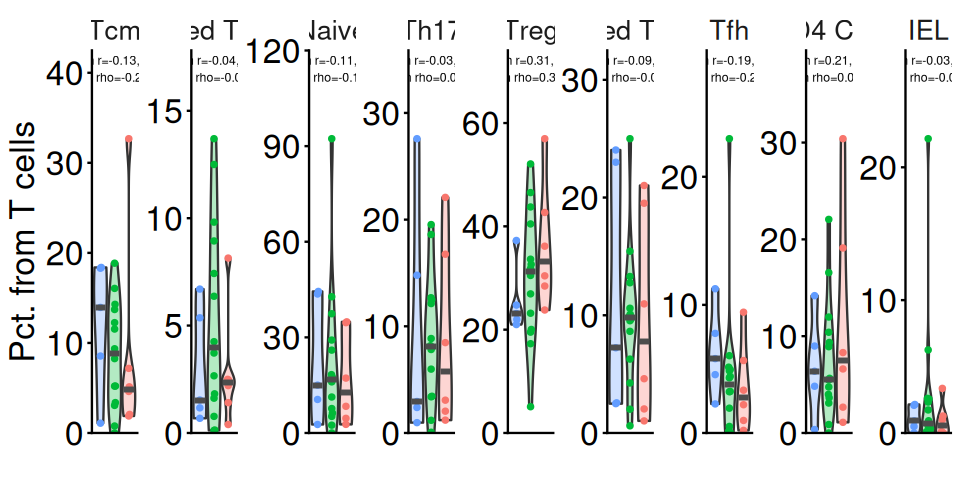

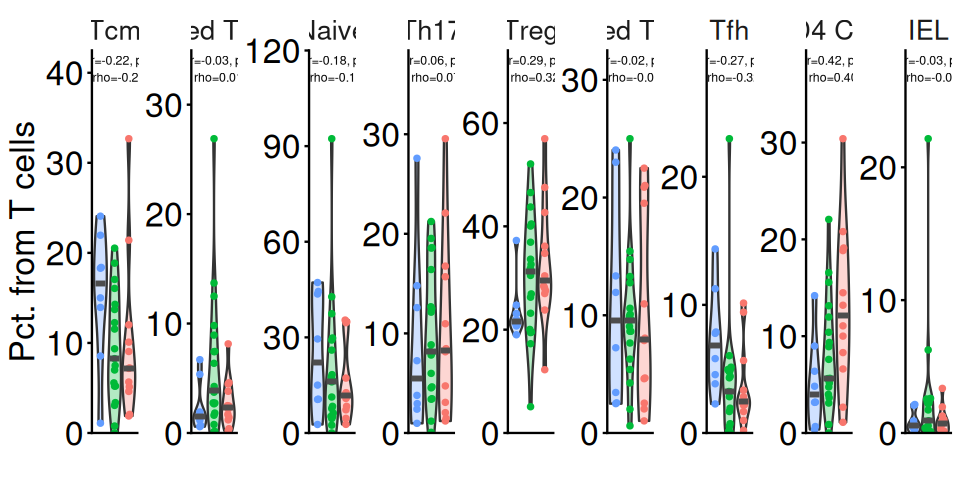

# A tibble: 2 × 5
  tissue layer n_total n_both n_single
  <chr>  <chr>   <int>  <int>    <int>
1 COL    LP         42     12       42
2 ILE    LP         39     14       39


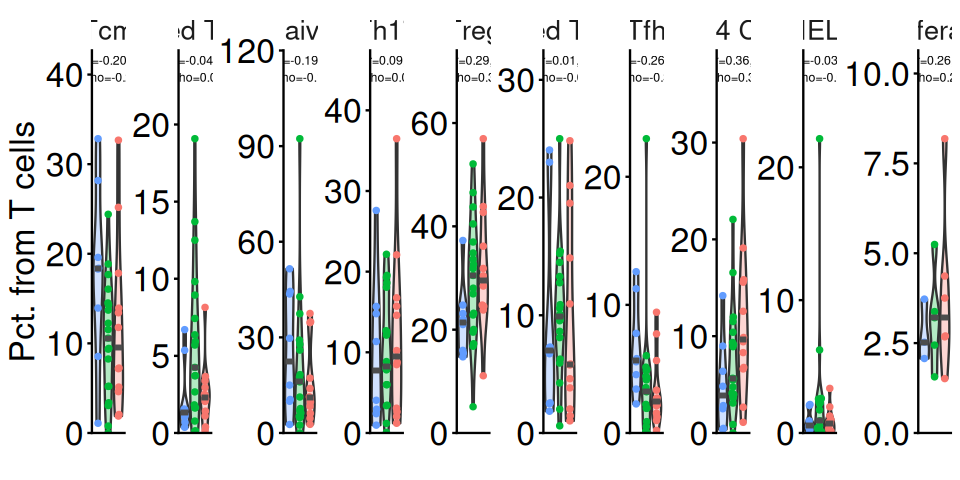

In [307]:
# ============================================================
# 1. Settings
# ============================================================

out_dir <- paste0(
  "figures/cd4_freq_violin/response_CD_correlations_",
  format(Sys.time(), "%Y%m%d_%H%M%S")
)

dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

response_levels <- c("NOA", "FR", "PR")

response_colors <- setNames(
  scales::hue_pal()(3)[c(3, 2, 1)],
  response_levels
)

# ============================================================
# 2. Prepare baseline CD data: COL LP and ILE LP only
# ============================================================

df_base <- df_all_data %>%
  dplyr::filter(
    dataset %in% c("GUT 3p", "GUT 5p"),
    diagnosis == "CD",
    timepoint == "T0",
    tissue %in% c("COL", "ILE"),
    layer == "LP",
    antitnf_response %in% response_levels,
    !is.na(participant_id2),
    !is.na(annotations2),
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2),
    antitnf_response = as.character(antitnf_response)
  )

# Check response consistency across datasets
response_conflicts <- df_base %>%
  dplyr::group_by(participant_id2) %>%
  dplyr::summarise(
    n_responses = dplyr::n_distinct(antitnf_response),
    .groups = "drop"
  ) %>%
  dplyr::filter(n_responses > 1)

if (nrow(response_conflicts) > 0) {
  print(response_conflicts, n = Inf)
  stop("Conflicting response metadata across datasets.")
}

# Check duplicates
duplicate_rows <- df_base %>%
  dplyr::count(
    dataset,
    participant_id2,
    tissue,
    layer,
    annotations2
  ) %>%
  dplyr::filter(n > 1)

if (nrow(duplicate_rows) > 0) {
  print(duplicate_rows, n = Inf)
  stop("Duplicated frequency entries. Resolve before plotting.")
}

# ============================================================
# 3. Construct four datasets
# ============================================================

# 3p: Identification
df_3p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 3p",
    cohort_gut == "Identification"
  ) %>%
  dplyr::mutate(
    plot_dataset = "3p",
    n_datasets = 1L
  )

# 5p: Validation
df_5p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 5p",
    cohort_gut == "Validation"
  ) %>%
  dplyr::mutate(
    plot_dataset = "5p",
    n_datasets = 1L
  )

# all5p: All 5p participants
df_all5p <- df_base %>%
  dplyr::filter(dataset == "GUT 5p") %>%
  dplyr::mutate(
    plot_dataset = "all5p",
    n_datasets = 1L
  )

# all: All participants, averaging 3p and 5p overlaps
df_all_combined <- df_base %>%
  dplyr::group_by(
    participant_id2,
    diagnosis,
    antitnf_response,
    tissue,
    layer,
    annotations2
  ) %>%
  dplyr::summarise(
    freq = mean(freq),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  ) %>%
  dplyr::mutate(plot_dataset = "all")

df_plot_all <- dplyr::bind_rows(
  df_3p,
  df_5p,
  df_all5p,
  df_all_combined
) %>%
  dplyr::mutate(
    plot_dataset = factor(
      plot_dataset,
      levels = c("3p", "5p", "all5p", "all")
    ),
    antitnf_response = factor(
      antitnf_response,
      levels = response_levels
    ),
    response_numeric = as.numeric(antitnf_response) - 1,
    freq_pct = freq * 100
  )

# ============================================================
# 4. Correlation function
# ============================================================

format_p <- function(p) {
  ifelse(
    is.na(p),
    NA_character_,
    format(
      signif(p, 2),
      scientific = FALSE,
      trim = TRUE
    )
  )
}

run_correlations <- function(df) {

  x <- df$response_numeric
  y <- df$freq_pct

  valid <- length(x) >= 3 &&
    dplyr::n_distinct(x) >= 2 &&
    dplyr::n_distinct(y) >= 2

  if (!valid) {
    return(tibble::tibble(
      n = length(x),
      pearson_r = NA_real_,
      pearson_p = NA_real_,
      spearman_rho = NA_real_,
      spearman_p = NA_real_
    ))
  }

  pearson <- stats::cor.test(
    x, y,
    method = "pearson"
  )

  spearman <- suppressWarnings(
    stats::cor.test(
      x, y,
      method = "spearman",
      exact = FALSE
    )
  )

  tibble::tibble(
    n = length(x),
    pearson_r = unname(pearson$estimate),
    pearson_p = pearson$p.value,
    spearman_rho = unname(spearman$estimate),
    spearman_p = spearman$p.value
  )
}

# ============================================================
# 5. Generate plots and correlations
# ============================================================

all_correlations <- list()
all_counts <- list()

for (tissue_i in c("COL", "ILE")) {

  for (dataset_i in c("3p", "5p", "all5p", "all")) {

    df_filt <- df_plot_all %>%
      dplyr::filter(
        tissue == tissue_i,
        layer == "LP",
        plot_dataset == dataset_i
      )

    if (nrow(df_filt) == 0) next

    file_prefix <- paste(
      dataset_i, tissue_i, "LP",
      sep = "_"
    )

    # Save source data
    readr::write_csv(
      df_filt,
      file.path(out_dir, paste0(file_prefix, "_source.csv"))
    )

    # Participant counts
    participant_counts <- df_filt %>%
      dplyr::group_by(antitnf_response, .drop = FALSE) %>%
      dplyr::summarise(
        n_participants = dplyr::n_distinct(
          participant_id2,
          na.rm = TRUE
        ),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        plot_dataset = dataset_i,
        tissue = tissue_i,
        layer = "LP"
      )

    all_counts[[file_prefix]] <- participant_counts

    cat("\n====================================\n")
    cat(dataset_i, "|", tissue_i, "LP\n")
    cat("====================================\n")
    print(participant_counts)

    # Counts per annotation
    annotation_counts <- df_filt %>%
      dplyr::group_by(
        annotations2,
        antitnf_response,
        .drop = FALSE
      ) %>%
      dplyr::summarise(
        n_participants = dplyr::n_distinct(
          participant_id2,
          na.rm = TRUE
        ),
        .groups = "drop"
      )

    readr::write_csv(
      annotation_counts,
      file.path(out_dir, paste0(file_prefix, "_counts.csv"))
    )

    # Pearson and Spearman correlations
    cor_results <- df_filt %>%
      dplyr::group_by(annotations2) %>%
      dplyr::group_modify(~ run_correlations(.x)) %>%
      dplyr::ungroup() %>%
      dplyr::mutate(
        plot_dataset = dataset_i,
        tissue = tissue_i,
        layer = "LP",
        label = dplyr::if_else(
          is.na(pearson_p),
          "Correlation NA",
          paste0(
            "Pearson r=", sprintf("%.2f", pearson_r),
            ", p=", format_p(pearson_p),
            "\nSpearman rho=", sprintf("%.2f", spearman_rho),
            ", p=", format_p(spearman_p)
          )
        )
      )

    all_correlations[[file_prefix]] <- cor_results

    readr::write_csv(
      cor_results,
      file.path(out_dir, paste0(file_prefix, "_correlations.csv"))
    )

    # Plot
    p <- ggplot(
      df_filt,
      aes(x = antitnf_response, y = freq_pct)
    ) +
      geom_violin(
        aes(fill = antitnf_response),
        alpha = 0.3,
        scale = "width"
      ) +
      ggbeeswarm::geom_beeswarm(
        aes(color = antitnf_response),
        size = 1.5,
        cex = 2,
        shape = 16,
        corral = "random"
      ) +
      stat_summary(
        fun = "median",
        geom = "crossbar",
        width = 0.75,
        color = "grey30"
      ) +
      facet_wrap(
        ~annotations2,
        scales = "free_y",
        ncol = 11
      ) +
      geom_text(
        data = cor_results,
        aes(
          x = 2,
          y = Inf,
          label = label
        ),
        inherit.aes = FALSE,
        vjust = 1.2,
        size = 2.5
      ) +
      scale_fill_manual(
        values = response_colors,
        drop = FALSE
      ) +
      scale_color_manual(
        values = response_colors,
        drop = FALSE
      ) +
      scale_x_discrete(drop = FALSE) +
      scale_y_continuous(
        limits = c(0, NA),
        expand = expansion(mult = c(0, 0.30))
      ) +
      labs(
        x = "",
        y = "Pct. from T cells"
      ) +
      theme_classic() +
      theme(
        strip.background = element_blank(),
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank(),
        legend.position = "none"
      ) +
      ggtheme()

    # Save SVG
    ggsave(
      file.path(out_dir, paste0(file_prefix, ".svg")),
      plot = p,
      width = 20,
      height = 4,
      units = "in"
    )

    # Save PNG
    ggsave(
      file.path(out_dir, paste0(file_prefix, ".png")),
      plot = p,
      width = 20,
      height = 4,
      units = "in",
      dpi = 300
    )

    print(p)
  }
}

# ============================================================
# 6. Save combined results
# ============================================================

readr::write_csv(
  dplyr::bind_rows(all_correlations),
  file.path(out_dir, "all_correlations.csv")
)

readr::write_csv(
  dplyr::bind_rows(all_counts),
  file.path(out_dir, "all_participant_counts.csv")
)

# ============================================================
# 7. Check overlapping participants
# ============================================================

overlap_summary <- df_all_combined %>%
  dplyr::group_by(tissue, layer) %>%
  dplyr::summarise(
    n_total = dplyr::n_distinct(participant_id2),
    n_both = dplyr::n_distinct(
      participant_id2[n_datasets == 2]
    ),
    n_single = dplyr::n_distinct(
      participant_id2[n_datasets == 1]
    ),
    .groups = "drop"
  )

print(overlap_summary, n = Inf)

readr::write_csv(
  overlap_summary,
  file.path(out_dir, "overlap_summary.csv")
)

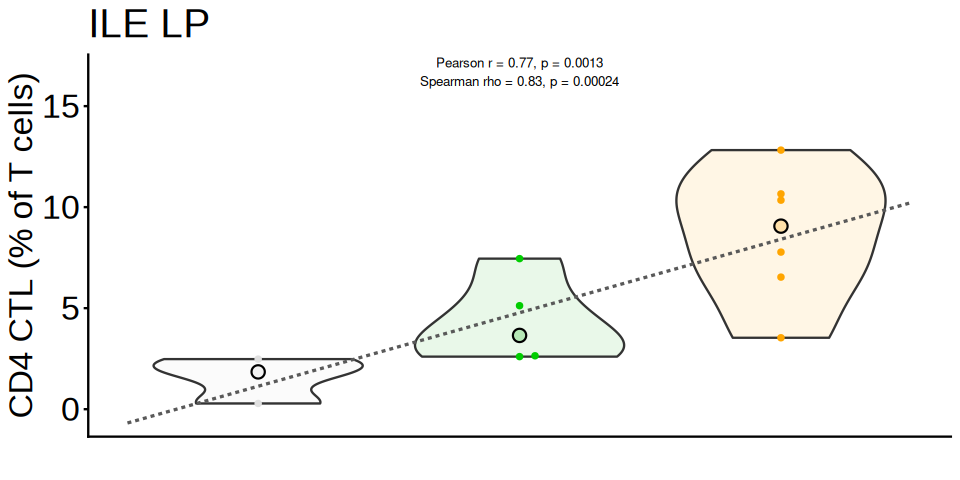

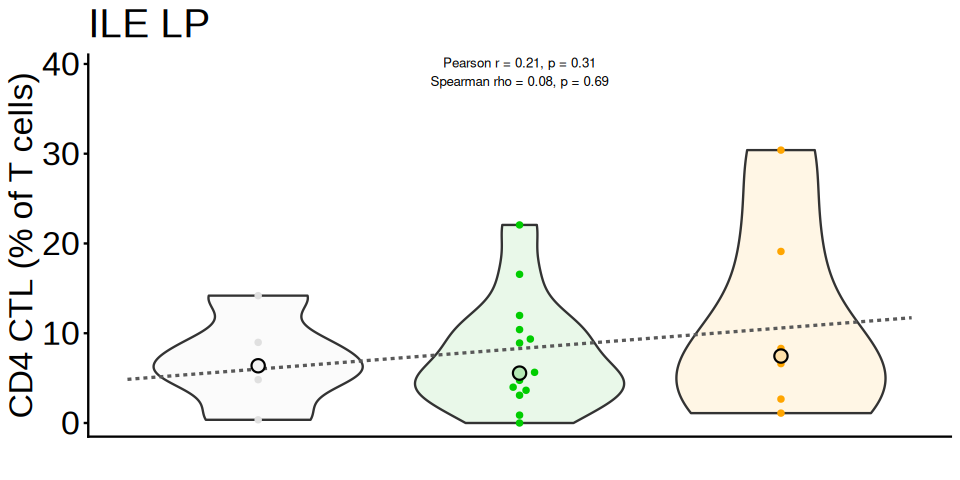

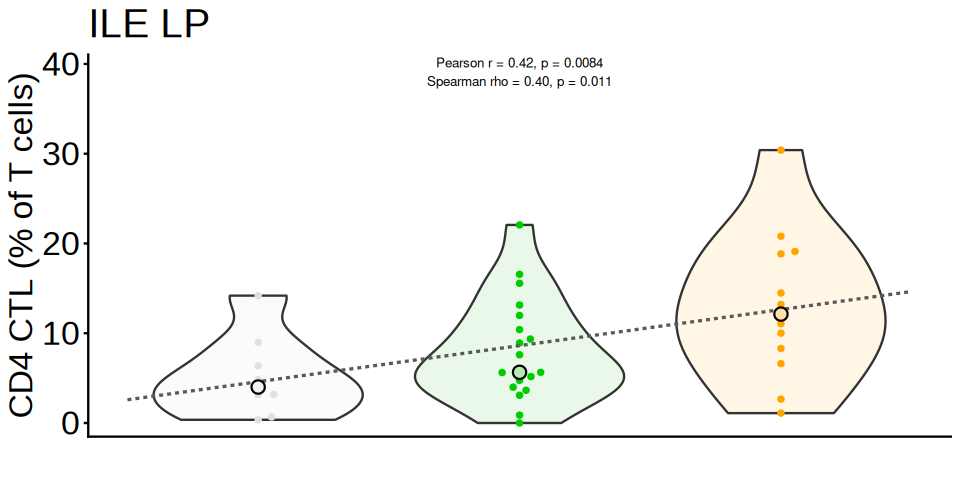

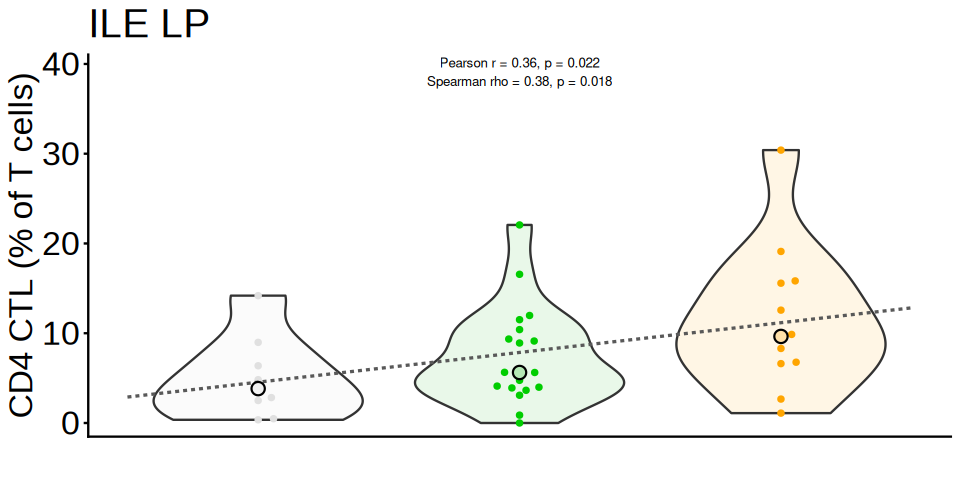

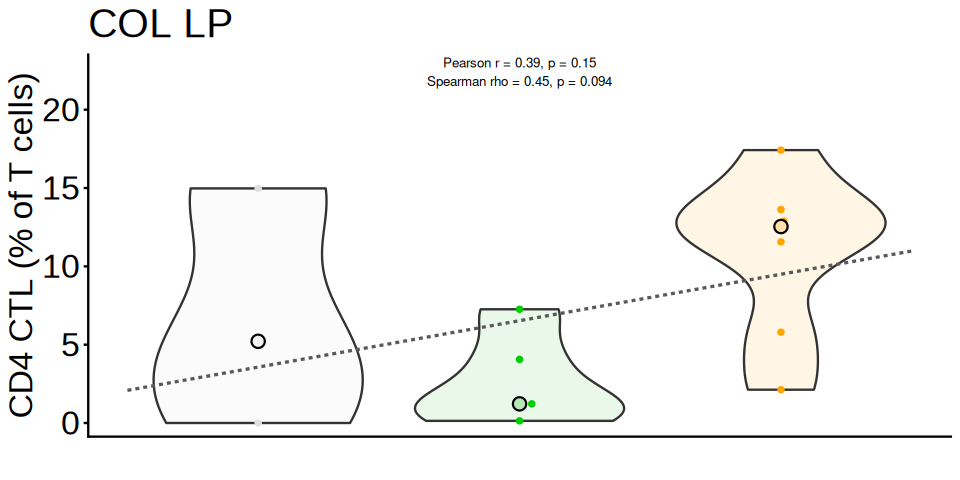

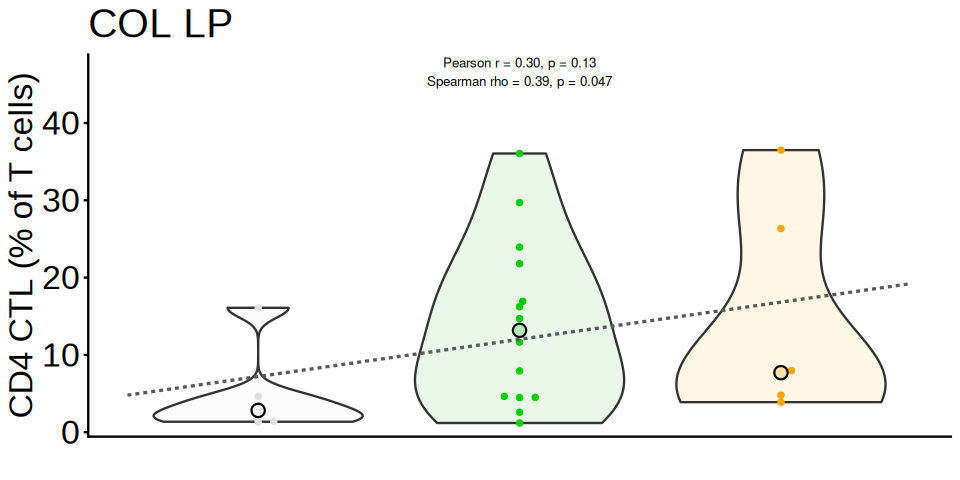

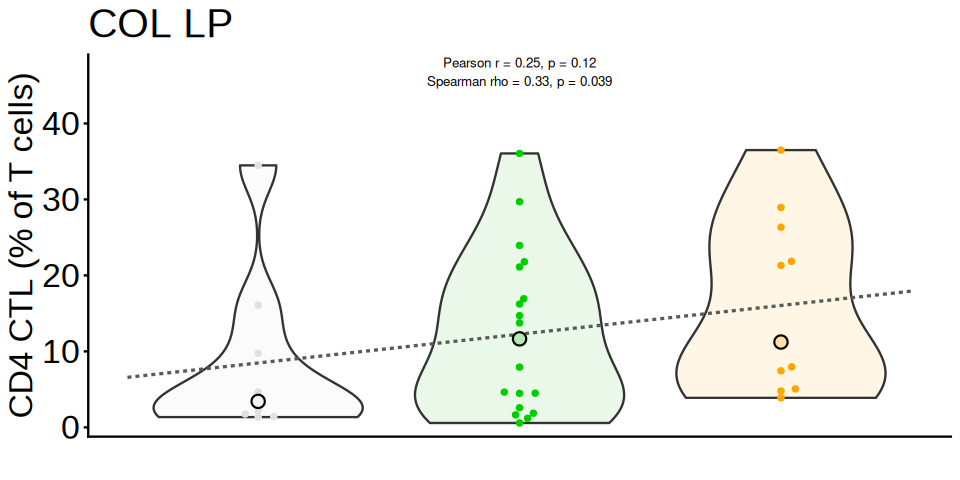

# A tibble: 2 × 5
  tissue layer n_total n_both n_single
  <chr>  <chr>   <int>  <int>    <int>
1 COL    LP         42     12       30
2 ILE    LP         39     14       25
Plots and data saved to: figures/cd4_freq_violin/response_CD4CTL_correlations_20261107_221806 


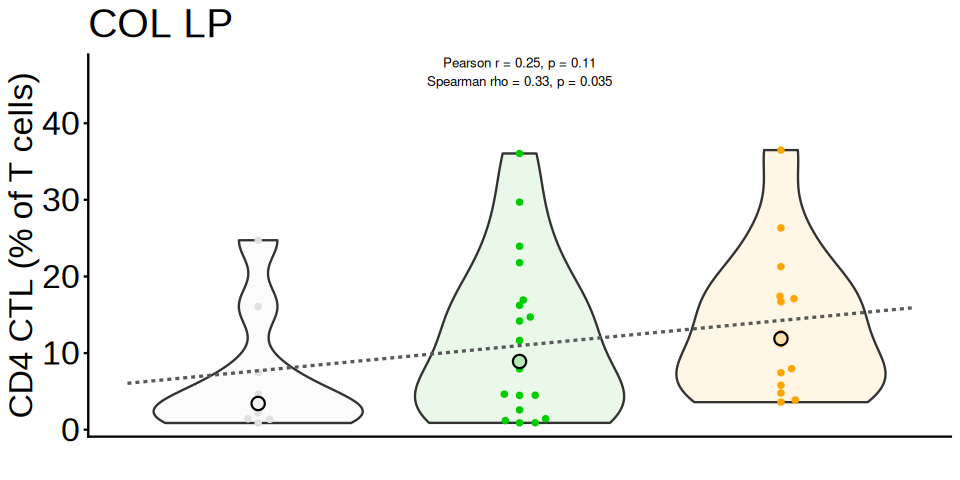

In [357]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(readr)
library(ggbeeswarm)
library(purrr)

# ============================================================
# 1. Settings
# ============================================================
out_dir <- paste0(
  "figures/cd4_freq_violin/response_CD4CTL_correlations_",
  format(Sys.time(), "%Y%m%d_%H%M%S")
)
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

response_levels <- c("NOA", "FR", "PR")
response_colors <- c(NOA = "grey88", FR = "green3", PR = "orange")
response_fills <- c(NOA = "grey95", FR = "#B5E8B5", PR = "#FFE0A8")

format_p <- function(p) {
  ifelse(is.na(p), "NA", format(signif(p, 2), scientific = FALSE, trim = TRUE))
}

get_nonmissing <- function(x) {
  vals <- unique(x[!is.na(x)])
  if (length(vals) == 0) return(x[NA_integer_][1])
  if (length(vals) > 1) stop("Conflicting nonmissing metadata within a sample group.")
  vals[1]
}

# ============================================================
# 2. CD baseline data: ILE LP and COL LP only
# ============================================================
df_base <- df_all_data %>%
  dplyr::filter(
    dataset %in% c("GUT 3p", "GUT 5p"),
    diagnosis == "CD",
    timepoint == "T0",
    tissue %in% c("ILE", "COL"),
    layer == "LP",
    antitnf_response %in% response_levels,
    !is.na(participant_id2),
    annotations2 == "CD4 CTL",
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2),
    antitnf_response = as.character(antitnf_response)
  )

# Check that each biological participant has a consistent response.
response_conflicts <- df_base %>%
  dplyr::group_by(participant_id2) %>%
  dplyr::summarise(
    n_responses = dplyr::n_distinct(antitnf_response),
    responses = paste(sort(unique(antitnf_response)), collapse = ", "),
    .groups = "drop"
  ) %>%
  dplyr::filter(n_responses > 1)
if (nrow(response_conflicts) > 0) {
  print(response_conflicts, n = Inf)
  stop("Conflicting response metadata for the same participant.")
}

# Average repeated samples within a chemistry before combining chemistries.
df_base <- df_base %>%
  dplyr::group_by(dataset, participant_id2, tissue, layer, annotations2) %>%
  dplyr::summarise(
    freq = mean(freq),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    cohort_gut = get_nonmissing(cohort_gut),
    .groups = "drop"
  )

# ============================================================
# 3. Four datasets, matching the original script
# ============================================================
df_3p <- df_base %>%
  dplyr::filter(dataset == "GUT 3p", cohort_gut == "Identification") %>%
  dplyr::mutate(plot_dataset = "3p", n_datasets = 1L)

df_5p <- df_base %>%
  dplyr::filter(dataset == "GUT 5p", cohort_gut == "Validation") %>%
  dplyr::mutate(plot_dataset = "5p", n_datasets = 1L)

df_all5p <- df_base %>%
  dplyr::filter(dataset == "GUT 5p") %>%
  dplyr::mutate(plot_dataset = "all5p", n_datasets = 1L)

df_all_combined <- df_base %>%
  dplyr::group_by(participant_id2, tissue, layer, annotations2) %>%
  dplyr::summarise(
    freq = mean(freq),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  ) %>%
  dplyr::mutate(plot_dataset = "all")

df_plot_all <- dplyr::bind_rows(df_3p, df_5p, df_all5p, df_all_combined) %>%
  dplyr::mutate(
    plot_dataset = factor(plot_dataset, levels = c("3p", "5p", "all5p", "all")),
    antitnf_response = factor(antitnf_response, levels = response_levels),
    response_numeric = as.numeric(antitnf_response) - 1,
    freq_pct = freq * 100
  )

# ============================================================
# 4. Pearson and Spearman correlations per annotation
# ============================================================
run_correlations <- function(d) {
  x <- d$response_numeric
  y <- d$freq_pct
  ok <- is.finite(x) & is.finite(y)
  x <- x[ok]
  y <- y[ok]

  if (length(x) < 3 || dplyr::n_distinct(x) < 2 ||
      dplyr::n_distinct(y) < 2) {
    return(tibble::tibble(
      n = length(x), pearson_r = NA_real_, pearson_p = NA_real_,
      spearman_rho = NA_real_, spearman_p = NA_real_
    ))
  }

  pearson <- stats::cor.test(x, y, method = "pearson")
  spearman <- suppressWarnings(
    stats::cor.test(x, y, method = "spearman", exact = FALSE)
  )
  tibble::tibble(
    n = length(x),
    pearson_r = unname(pearson$estimate),
    pearson_p = pearson$p.value,
    spearman_rho = unname(spearman$estimate),
    spearman_p = spearman$p.value
  )
}

# ============================================================
# 5. Plot each dataset for ILE LP and COL LP
# ============================================================
all_counts <- list()
all_correlations <- list()

for (tissue_i in c("ILE", "COL")) {
  for (dataset_i in c("3p", "5p", "all5p", "all")) {
    d <- df_plot_all %>%
      dplyr::filter(tissue == tissue_i, layer == "LP", plot_dataset == dataset_i)
    if (nrow(d) == 0) next

    file_prefix <- paste(dataset_i, tissue_i, "LP", sep = "_")

    readr::write_csv(d, file.path(out_dir, paste0(file_prefix, "_source.csv")))

    counts <- d %>%
      dplyr::group_by(annotations2, antitnf_response, .drop = FALSE) %>%
      dplyr::summarise(
        n_participants = dplyr::n_distinct(participant_id2),
        .groups = "drop"
      ) %>%
      dplyr::mutate(plot_dataset = dataset_i, tissue = tissue_i, layer = "LP")
    all_counts[[file_prefix]] <- counts
    readr::write_csv(counts, file.path(out_dir, paste0(file_prefix, "_counts.csv")))

    correlations <- d %>%
      dplyr::group_by(annotations2) %>%
      dplyr::group_modify(~ run_correlations(.x)) %>%
      dplyr::ungroup() %>%
      dplyr::mutate(
        plot_dataset = dataset_i,
        tissue = tissue_i,
        layer = "LP",
        label = paste0(
          "Pearson r = ", ifelse(is.na(pearson_r), "NA", sprintf("%.2f", pearson_r)),
          ", p = ", format_p(pearson_p),
          "\nSpearman rho = ", ifelse(is.na(spearman_rho), "NA", sprintf("%.2f", spearman_rho)),
          ", p = ", format_p(spearman_p)
        )
      )
    all_correlations[[file_prefix]] <- correlations
    readr::write_csv(
      correlations, file.path(out_dir, paste0(file_prefix, "_correlations.csv"))
    )

    # Only fit a line where at least two response categories are represented.
    fit_annotations <- correlations %>%
      dplyr::filter(!is.na(pearson_r)) %>%
      dplyr::pull(annotations2)
    d_fit <- d %>% dplyr::filter(annotations2 %in% fit_annotations)

    p <- ggplot(d, aes(x = response_numeric, y = freq_pct)) +
      geom_violin(
        aes(group = antitnf_response, fill = antitnf_response),
        alpha = 0.3, scale = "width", width = 0.8
      ) +
      ggbeeswarm::geom_beeswarm(
        aes(group = antitnf_response, color = antitnf_response),
        size = 1.5, cex = 2, shape = 16, corral = "random"
      ) +
      geom_smooth(
        data = d_fit, aes(group = 1),
        method = "lm", formula = y ~ x,
        se = FALSE, linetype = "dashed", color = "grey35",
        linewidth = 0.7, fullrange = TRUE
      ) +
      stat_summary(
        aes(group = antitnf_response, fill = antitnf_response),
        fun = median, geom = "point", shape = 21,
        size = 3, stroke = 0.7, color = "black"
      ) +
      geom_text(
        data = correlations,
        aes(x = 1, y = Inf, label = label),
        inherit.aes = FALSE, vjust = 1.1, size = 2.7
      ) +
      scale_x_continuous(
        breaks = 0:2, labels = response_levels,
        limits = c(-0.5, 2.5)
      ) +
      scale_fill_manual(values = response_fills, drop = FALSE) +
      scale_color_manual(values = response_colors, drop = FALSE) +
      scale_y_continuous(
        expand = expansion(mult = c(0.05, 0.35))
      ) +
      labs(title = paste(tissue_i, "LP"), x = "", y = "CD4 CTL (% of T cells)") +
      theme_classic() +
      ggtheme() +
      theme(
        text = element_text(family = "Arial"),
        strip.background = element_blank(),
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank(),
        legend.position = "none"
      )

    ggsave(
      file.path(out_dir, paste0(file_prefix, ".svg")),
      p, width = 3.5, height = 3.7, units = "in"
    )
    ggsave(
      file.path(out_dir, paste0(file_prefix, ".png")),
      p, width = 3.5, height = 3.7, units = "in", dpi = 300
    )
    print(p)
  }
}

# ============================================================
# 6. Save combined results and overlap summary
# ============================================================
readr::write_csv(
  dplyr::bind_rows(all_counts),
  file.path(out_dir, "all_participant_counts.csv")
)
readr::write_csv(
  dplyr::bind_rows(all_correlations),
  file.path(out_dir, "all_correlation_results.csv")
)

overlap_summary <- df_all_combined %>%
  dplyr::group_by(tissue, layer) %>%
  dplyr::summarise(
    n_total = dplyr::n_distinct(participant_id2),
    n_both = dplyr::n_distinct(participant_id2[n_datasets == 2]),
    n_single = dplyr::n_distinct(participant_id2[n_datasets == 1]),
    .groups = "drop"
  )
print(overlap_summary, n = Inf)
readr::write_csv(overlap_summary, file.path(out_dir, "overlap_summary.csv"))
cat("Plots and data saved to:", out_dir, "\n")


In [361]:
ls()

[1] "all_correlations"      "all_counts"            "all_range_counts"     
  [4] "all_tests"             "all_wilcoxon"          "annotation_counts"    
  [7] "bld_samples_both"      "cohort_i"              "cohorts"              
 [10] "comparisons"           "conflicts"             "cor_result"           
 [13] "cor_results"           "correlations"          "count_participants"   
 [16] "counts"                "counts_final"          "d"                    
 [19] "d_fit"                 "dataset_i"             "df_3p"                
 [22] "df_5p"                 "df_5p_nonoverlap"      "df_all"               
 [25] "df_all_combined"       "df_all_data"           "df_all_data_corrected"
 [28] "df_all_data_severity"  "df_all_data2"          "df_all_severity"      
 [31] "df_all5p"              "df_base"               "df_bld"               
 [34] "df_filt"               "df_outliers"           "df_plot"              
 [37] "df_plot_all"           "df_response_base"      "df_response_extra"    
 [40] "df_weighted"           "df_weighted_bld"       "df1"                  
 [43] "df2"                   "df4_3p"                "df4_3p_bl3"           
 [46] "df4_5p"                "df4_5p_bl3"            "diagnosis_colors"     
 [49] "diagnosis_levels"      "duplicate_rows"        "duplicates"           
 [52] "extra_in_md"           "file_prefix"           "fit_annotations"      
 [55] "format_p"              "get_nonmissing"        "ggtheme"              
 [58] "gut_samples_both"      "i"                     "ids_3p"               
 [61] "j"                     "label"                 "layer_i"              
 [64] "md_5p_new"             "md_reference"          "md_reference_clean"   
 [67] "md_severity"           "mismatch_details"      "mismatches"           
 [70] "missing_combinations"  "n_other"               "n_severe"             
 [73] "numeric_vars"          "out_dir"               "overlap_summary"      
 [76] "p"                     "p_format"              "p_value"              
 [79] "participant_counts"    "plot_diagnosis"        "plot_height"          
 [82] "plot_response"         "plot_severity"         "plot_severity_UC"     
 [85] "plot_width"            "prefix_i"              "pt_3p"                
 [88] "range_levels"          "range_vars"            "remaining_mismatches" 
 [91] "response_colors"       "response_conflicts"    "response_fills"       
 [94] "response_levels"       "run_correlations"      "run_wilcox"           
 [97] "run_wilcoxon"          "sample_has_R_gut"      "save_plot"            
[100] "severity_conflicts"    "severity_correlations" "severity_levels"      
[103] "standardize_metadata"  "stat"                  "stat_labels"          
[106] "stats_bld"             "test_results"          "tissue_i"             
[109] "tissue_layers"         "tissues"               "unknown"              
[112] "v"                     "valid_groups"          "var_i"                
[115] "visits"                "wilcox_plot"           "wilcox_results"       
[118] "y_max"                 "y_positions"           "y_step"

### Severity score

In [308]:
df_all_data

...1,data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer,dataset,participant_id2,cohort_gut
<dbl>,<chr>,<fct>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,001-017_T0_DUO_LP_5p_GEX,CD4 CTL,0.0027700831,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
2,001-017_T0_DUO_LP_5p_GEX,IEL,0.0424746076,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
3,001-017_T0_DUO_LP_5p_GEX,Tcm,0.0027700831,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
4,001-017_T0_DUO_LP_5p_GEX,Mixed Teff1,0.0138504155,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
5,001-017_T0_DUO_LP_5p_GEX,Th17,0.2502308403,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
6,001-017_T0_DUO_LP_5p_GEX,Mixed Teff2,0.6066481994,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
7,001-017_T0_DUO_LP_5p_GEX,Treg,0.0812557710,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
8,001-017_T0_DUO_LP_5p_GEX,Tfh,0.0000000000,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification
9,001-017_T0_DUO_LP_5p_GEX,Naive,0.0000000000,FGID,NOA,001-017,T0,DUO,LP,GUT 5p,001-017,Identification


In [309]:
colnames(md_5p_new)

[1] "sample"                      "data_folder"                
 [3] "diagnosis"                   "subgroup_primary"           
 [5] "subgroup_secondary"          "subgroup_tertiary"          
 [7] "Rome_coarse"                 "Rome_classification"        
 [9] "antitnf_response"            "participant_id"             
[11] "timepoint"                   "site"                       
[13] "tissue"                      "layer"                      
[15] "prime"                       "version_10x"                
[17] "data_type"                   "seq_run"                    
[19] "collection_purpose"          "days"                       
[21] "antitnf"                     "antitnf_repeat"             
[23] "sample_inflamed"             "score_type"                 
[25] "severity_score"              "weighted_severity_score"    
[27] "severity_score_date"         "severity_score_range"       
[29] "weighted_score_range"        "internal_flag"              
[31] "y2passed"                    "diagnosis_R_change"         
[33] "y2response"                  "micro_rc_inflammation"      
[35] "micro_lc_inflammation"       "dob"                        
[37] "age"                         "sex"                        
[39] "collection_date"             "duo_inflammation"           
[41] "ile_inflammation"            "race"                       
[43] "ethnicity"                   "col_inflammation"           
[45] "perianal_inflammation"       "recto_sigmoid_inflammation" 
[47] "descending_inflammation"     "transverse_inflammation"    
[49] "ascending_inflammation"      "micro_duo_inflammation"     
[51] "micro_ile_inflammation"      "micro_col_inflammation"     
[53] "colon_site"                  "experiment_protocol_version"
[55] "Paris"                       "antitnf_repeat_old"

In [311]:
md_5p_new$weighted_score_range  %>% table

.
    Mild Moderate       NM   Severe 
     262       98      110       75 

In [313]:
md_5p_new  %>% dplyr::filter(diagnosis == "CD")  %>% pull(severity_score_range)  %>% table

.
     Mild  Moderate Remission    Severe 
      225       124        31        65 

In [320]:
library(dplyr)

# ============================================================
# 1. Correct weighted severity score for participant 003-078
# ============================================================

md_5p_new <- md_5p_new %>%
  dplyr::mutate(
    weighted_severity_score = dplyr::if_else(
      participant_id == "003-078",
      2.5,
      as.numeric(weighted_severity_score)
    )
  )

# ============================================================
# 2. Helper: prefer nonmissing values, detect conflicts
# ============================================================

get_nonmissing <- function(x) {

  values <- unique(x[!is.na(x)])

  if (length(values) == 0) {
    return(x[NA_integer_][1])
  }

  if (length(values) > 1) {
    stop(
      "Conflicting nonmissing values remain in severity metadata."
    )
  }

  values[1]
}

# ============================================================
# 3. Consolidate severity metadata
# ============================================================

md_severity <- md_5p_new %>%
  dplyr::select(
    participant_id,
    timepoint,
    tissue,
    layer,
    severity_score_range,
    weighted_score_range,
    severity_score,
    weighted_severity_score
  ) %>%
  dplyr::group_by(
    participant_id,
    timepoint,
    tissue,
    layer
  ) %>%
  dplyr::summarise(
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    .groups = "drop"
  )

# ============================================================
# 4. Join severity metadata to df_all_data
# ============================================================

df_all_data_severity <- df_all_data %>%
  dplyr::left_join(
    md_severity,
    by = c(
      "participant_id2" = "participant_id",
      "timepoint",
      "tissue",
      "layer"
    ),
    relationship = "many-to-one"
  )

# ============================================================
# 5. Verify row counts
# ============================================================

stopifnot(
  nrow(df_all_data_severity) == nrow(df_all_data)
)

cat("Original rows:", nrow(df_all_data), "\n")
cat("Joined rows:", nrow(df_all_data_severity), "\n")

# ============================================================
# 6. Check severity values for participant 003-078
# ============================================================

df_all_data_severity %>%
  dplyr::filter(participant_id2 == "003-078") %>%
  dplyr::distinct(
    participant_id2,
    timepoint,
    tissue,
    layer,
    severity_score,
    weighted_severity_score,
    severity_score_range,
    weighted_score_range
  ) %>%
  print(n = Inf)

# ============================================================
# 7. Check missing severity values after joining
# ============================================================

df_all_data_severity %>%
  dplyr::group_by(dataset, tissue, layer) %>%
  dplyr::summarise(
    n_participants = dplyr::n_distinct(participant_id2),
    n_with_severity = dplyr::n_distinct(
      participant_id2[!is.na(severity_score)]
    ),
    n_with_weighted_severity = dplyr::n_distinct(
      participant_id2[!is.na(weighted_severity_score)]
    ),
    .groups = "drop"
  ) %>%
  print(n = Inf)

Original rows: 8084 
Joined rows: 8084 
# A tibble: 0 × 8
# ℹ 8 variables: participant_id2 <chr>, timepoint <chr>, tissue <chr>,
#   layer <chr>, severity_score <dbl>, weighted_severity_score <dbl>,
#   severity_score_range <chr>, weighted_score_range <chr>
# A tibble: 15 × 6
   dataset tissue layer n_participants n_with_severity n_with_weighted_severity
   <chr>   <chr>  <chr>          <int>           <int>                    <int>
 1 BLD 3p  BLD    CD3               39              13                       13
 2 BLD 5p  BLD    CD3               61              35                       33
 3 BLD 5p  BLD    PBMC              24              17                       18
 4 GUT 3p  COL    EPI               16               1                        1
 5 GUT 3p  COL    LP                43              16                       14
 6 GUT 3p  DUO    EPI               17               1                        1
 7 GUT 3p  DUO    LP                43              12                       12
 8 

In [323]:
df_all_data_severity$severity_score_range  %>% table

.
     Mild  Moderate        NM Remission    Severe 
     1576      1258      2733       200       522 

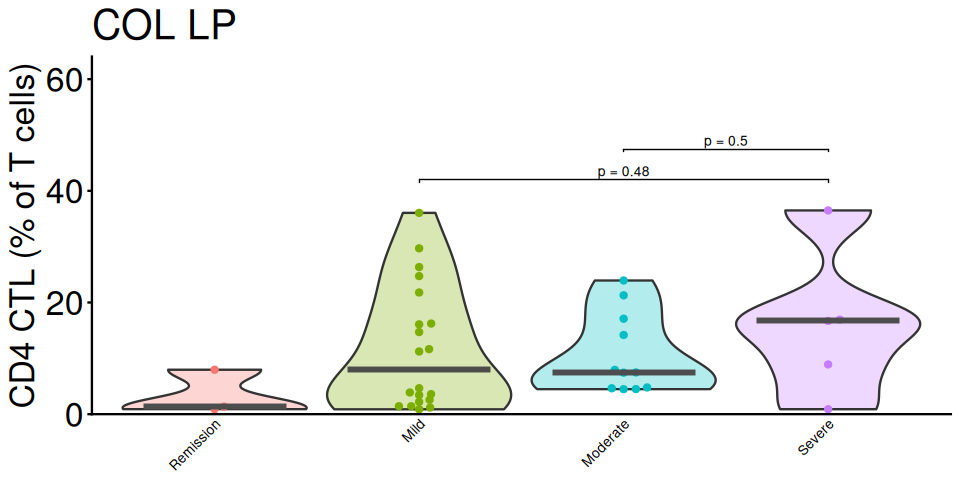

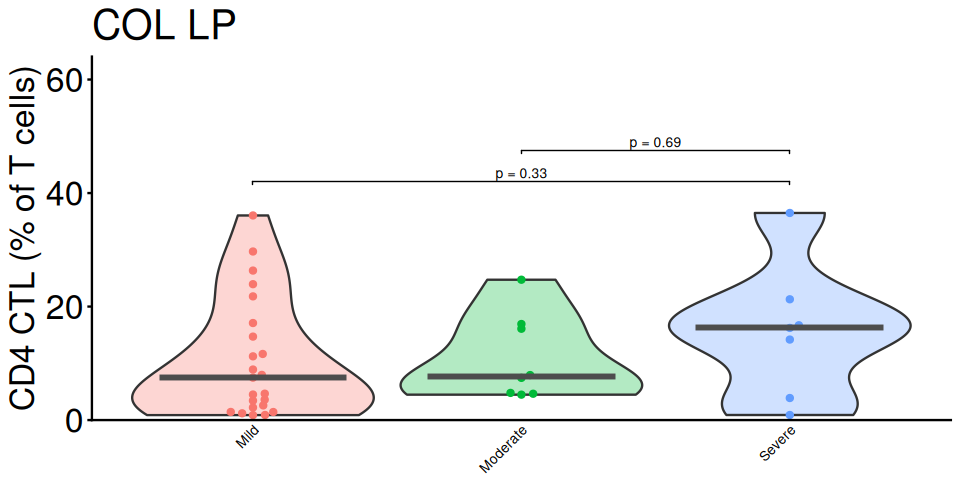

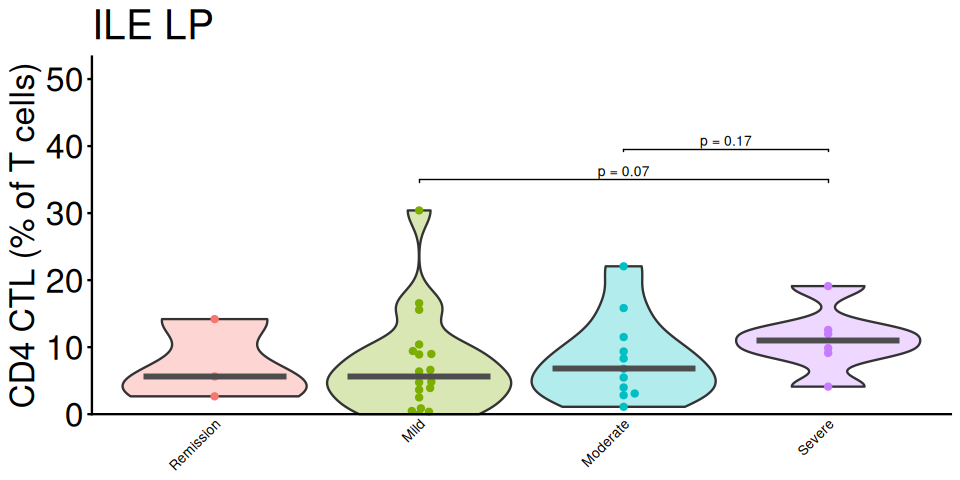

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


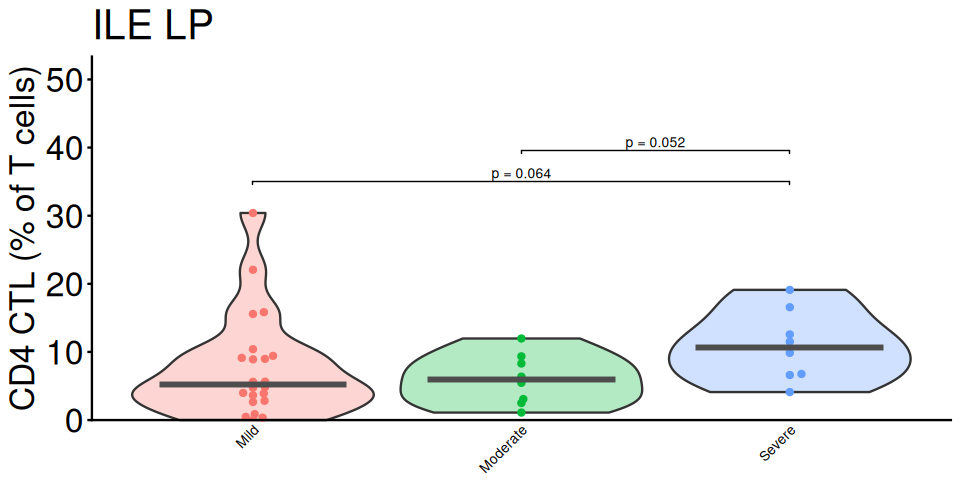

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


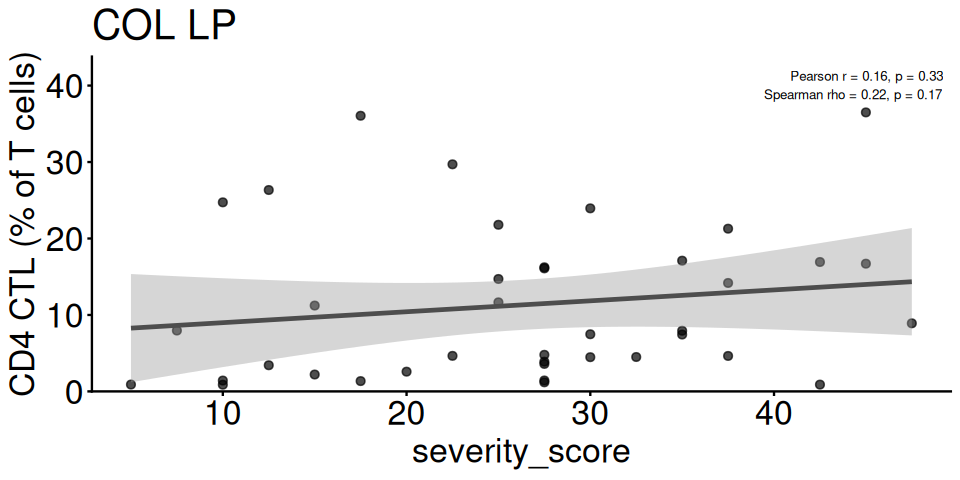

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


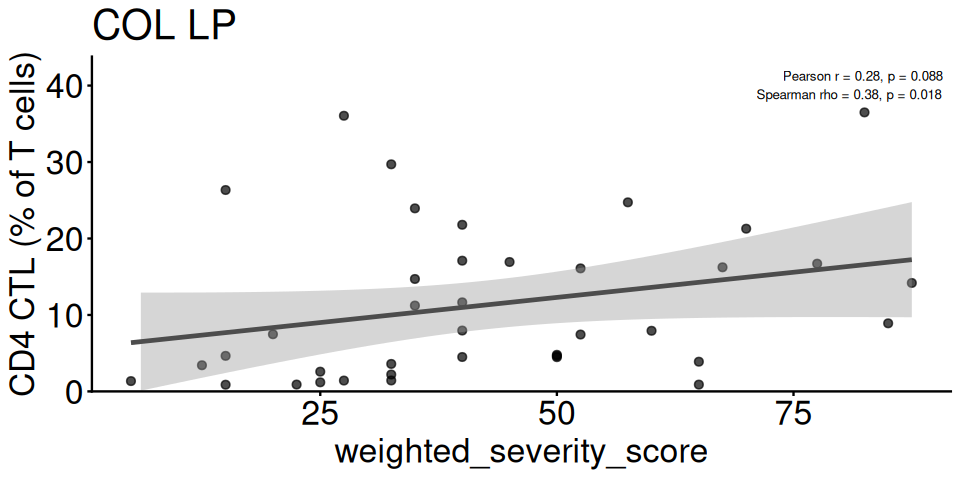

`geom_smooth()` using formula = 'y ~ x'


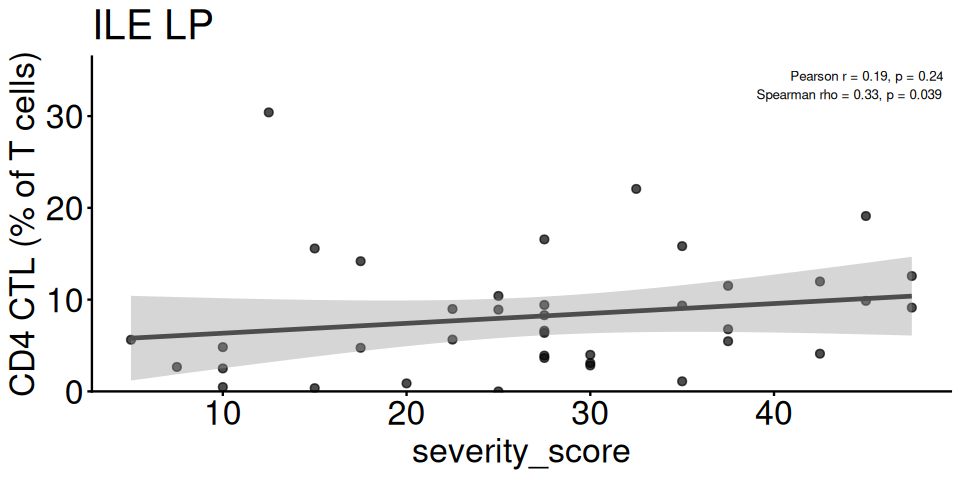

# A tibble: 2 × 4
  tissue n_total n_both n_single
  <chr>    <int>  <int>    <int>
1 COL         42     12       30
2 ILE         39     14       25


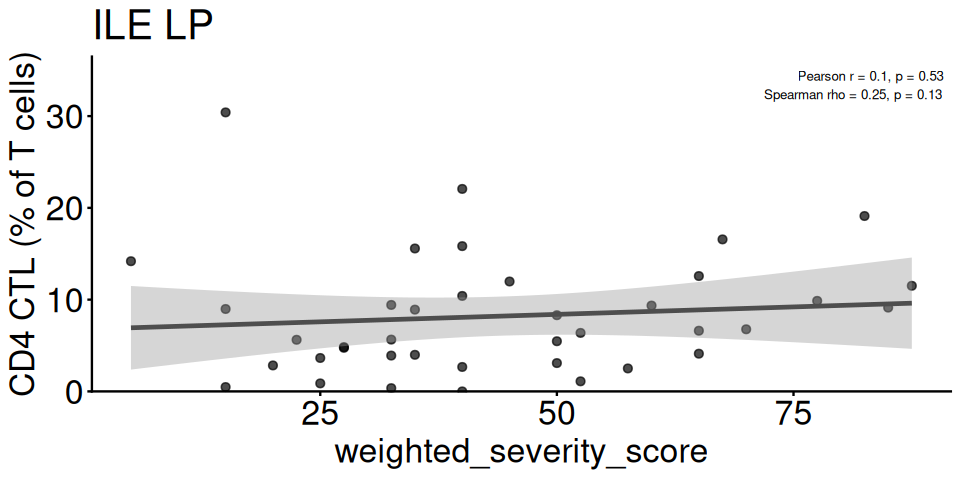

In [325]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(readr)
library(ggbeeswarm)

# ============================================================
# 1. Settings
# ============================================================

out_dir <- paste0(
  "figures/cd4_freq_violin/severity_CD4CTL_",
  format(Sys.time(), "%Y%m%d_%H%M%S")
)

dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

range_levels <- c("Remission", "Mild", "Moderate", "Severe", "NM")

range_vars <- c(
  "severity_score_range",
  "weighted_score_range"
)

numeric_vars <- c(
  "severity_score",
  "weighted_severity_score"
)

# ============================================================
# 2. Prepare CD4 CTL data
# ============================================================

df_base <- df_all_data_severity %>%
  dplyr::filter(
    dataset %in% c("GUT 3p", "GUT 5p"),
    diagnosis == "CD",
    timepoint == "T0",
    tissue %in% c("COL", "ILE"),
    layer == "LP",
    annotations2 == "CD4 CTL",
    !is.na(participant_id2),
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2)
  )

# Check duplicate frequencies within each chemistry
duplicates <- df_base %>%
  dplyr::count(
    dataset, participant_id2, tissue, layer
  ) %>%
  dplyr::filter(n > 1)

if (nrow(duplicates) > 0) {
  print(duplicates, n = Inf)
  stop("Duplicate participant/tissue/chemistry rows.")
}

# Check that severity metadata is consistent across chemistries
severity_conflicts <- df_base %>%
  dplyr::group_by(participant_id2, tissue, layer) %>%
  dplyr::summarise(
    dplyr::across(
      dplyr::all_of(c(range_vars, numeric_vars)),
      ~ dplyr::n_distinct(.x, na.rm = TRUE)
    ),
    .groups = "drop"
  ) %>%
  dplyr::filter(
    dplyr::if_any(
      dplyr::all_of(c(range_vars, numeric_vars)),
      ~ .x > 1
    )
  )

if (nrow(severity_conflicts) > 0) {
  print(severity_conflicts, n = Inf)
  stop("Conflicting severity metadata across chemistries.")
}

# Prefer nonmissing severity metadata
get_nonmissing <- function(x) {
  values <- unique(x[!is.na(x)])
  if (length(values) == 0) return(x[NA_integer_][1])
  if (length(values) > 1) stop("Conflicting severity values.")
  values[1]
}

# One observation per participant/tissue
df_plot <- df_base %>%
  dplyr::group_by(participant_id2, tissue, layer) %>%
  dplyr::summarise(
    freq = mean(freq),
    n_datasets = dplyr::n_distinct(dataset),
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    .groups = "drop"
  ) %>%
  dplyr::mutate(
    freq_pct = freq * 100,
    dplyr::across(
      dplyr::all_of(range_vars),
      ~ factor(as.character(.x), levels = range_levels)
    )
  )

# Check for unexpected range labels
for (v in range_vars) {
  unknown <- setdiff(
    unique(as.character(df_base[[v]][!is.na(df_base[[v]])])),
    range_levels
  )
  if (length(unknown) > 0) {
    warning(v, " has unexpected values: ", paste(unknown, collapse = ", "))
  }
}

readr::write_csv(
  df_plot,
  file.path(out_dir, "CD4CTL_severity_source.csv")
)

# ============================================================
# 3. Correlation helper
# ============================================================

run_correlations <- function(df, score_var) {

  x <- as.numeric(df[[score_var]])
  y <- df$freq_pct

  keep <- is.finite(x) & is.finite(y)
  x <- x[keep]
  y <- y[keep]

  if (
    length(x) < 3 ||
    dplyr::n_distinct(x) < 2 ||
    dplyr::n_distinct(y) < 2
  ) {
    return(tibble::tibble(
      n = length(x),
      pearson_r = NA_real_,
      pearson_p = NA_real_,
      spearman_rho = NA_real_,
      spearman_p = NA_real_
    ))
  }

  pearson <- stats::cor.test(x, y, method = "pearson")
  spearman <- suppressWarnings(
    stats::cor.test(x, y, method = "spearman", exact = FALSE)
  )

  tibble::tibble(
    n = length(x),
    pearson_r = unname(pearson$estimate),
    pearson_p = pearson$p.value,
    spearman_rho = unname(spearman$estimate),
    spearman_p = spearman$p.value
  )
}

format_p <- function(p) {
  ifelse(
    is.na(p),
    "NA",
    format(signif(p, 2), scientific = FALSE, trim = TRUE)
  )
}

library(ggpubr)

# ============================================================
# 4. Categorical severity plots + Wilcoxon tests
# ============================================================

all_range_counts <- list()
all_wilcoxon <- list()

comparisons <- list(
  c("Mild", "Severe"),
  c("Moderate", "Severe")
)

run_wilcoxon <- function(df, variable) {

  purrr::map_dfr(comparisons, function(comp) {

    d <- df %>%
      dplyr::filter(
        as.character(.data[[variable]]) %in% comp,
        !is.na(freq_pct)
      )

    n1 <- sum(as.character(d[[variable]]) == comp[1])
    n2 <- sum(as.character(d[[variable]]) == comp[2])

    if (n1 < 2 || n2 < 2) {
      p <- NA_real_
    } else {
      p <- suppressWarnings(
        stats::wilcox.test(
          freq_pct ~ factor(as.character(d[[variable]]),
                            levels = comp),
          data = d,
          exact = FALSE
        )$p.value
      )
    }

    tibble::tibble(
      group1 = comp[1],
      group2 = comp[2],
      n1 = n1,
      n2 = n2,
      p = p,
      p.format = ifelse(
        is.na(p),
        NA_character_,
        format(signif(p, 2), scientific = FALSE, trim = TRUE)
      )
    )
  })
}

for (tissue_i in c("COL", "ILE")) {

  for (var_i in range_vars) {

    df_filt <- df_plot %>%
      dplyr::filter(
        tissue == tissue_i,
        !is.na(.data[[var_i]])
      )

    if (nrow(df_filt) == 0) next

    file_prefix <- paste(tissue_i, "LP", var_i, sep = "_")

    counts <- df_filt %>%
      dplyr::group_by(.data[[var_i]], .drop = FALSE) %>%
      dplyr::summarise(
        n = dplyr::n_distinct(participant_id2),
        .groups = "drop"
      )

    all_range_counts[[file_prefix]] <- counts %>%
      dplyr::mutate(
        tissue = tissue_i,
        variable = var_i
      ) %>%
      dplyr::rename(category = 1)

    # Wilcoxon tests
    wilcox_results <- run_wilcoxon(df_filt, var_i) %>%
      dplyr::mutate(
        tissue = tissue_i,
        variable = var_i
      )

    all_wilcoxon[[file_prefix]] <- wilcox_results

    # Bracket positions
    y_max <- max(df_filt$freq_pct, na.rm = TRUE)
    y_step <- max(y_max * 0.15, 0.5)

    wilcox_plot <- wilcox_results %>%
      dplyr::filter(!is.na(p)) %>%
      dplyr::mutate(
        y.position = y_max + seq_len(dplyr::n()) * y_step,
        label = paste0("p = ", p.format)
      )

    p <- ggplot(
      df_filt,
      aes(x = .data[[var_i]], y = freq_pct)
    ) +
      geom_violin(
        aes(fill = .data[[var_i]]),
        alpha = 0.3,
        scale = "width",
        na.rm = TRUE
      ) +
      ggbeeswarm::geom_beeswarm(
        aes(color = .data[[var_i]]),
        size = 1.3,
        cex = 1.5,
        corral = "random"
      ) +
      stat_summary(
        fun = median,
        geom = "crossbar",
        width = 0.7,
        color = "grey30"
      ) +
      ggpubr::stat_pvalue_manual(
        wilcox_plot,
        label = "label",
        xmin = "group1",
        xmax = "group2",
        y.position = "y.position",
        tip.length = 0.01,
        bracket.size = 0.3,
        size = 2.8,
        inherit.aes = FALSE
      ) +
      scale_y_continuous(
        limits = c(0, NA),
        expand = expansion(mult = c(0, 0.35))
      ) +
      labs(
        title = paste(tissue_i, "LP"),
        x = NULL,
        y = "CD4 CTL (% of T cells)"
      ) +
      theme_classic() +
      theme(
        legend.position = "none",
        axis.text.x = element_text(
          angle = 45, hjust = 1, size = 8
        ),
        axis.ticks.x = element_blank()
      ) +
      ggtheme()

    ggsave(
      file.path(out_dir, paste0(file_prefix, ".svg")),
      p, width = 3.5, height = 5
    )

    ggsave(
      file.path(out_dir, paste0(file_prefix, ".png")),
      p, width = 3.5, height = 5, dpi = 300
    )

    print(p)
  }
}

# ============================================================
# 5. Numeric severity plots + correlations
# ============================================================

all_correlations <- list()

for (tissue_i in c("COL", "ILE")) {

  for (var_i in numeric_vars) {

    df_filt <- df_plot %>%
      dplyr::filter(
        tissue == tissue_i,
        !is.na(.data[[var_i]]),
        is.finite(as.numeric(.data[[var_i]]))
      )

    if (nrow(df_filt) == 0) next

    file_prefix <- paste(tissue_i, "LP", var_i, sep = "_")

    cor_result <- run_correlations(df_filt, var_i) %>%
      dplyr::mutate(
        tissue = tissue_i,
        variable = var_i
      )

    all_correlations[[file_prefix]] <- cor_result

    label <- paste0(
      "Pearson r = ", round(cor_result$pearson_r, 2),
      ", p = ", format_p(cor_result$pearson_p),
      "\nSpearman rho = ", round(cor_result$spearman_rho, 2),
      ", p = ", format_p(cor_result$spearman_p)
    )

    p <- ggplot(
      df_filt,
      aes(
        x = .data[[var_i]],
        y = freq_pct
      )
    ) +
      geom_point(
        size = 1.8,
        alpha = 0.7
      ) +
      geom_smooth(
        method = "lm",
        se = TRUE,
        color = "grey30"
      ) +
      annotate(
        "text",
        x = Inf,
        y = Inf,
        label = label,
        hjust = 1.05,
        vjust = 1.5,
        size = 2.7
      ) +
      scale_y_continuous(
        limits = c(0, NA),
        expand = expansion(mult = c(0, 0.20))
      ) +
      labs(
        title = paste(tissue_i, "LP"),
        x = var_i,
        y = "CD4 CTL (% of T cells)"
      ) +
      theme_classic() +
      ggtheme()

    ggsave(
      file.path(out_dir, paste0(file_prefix, ".svg")),
      p, width = 3.5, height = 5
    )

    ggsave(
      file.path(out_dir, paste0(file_prefix, ".png")),
      p, width = 3.5, height = 5, dpi = 300
    )

    print(p)
  }
}

# ============================================================
# 6. Save statistical results
# ============================================================

readr::write_csv(
  dplyr::bind_rows(all_wilcoxon),
  file.path(out_dir, "severity_range_wilcoxon.csv")
)

readr::write_csv(
  dplyr::bind_rows(all_correlations),
  file.path(out_dir, "severity_correlations.csv")
)

readr::write_csv(
  dplyr::bind_rows(all_range_counts),
  file.path(out_dir, "severity_range_counts.csv")
)

# ============================================================
# 6. Save statistics
# ============================================================

readr::write_csv(
  dplyr::bind_rows(all_correlations),
  file.path(out_dir, "severity_correlations.csv")
)

readr::write_csv(
  dplyr::bind_rows(all_range_counts),
  file.path(out_dir, "severity_range_counts.csv")
)

# ============================================================
# 7. Check participant counts and 3p/5p overlap
# ============================================================

df_plot %>%
  dplyr::group_by(tissue) %>%
  dplyr::summarise(
    n_total = dplyr::n_distinct(participant_id2),
    n_both = sum(n_datasets == 2),
    n_single = sum(n_datasets == 1),
    .groups = "drop"
  ) %>%
  print(n = Inf)

### Final plots gut

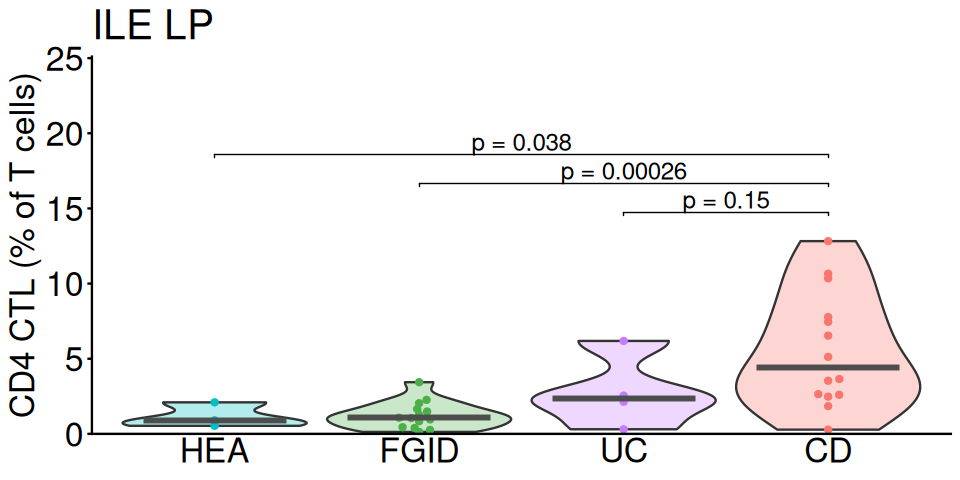

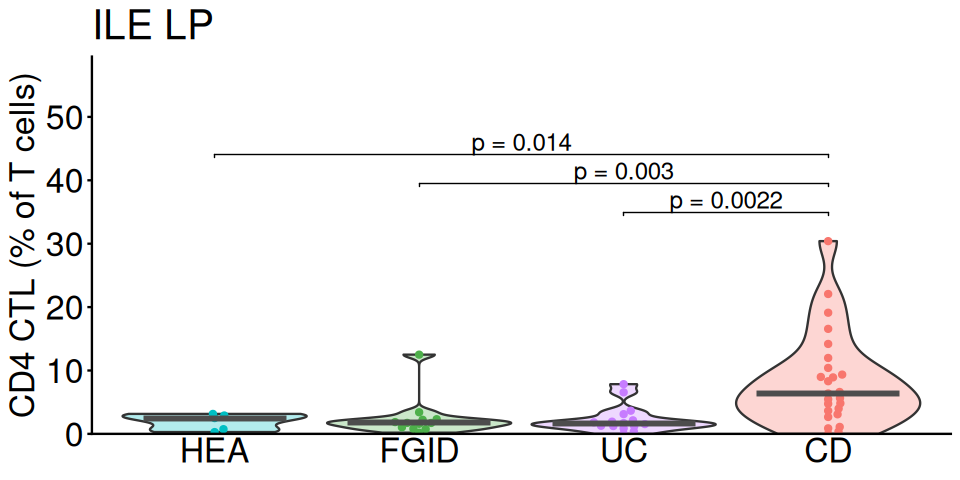

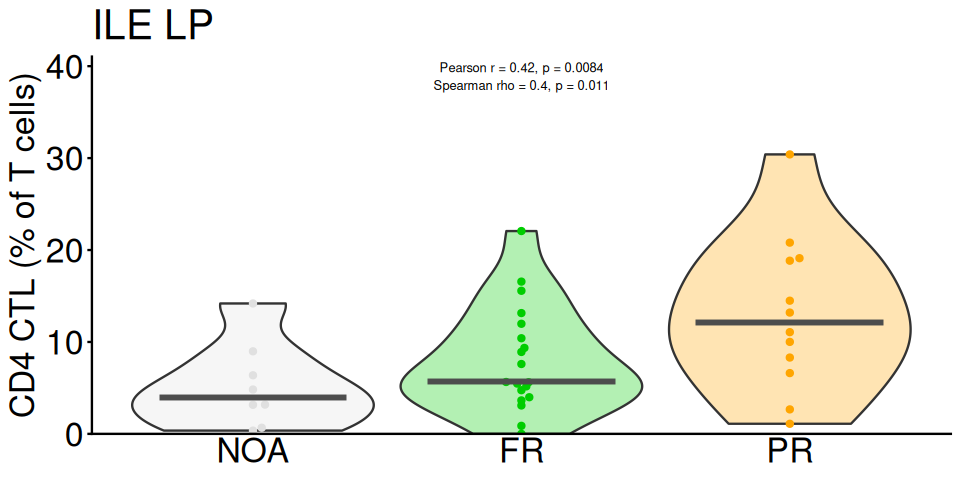

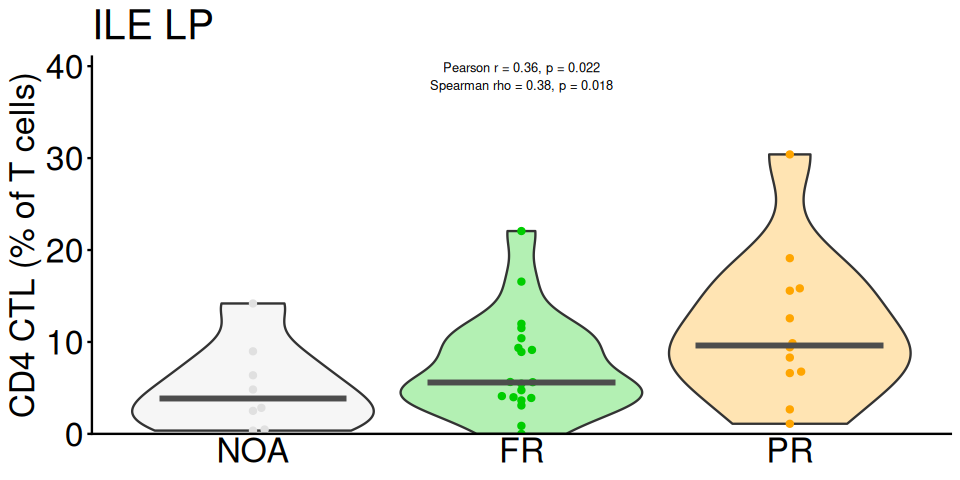

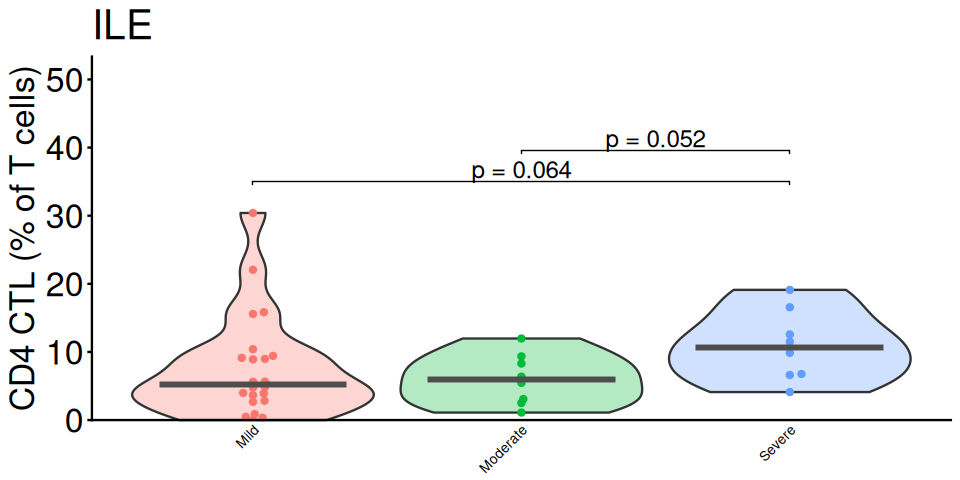

...

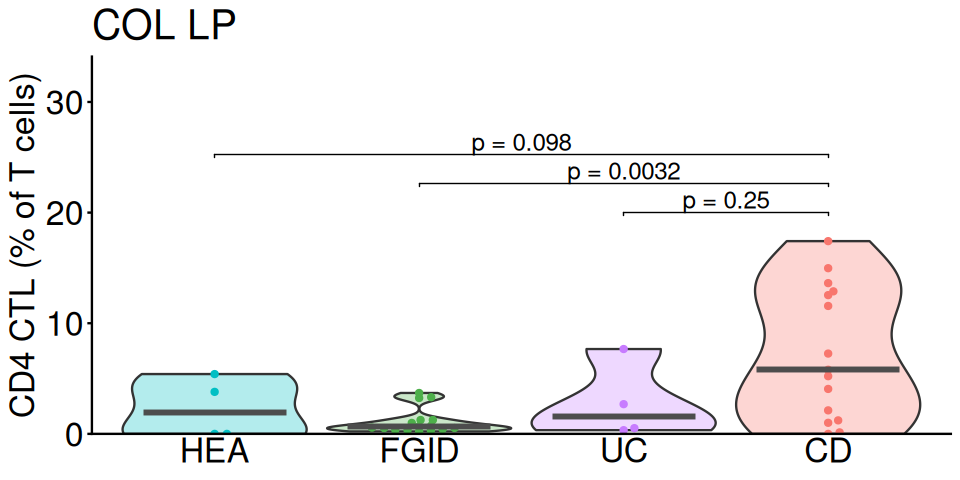

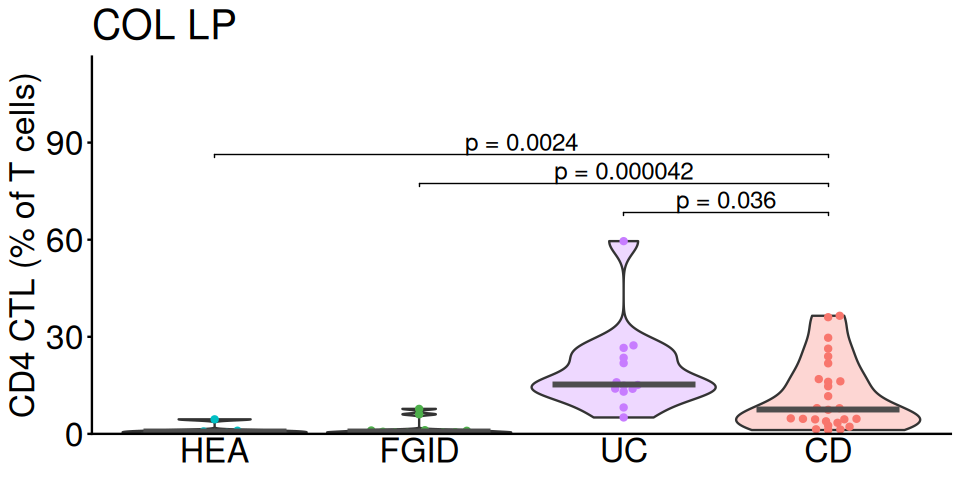

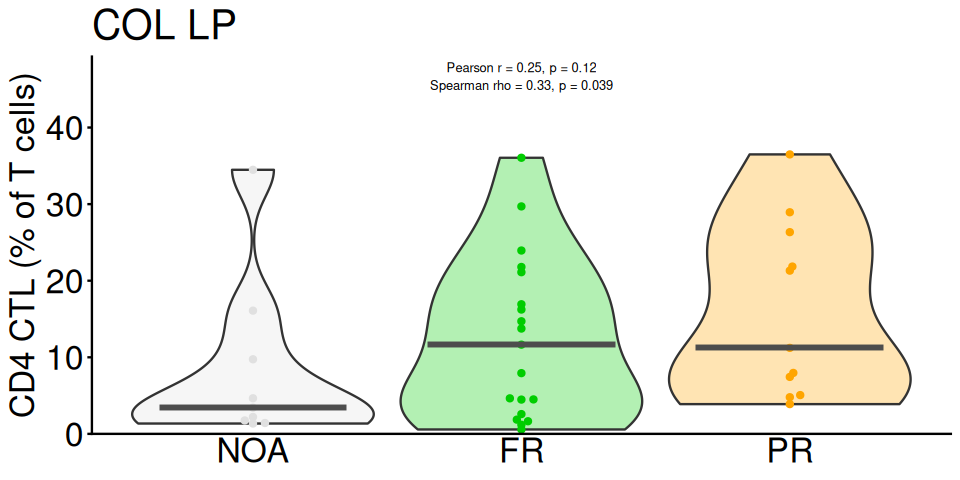

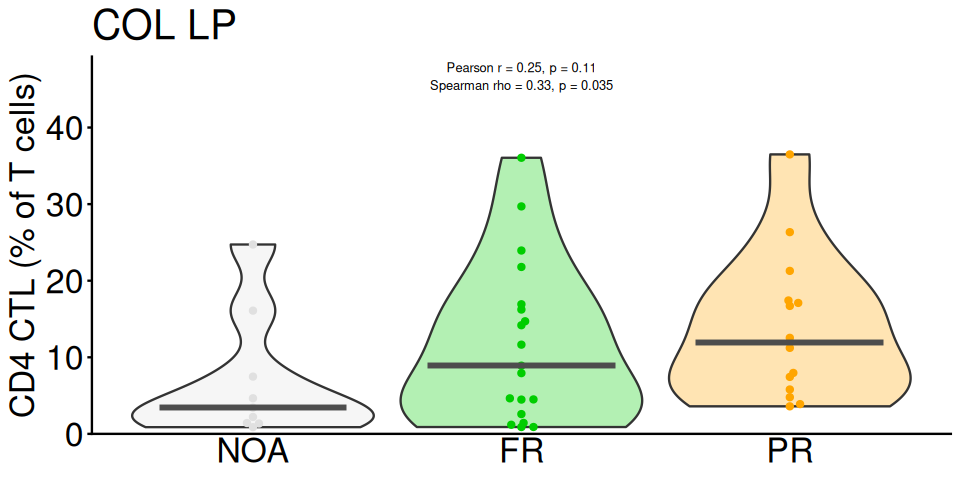

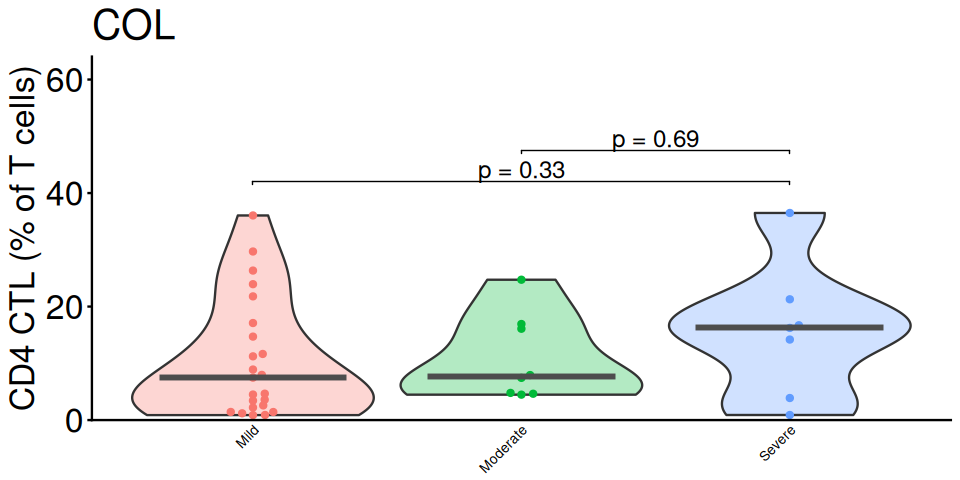

# A tibble: 8 × 4
  tissue n_participants n_observations dataset                
  <chr>           <int>          <int> <chr>                  
1 COL                39             39 3p diagnosis           
2 ILE                35             35 3p diagnosis           
3 COL                56             56 5p nonoverlap diagnosis
4 ILE                57             57 5p nonoverlap diagnosis
5 COL                39             39 all5p response         
6 ILE                39             39 all5p response         
7 COL                42             42 all response/severity  
8 ILE                39             39 all response/severity  

Final plots saved to: figures/cd4_freq_violin/final 


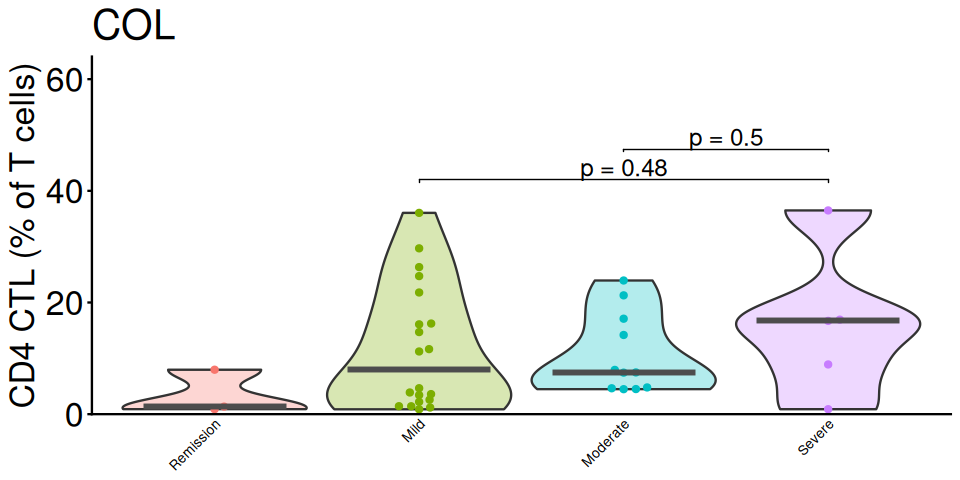

In [341]:

library(dplyr)
library(tidyr)
library(ggplot2)
library(ggbeeswarm)
library(ggpubr)
library(readr)
library(purrr)

# ============================================================
# 1. SETTINGS
# ============================================================

out_dir <- "figures/cd4_freq_violin/final"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

tissues <- c("ILE", "COL")
visits <- c("T0", "R", "R2")

diagnosis_levels <- c("HEA", "FGID", "UC", "CD")
response_levels <- c("NOA", "FR", "PR")
severity_levels <- c("Remission", "Mild", "Moderate", "Severe", "NM")

diagnosis_colors <- c(
  HEA = "#00bfc4ff",
  FGID = "#4DAF4A",
  UC = "#c77cffff",
  CD = "#f8766dff"
)

response_colors <- c(
"NOA" = "#e0e0e0ff",
"FR" = "#00cd00ff",
"PR" = "#ffa500ff")

plot_width <- 4
plot_height <- 4

format_p <- function(p) {
  ifelse(
    is.na(p),
    "NA",
    format(signif(p, 2), scientific = FALSE, trim = TRUE)
  )
}

save_plot <- function(p, name) {
  ggsave(
    file.path(out_dir, paste0(name, ".svg")),
    p, width = plot_width, height = plot_height
  )
  ggsave(
    file.path(out_dir, paste0(name, ".png")),
    p, width = plot_width, height = plot_height,
    dpi = 300
  )
  print(p)
}

get_nonmissing <- function(x) {
  values <- unique(x[!is.na(x)])
  if (length(values) == 0) return(x[NA_integer_][1])
  if (length(values) > 1) {
    stop("Conflicting nonmissing metadata values.")
  }
  values[1]
}

# ============================================================
# 2. PREPARE DATA
# ============================================================

df_base <- df_all_data_severity %>%
  dplyr::filter(
    annotations2 == "CD4 CTL",
    tissue %in% tissues,
    layer == "LP",
    dataset %in% c("GUT 3p", "GUT 5p"),
    !is.na(participant_id2),
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2),
    diagnosis = dplyr::recode(
      as.character(diagnosis),
      "DGBI" = "FGID",
      "Healthy" = "HEA"
    ),
    antitnf_response = dplyr::recode(
      as.character(antitnf_response),
      "NM" = "NOA",
      "RESP" = "FR"
    )
  )

# ============================================================
# Resolve duplicates within each chemistry by averaging freq
# ============================================================

df_base <- df_base %>%
  dplyr::group_by(
    dataset,
    participant_id2,
    timepoint,
    tissue,
    layer
  ) %>%
  dplyr::summarise(
    freq = mean(freq, na.rm = TRUE),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    .groups = "drop"
  )
# Participants present in 3p, for excluding overlaps from 5p
ids_3p <- df_base %>%
  dplyr::filter(dataset == "GUT 3p") %>%
  dplyr::distinct(participant_id2) %>%
  dplyr::pull(participant_id2)

# ============================================================
# 3. CREATE FOUR DATASET VERSIONS
# ============================================================

# Diagnosis plots use baseline only
df_3p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 3p",
    timepoint %in% c("T0", "T0D"),
    diagnosis %in% diagnosis_levels
  )

df_5p_nonoverlap <- df_base %>%
  dplyr::filter(
    dataset == "GUT 5p",
    !participant_id2 %in% ids_3p,
    timepoint == "T0",
    diagnosis %in% diagnosis_levels
  )

# Response plots: all 5p, T0/R/R2
df_all5p <- df_base %>%
  dplyr::filter(
    dataset == "GUT 5p",
    diagnosis == "CD",
    timepoint == "T0",
    antitnf_response %in% response_levels
  )

# Combined dataset: average 3p and 5p frequencies
# for matching participant x visit x tissue
df_all <- df_base %>%
  dplyr::filter(
    diagnosis == "CD",
    timepoint  == "T0",
    antitnf_response %in% response_levels
  ) %>%
  dplyr::group_by(
    participant_id2, timepoint, tissue, layer
  ) %>%
  dplyr::summarise(
    freq = mean(freq),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  )

# Convert frequency to percentage
df_3p <- df_3p %>% dplyr::mutate(freq_pct = freq * 100)
df_5p_nonoverlap <- df_5p_nonoverlap %>%
  dplyr::mutate(freq_pct = freq * 100)
df_all5p <- df_all5p %>% dplyr::mutate(freq_pct = freq * 100)
df_all <- df_all %>% dplyr::mutate(freq_pct = freq * 100)

# ============================================================
# 4. STATISTICAL HELPERS
# ============================================================

run_correlations <- function(df) {

  x <- as.numeric(factor(
    df$antitnf_response,
    levels = response_levels
  )) - 1

  y <- df$freq_pct
  keep <- is.finite(x) & is.finite(y)
  x <- x[keep]
  y <- y[keep]

  if (
    length(x) < 3 ||
    dplyr::n_distinct(x) < 2 ||
    dplyr::n_distinct(y) < 2
  ) {
    return(tibble::tibble(
      n = length(x),
      pearson_r = NA_real_,
      pearson_p = NA_real_,
      spearman_rho = NA_real_,
      spearman_p = NA_real_
    ))
  }

  pearson <- stats::cor.test(x, y, method = "pearson")
  spearman <- suppressWarnings(
    stats::cor.test(x, y, method = "spearman", exact = FALSE)
  )

  tibble::tibble(
    n = length(x),
    pearson_r = unname(pearson$estimate),
    pearson_p = pearson$p.value,
    spearman_rho = unname(spearman$estimate),
    spearman_p = spearman$p.value
  )
}

run_wilcoxon <- function(df, variable, comparisons) {

  purrr::map_dfr(comparisons, function(comp) {

    d <- df %>%
      dplyr::filter(
        as.character(.data[[variable]]) %in% comp
      )

    n1 <- sum(as.character(d[[variable]]) == comp[1])
    n2 <- sum(as.character(d[[variable]]) == comp[2])

    p <- if (n1 >= 2 && n2 >= 2) {
      suppressWarnings(
        stats::wilcox.test(
          d$freq_pct[as.character(d[[variable]]) == comp[1]],
          d$freq_pct[as.character(d[[variable]]) == comp[2]],
          exact = FALSE
        )$p.value
      )
    } else {
      NA_real_
    }

    tibble::tibble(
      group1 = comp[1],
      group2 = comp[2],
      n1 = n1,
      n2 = n2,
      p = p,
      p.format = format_p(p)
    )
  })
}

# ============================================================
# 5. PLOT FUNCTIONS
# ============================================================

plot_diagnosis <- function(df, tissue_i, prefix) {

  d <- df %>%
    dplyr::filter(tissue == tissue_i) %>%
    dplyr::mutate(
      diagnosis = factor(diagnosis, levels = diagnosis_levels)
    )

  if (nrow(d) == 0) return(NULL)

  stats <- run_wilcoxon(
    d, "diagnosis",
    list(c("CD", "UC"), c("CD", "FGID"), c("CD", "HEA"))
  )

  y_max <- max(d$freq_pct, na.rm = TRUE)
  y_step <- max(y_max * 0.15, 0.5)

  brackets <- stats %>%
    dplyr::filter(!is.na(p)) %>%
    dplyr::mutate(
      y.position = y_max + dplyr::row_number() * y_step,
      label = paste0("p = ", p.format)
    )

  p <- ggplot(d, aes(x = diagnosis, y = freq_pct)) +
    geom_violin(
      aes(fill = diagnosis),
      alpha = 0.3, scale = "width"
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(color = diagnosis),
      size = 1.3, cex = 1.5, corral = "random"
    ) +
    stat_summary(
      fun = median, geom = "crossbar",
      width = 0.7, color = "grey30"
    ) +
    ggpubr::stat_pvalue_manual(
      brackets,
      label = "label",
      xmin = "group1",
      xmax = "group2",
      y.position = "y.position",
      size = 5,
      bracket.size = 0.3,
      tip.length = 0.01,
      inherit.aes = FALSE
    ) +
    scale_fill_manual(values = diagnosis_colors, drop = FALSE) +
    scale_color_manual(values = diagnosis_colors, drop = FALSE) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0, 0.35))
    ) +
    labs(
      title = paste(tissue_i, "LP"),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    theme(
      legend.position = "none",
      axis.ticks.x = element_blank()
    ) +
    ggtheme()

  name <- paste(tissue_i, prefix, "diagnosis", sep = "_")
  save_plot(p, name)

  readr::write_csv(d, file.path(out_dir, paste0(name, "_data.csv")))
  readr::write_csv(stats, file.path(out_dir, paste0(name, "_stats.csv")))
}

plot_response <- function(df, tissue_i, prefix) {

  d <- df %>%
    dplyr::filter(tissue == tissue_i) %>%
    dplyr::mutate(
      antitnf_response = factor(
        antitnf_response, levels = response_levels
      )
    )

  if (nrow(d) == 0) return(NULL)

  stats <- run_correlations(d)

  label <- paste0(
    "Pearson r = ", round(stats$pearson_r, 2),
    ", p = ", format_p(stats$pearson_p),
    "\nSpearman rho = ", round(stats$spearman_rho, 2),
    ", p = ", format_p(stats$spearman_p)
  )

  p <- ggplot(
    d, aes(x = antitnf_response, y = freq_pct)
  ) +
    geom_violin(
      aes(fill = antitnf_response),
      alpha = 0.3, scale = "width"
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(color = antitnf_response),
      size = 1.3, cex = 1.5, corral = "random"
    ) +
    stat_summary(
      fun = median, geom = "crossbar",
      width = 0.7, color = "grey30"
    ) +
    annotate(
      "text", x = 2, y = Inf,
      label = label,
      hjust = 0.5, vjust = 1.2, size = 2.6
    ) +
    scale_fill_manual(values = response_colors, drop = FALSE) +
    scale_color_manual(values = response_colors, drop = FALSE) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0, 0.35))
    ) +
    labs(
      title = paste(tissue_i, "LP"),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    theme(
      legend.position = "none",
      axis.ticks.x = element_blank()
    ) +
    ggtheme()

  name <- paste(tissue_i, prefix, "response", sep = "_")
  save_plot(p, name)

  readr::write_csv(d, file.path(out_dir, paste0(name, "_data.csv")))
  readr::write_csv(stats, file.path(out_dir, paste0(name, "_stats.csv")))
}

plot_severity <- function(df, tissue_i, variable) {

  d <- df %>%
    dplyr::filter(
      tissue == tissue_i,
      !is.na(.data[[variable]])
    ) %>%
    dplyr::mutate(
      severity_group = factor(
        as.character(.data[[variable]]),
        levels = severity_levels
      )
    ) %>%
    dplyr::filter(!is.na(severity_group))

  if (nrow(d) == 0) return(NULL)

  stats <- run_wilcoxon(
    d, "severity_group",
    list(c("Mild", "Severe"), c("Moderate", "Severe"))
  )

  y_max <- max(d$freq_pct, na.rm = TRUE)
  y_step <- max(y_max * 0.15, 0.5)

  brackets <- stats %>%
    dplyr::filter(!is.na(p)) %>%
    dplyr::mutate(
      y.position = y_max + dplyr::row_number() * y_step,
      label = paste0("p = ", p.format)
    )

  p <- ggplot(d, aes(x = severity_group, y = freq_pct)) +
    geom_violin(
      aes(fill = severity_group),
      alpha = 0.3, scale = "width"
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(color = severity_group),
      size = 1.3, cex = 1.5, corral = "random"
    ) +
    stat_summary(
      fun = median, geom = "crossbar",
      width = 0.7, color = "grey30"
    ) +
    ggpubr::stat_pvalue_manual(
      brackets,
      label = "label",
      xmin = "group1",
      xmax = "group2",
      y.position = "y.position",
      size = 5,
      bracket.size = 0.3,
      tip.length = 0.01,
      inherit.aes = FALSE
    ) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0, 0.35))
    ) +
    labs(
      title = paste(tissue_i),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    theme(
      legend.position = "none",
      axis.text.x = element_text(
        angle = 45, hjust = 1, size = 8
      ),
      axis.ticks.x = element_blank()
    ) +
    ggtheme()

  name <- paste(tissue_i, variable, sep = "_")
  save_plot(p, name)

  readr::write_csv(d, file.path(out_dir, paste0(name, "_data.csv")))
  readr::write_csv(stats, file.path(out_dir, paste0(name, "_stats.csv")))
}

# ============================================================
# 6. GENERATE FINAL 12 PLOTS
# ============================================================

for (tissue_i in tissues) {

  # 1. 3p diagnosis
  plot_diagnosis(df_3p, tissue_i, "3p")

  # 2. 5p diagnosis, nonoverlapping participants
  plot_diagnosis(df_5p_nonoverlap, tissue_i, "5p_nonoverlap")

  # 3. All 5p response correlation
  plot_response(df_all5p, tissue_i, "all5p")

  # 4. Combined 3p + 5p response correlation
  plot_response(df_all, tissue_i, "all")

  # 5. Weighted severity score range
  plot_severity(df_all, tissue_i, "weighted_score_range")

  # 6. Severity score range
  plot_severity(df_all, tissue_i, "severity_score_range")
}

# ============================================================
# 7. PARTICIPANT COUNTS
# ============================================================

count_participants <- function(df, name) {
  df %>%
    dplyr::group_by(tissue) %>%
    dplyr::summarise(
      n_participants = dplyr::n_distinct(participant_id2),
      n_observations = dplyr::n(),
      .groups = "drop"
    ) %>%
    dplyr::mutate(dataset = name)
}

counts_final <- dplyr::bind_rows(
  count_participants(df_3p, "3p diagnosis"),
  count_participants(df_5p_nonoverlap, "5p nonoverlap diagnosis"),
  count_participants(df_all5p, "all5p response"),
  count_participants(df_all, "all response/severity")
)

print(counts_final, n = Inf)

readr::write_csv(
  counts_final,
  file.path(out_dir, "participant_counts.csv")
)

cat("\nFinal plots saved to:", out_dir, "\n")


In [342]:
severity_correlations <- df_all %>%
  dplyr::filter(
    timepoint == "T0",
    tissue %in% c("ILE", "COL"),
    layer == "LP"
  ) %>%
  tidyr::pivot_longer(
    cols = c(severity_score_range, weighted_score_range),
    names_to = "severity_variable",
    values_to = "severity_category"
  ) %>%
  dplyr::filter(
    as.character(severity_category) %in%
      c("Mild", "Moderate", "Severe")
  ) %>%
  dplyr::mutate(
    severity_numeric = match(
      as.character(severity_category),
      c("Mild", "Moderate", "Severe")
    )
  ) %>%
  dplyr::group_by(tissue, severity_variable) %>%
  dplyr::summarise(
    n = dplyr::n(),
    rho = if (
      dplyr::n() >= 3 &&
      dplyr::n_distinct(severity_numeric) >= 2 &&
      dplyr::n_distinct(freq_pct) >= 2
    ) {
      suppressWarnings(
        cor(
          severity_numeric,
          freq_pct,
          method = "spearman"
        )
      )
    } else NA_real_,
    p = if (
      dplyr::n() >= 3 &&
      dplyr::n_distinct(severity_numeric) >= 2 &&
      dplyr::n_distinct(freq_pct) >= 2
    ) {
      suppressWarnings(
        cor.test(
          severity_numeric,
          freq_pct,
          method = "spearman",
          exact = FALSE
        )$p.value
      )
    } else NA_real_,
    .groups = "drop"
  )

print(severity_correlations, n = Inf)

# A tibble: 4 × 5
  tissue severity_variable        n   rho      p
  <chr>  <chr>                <int> <dbl>  <dbl>
1 COL    severity_score_range    36 0.156 0.362 
2 COL    weighted_score_range    38 0.184 0.269 
3 ILE    severity_score_range    36 0.289 0.0870
4 ILE    weighted_score_range    38 0.253 0.125 


### UC signif for reviewer

In [347]:
out_dir <- "figures/cd4_freq_violin/final_with_UC"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

In [370]:
plot_diagnosis <- function(df, tissue_i, prefix) {

  d <- df %>%
    dplyr::filter(tissue == tissue_i) %>%
    dplyr::mutate(
      diagnosis = factor(diagnosis, levels = diagnosis_levels)
    )

  if (nrow(d) == 0) return(NULL)

  comparisons <- list(
  c("CD", "FGID"),
  c("CD", "UC"),
  c("CD", "HEA")
)

stats <- run_wilcoxon(d, "diagnosis", comparisons)

  stats <- run_wilcoxon(d, "diagnosis", comparisons)

  y_max <- max(d$freq_pct, na.rm = TRUE)
  y_step <- max(y_max * 0.15, 0.5)

  brackets <- stats %>%
    dplyr::filter(!is.na(p)) %>%
    dplyr::mutate(
      y.position = y_max + dplyr::row_number() * y_step,
      label = paste0("p = ", p.format)
    )

  p <- ggplot(d, aes(x = diagnosis, y = freq_pct)) +
    geom_violin(
      aes(fill = diagnosis),
      alpha = 0.3,
      scale = "width"
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(color = diagnosis),
      size = 1.3,
      cex = 1.5,
      corral = "random"
    ) +
    stat_summary(
      fun = median,
      geom = "crossbar",
      width = 0.7,
      color = "grey30"
    ) +
    scale_fill_manual(values = diagnosis_colors, drop = FALSE) +
    scale_color_manual(values = diagnosis_colors, drop = FALSE) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0, 0.5))
    ) +
    labs(
      title = paste(tissue_i, "LP"),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    theme(
      legend.position = "none",
      axis.ticks.x = element_blank()
    ) +
    ggtheme()

  if (nrow(brackets) > 0) {
    p <- p +
      ggpubr::stat_pvalue_manual(
        brackets,
        label = "label",
        xmin = "group1",
        xmax = "group2",
        y.position = "y.position",
        size = 3.5,
        bracket.size = 0.3,
        tip.length = 0.01,
        inherit.aes = FALSE
      )
  }

  name <- paste(tissue_i, prefix, "diagnosis", sep = "_")

  save_plot(p, name)

  readr::write_csv(
    d,
    file.path(out_dir, paste0(name, "_data.csv"))
  )

  readr::write_csv(
    stats,
    file.path(out_dir, paste0(name, "_stats.csv"))
  )
}

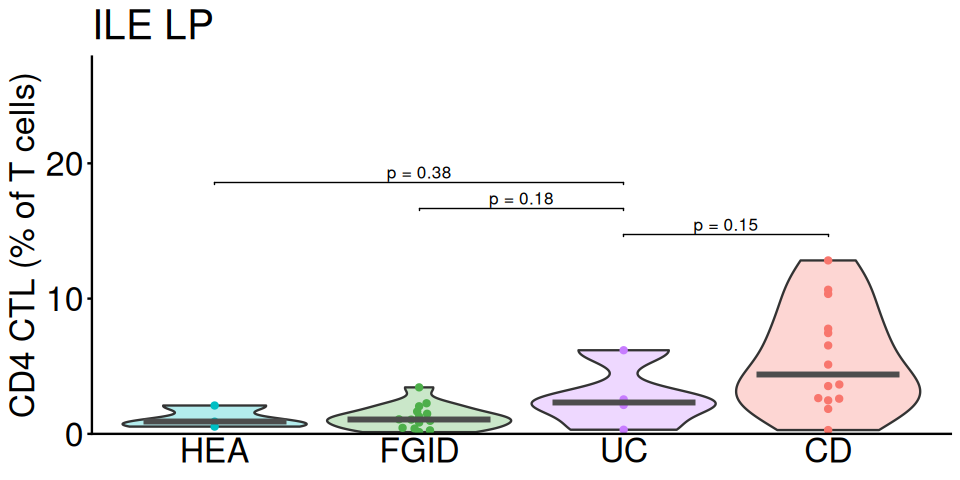

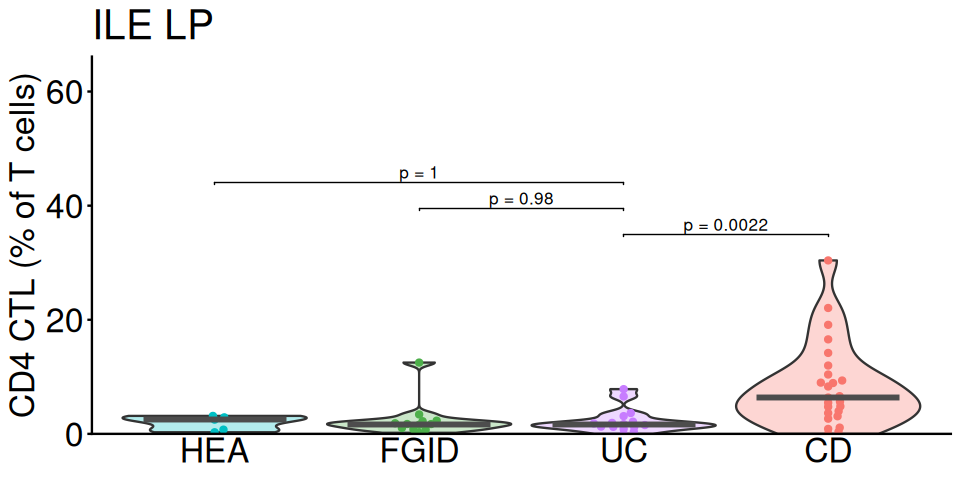

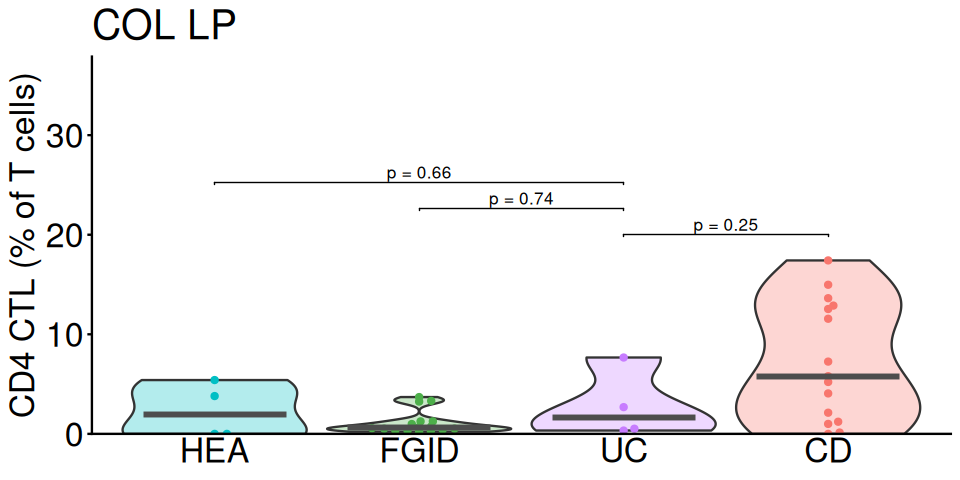

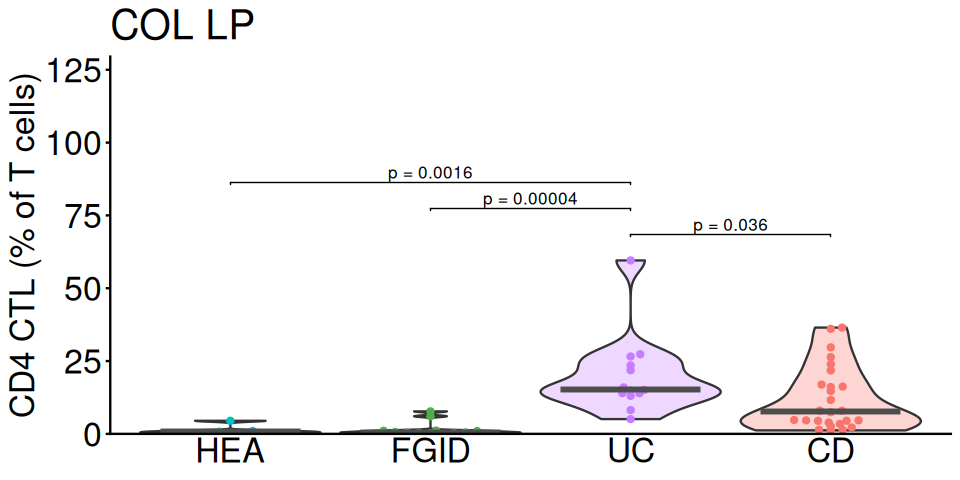

In [353]:
out_dir <- "figures/cd4_freq_violin/final_diagnosis_with_UC"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

for (tissue_i in c("ILE", "COL")) {

  plot_diagnosis(df_3p, tissue_i, "3p")

  plot_diagnosis(df_5p_nonoverlap, tissue_i, "5p_nonoverlap")

}

## Final plots Blood

In [334]:
df_all_data_severity$dataset  %>% table

.
BLD 3p BLD 5p GUT 3p GUT 5p 
   588   1358   1593   4545 

In [362]:
plot_response <- function(df, tissue_i, prefix) {

  d <- df %>%
    dplyr::filter(
      tissue == tissue_i,
      timepoint == "T0",
      antitnf_response %in% c("NOA", "FR", "PR"),
      !is.na(freq_pct)
    ) %>%
    dplyr::mutate(
      antitnf_response = factor(
        as.character(antitnf_response),
        levels = c("NOA", "FR", "PR")
      ),
      response_numeric = as.numeric(antitnf_response) - 1
    )

  if (nrow(d) == 0) return(invisible(NULL))

  # Colors matching the intestinal response plots
  response_colors <- c(
    NOA = "grey88",
    FR  = "green3",
    PR  = "orange"
  )

  # Correlation tests
  valid <- nrow(d) >= 3 &&
    dplyr::n_distinct(d$response_numeric) >= 2 &&
    dplyr::n_distinct(d$freq_pct) >= 2

  if (valid) {
    pearson <- stats::cor.test(
      d$response_numeric, d$freq_pct,
      method = "pearson"
    )

    spearman <- suppressWarnings(
      stats::cor.test(
        d$response_numeric, d$freq_pct,
        method = "spearman",
        exact = FALSE
      )
    )

    stats <- tibble::tibble(
      n = nrow(d),
      pearson_r = unname(pearson$estimate),
      pearson_p = pearson$p.value,
      spearman_rho = unname(spearman$estimate),
      spearman_p = spearman$p.value
    )
  } else {
    stats <- tibble::tibble(
      n = nrow(d),
      pearson_r = NA_real_,
      pearson_p = NA_real_,
      spearman_rho = NA_real_,
      spearman_p = NA_real_
    )
  }

  format_p <- function(p) {
    if (is.na(p)) return("NA")
    format(signif(p, 2), scientific = FALSE, trim = TRUE)
  }

  label <- paste0(
    "Pearson r = ", round(stats$pearson_r, 2),
    ", p = ", format_p(stats$pearson_p),
    "\nSpearman rho = ", round(stats$spearman_rho, 2),
    ", p = ", format_p(stats$spearman_p)
  )

  # Plot
  p <- ggplot(
    d,
    aes(x = response_numeric, y = freq_pct)
  ) +
    geom_violin(
      aes(
        group = antitnf_response,
        fill = antitnf_response
      ),
      alpha = 0.3,
      scale = "width",
      width = 0.8
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(
        group = antitnf_response,
        color = antitnf_response
      ),
      size = 1.5,
      cex = 2,
      shape = 16,
      corral = "random"
    ) +
    geom_smooth(
      aes(group = 1),
      method = "lm",
      formula = y ~ x,
      se = FALSE,
      linetype = "dashed",
      color = "grey35",
      linewidth = 0.7,
      fullrange = TRUE
    ) +
    stat_summary(
      aes(
        group = antitnf_response,
        fill = antitnf_response
      ),
      fun = median,
      geom = "point",
      shape = 21,
      size = 3.5,
      stroke = 0.7,
      color = "black"
    ) +
    scale_x_continuous(
      breaks = 0:2,
      labels = c("NOA", "FR", "PR"),
      limits = c(-0.5, 2.5)
    ) +
    scale_fill_manual(
      values = response_colors,
      drop = FALSE
    ) +
    scale_color_manual(
      values = response_colors,
      drop = FALSE
    ) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0.05, 0.30))
    ) +
    annotate(
      "text",
      x = 1,
      y = Inf,
      label = label,
      hjust = 0.5,
      vjust = 1.2,
      size = 2.6
    ) +
    labs(
      title = ifelse(tissue_i == "BLD", "Blood", paste(tissue_i, "LP")),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    ggtheme() +
    theme(
      text = element_text(family = "Arial"),
      legend.position = "none",
      axis.ticks.x = element_blank()
    )

  # Save files
  name <- paste(tissue_i, prefix, "response", sep = "_")

  ggsave(
    file.path(out_dir, paste0(name, ".svg")),
    p, width = 3.5, height = 5
  )

  ggsave(
    file.path(out_dir, paste0(name, ".png")),
    p, width = 3.5, height = 5, dpi = 300
  )

  readr::write_csv(
    d,
    file.path(out_dir, paste0(name, "_data.csv"))
  )

  readr::write_csv(
    stats,
    file.path(out_dir, paste0(name, "_stats.csv"))
  )

  print(p)
}

In [376]:
plot_width  <- 4.5
plot_height  <- 5.5

# A tibble: 13 × 4
   dataset timepoint diagnosis     n
   <chr>   <chr>     <chr>     <int>
 1 BLD 3p  R         CD            3
 2 BLD 3p  T0        CD           16
 3 BLD 3p  T0        FGID         16
 4 BLD 3p  T0        OTH           3
 5 BLD 3p  T0        UC            4
 6 BLD 5p  R         CD           14
 7 BLD 5p  R         UC            2
 8 BLD 5p  R2        CD            1
 9 BLD 5p  T0        CD           37
10 BLD 5p  T0        FGID         21
11 BLD 5p  T0        HEA           3
12 BLD 5p  T0        OTH           4
13 BLD 5p  T0        UC           15


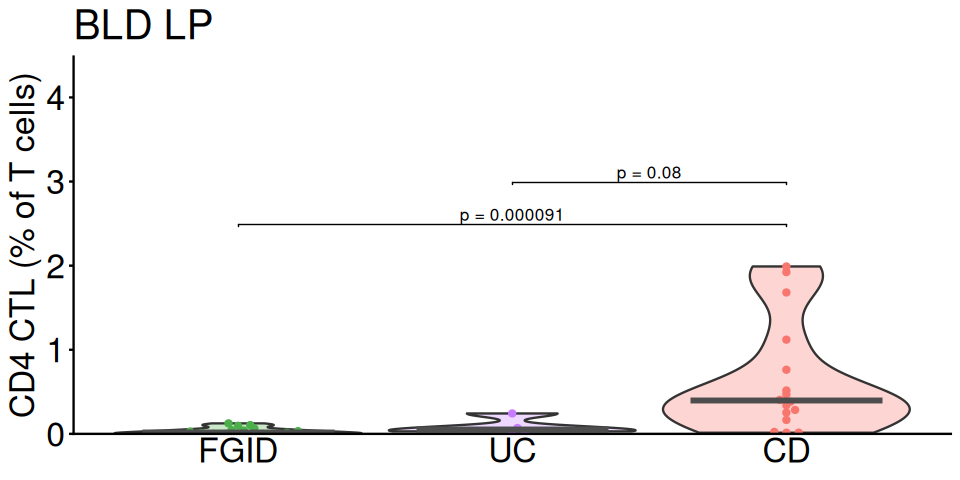

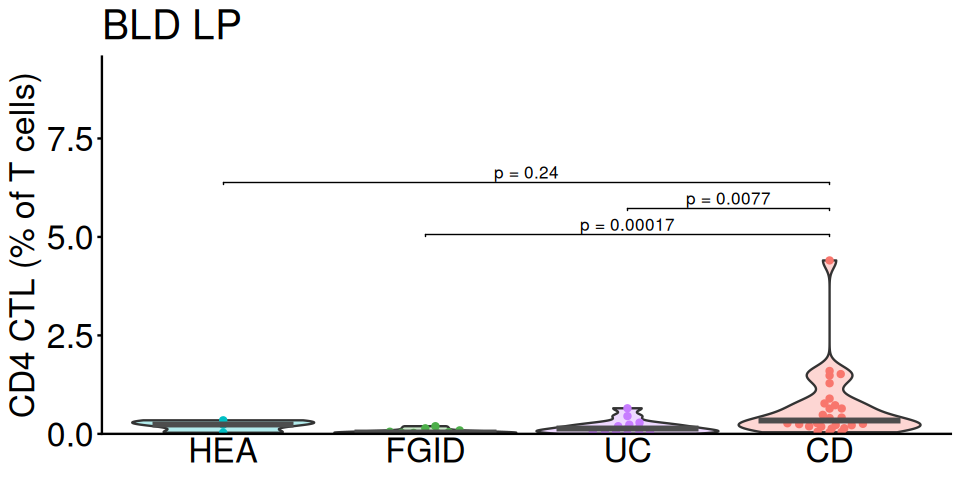

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_smooth()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_smooth()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_smooth()`).”


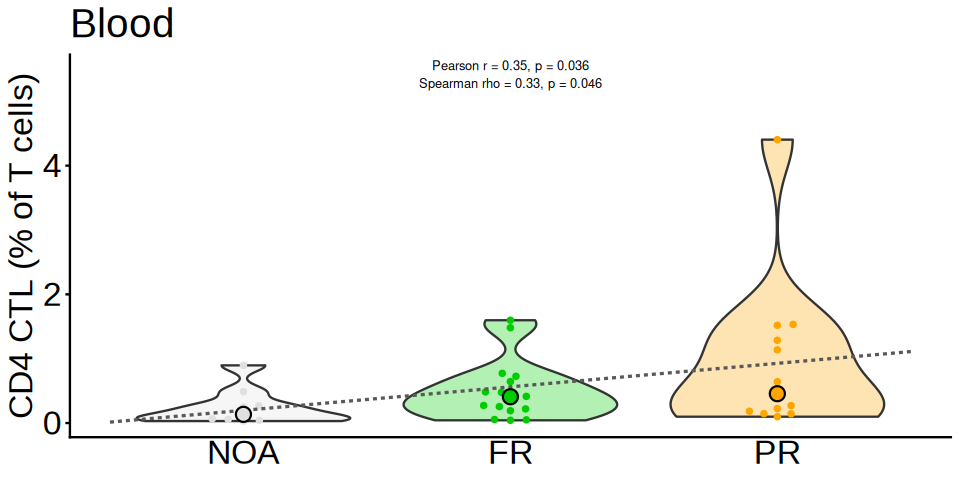

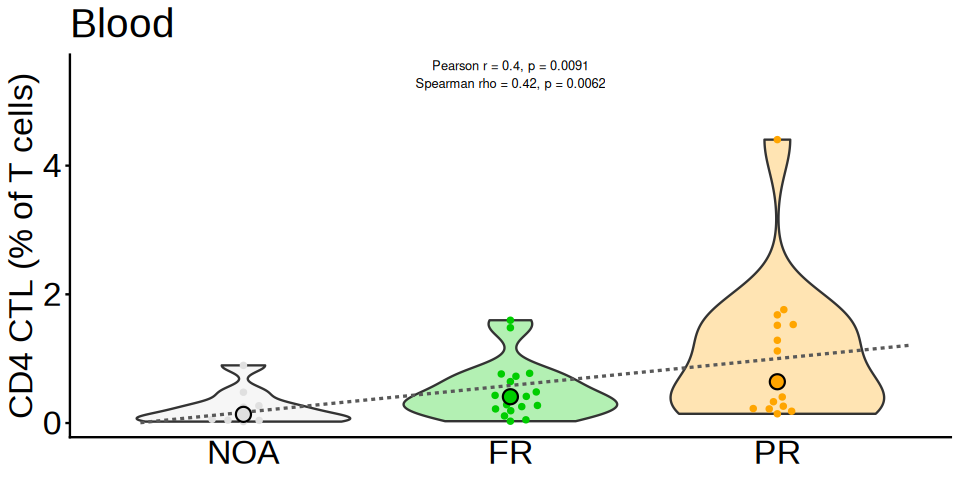

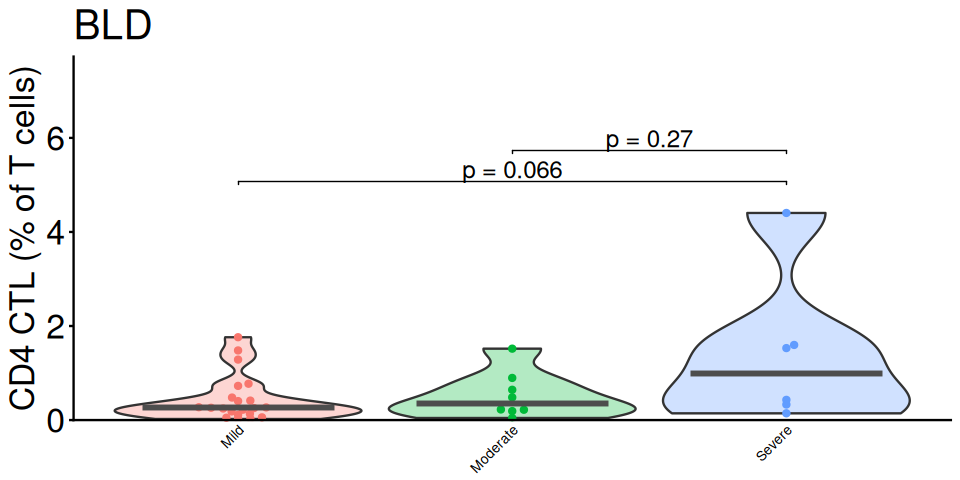

# A tibble: 4 × 4
  tissue n_participants n_observations dataset                
  <chr>           <int>          <int> <chr>                  
1 BLD                36             36 3p diagnosis           
2 BLD                51             51 5p nonoverlap diagnosis
3 BLD                37             37 all5p response         
4 BLD                42             42 all response/severity  


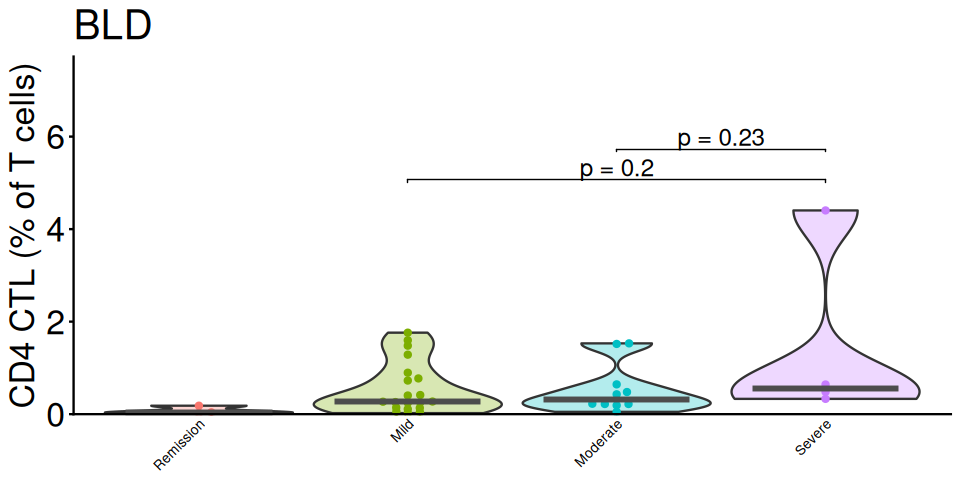

In [377]:
# ============================================================
# 1. SETTINGS
# ============================================================

out_dir <- "figures/cd4_freq_violin/final_BLD4_diagnosis"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

tissues <- "BLD"

# ============================================================
# 2. PREPARE BLD  DATA
# ============================================================

df_base <- df_all_data_severity %>%
  dplyr::filter(
    tissue == "BLD",
    annotations2 == "TRUE",
    dataset %in% c("BLD 3p", "BLD 5p"),
    !is.na(participant_id2),
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2),
    diagnosis = dplyr::recode(
      as.character(diagnosis),
      "DGBI" = "FGID",
      "Healthy" = "HEA"
    ),
    antitnf_response = dplyr::recode(
      as.character(antitnf_response),
      "NM" = "NOA",
      "RESP" = "FR"
    )
  )

# Check available datasets and timepoints
df_base %>%
  dplyr::count(dataset, timepoint, diagnosis) %>%
  print(n = Inf)

# ============================================================
# 3. AVERAGE DUPLICATES WITHIN EACH CHEMISTRY
# ============================================================

df_base <- df_base %>%
  dplyr::group_by(
    dataset,
    participant_id2,
    timepoint,
    tissue,
    layer
  ) %>%
  dplyr::summarise(
    freq = mean(freq, na.rm = TRUE),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    .groups = "drop"
  )

# ============================================================
# 4. CREATE DATASET VERSIONS
# ============================================================

ids_3p <- df_base %>%
  dplyr::filter(dataset == "BLD 3p") %>%
  dplyr::distinct(participant_id2) %>%
  dplyr::pull(participant_id2)

# 3p diagnosis
df_3p <- df_base %>%
  dplyr::filter(
    dataset == "BLD 3p",
    timepoint %in% c("T0", "T0D"),
    diagnosis %in% diagnosis_levels
  ) %>%
  dplyr::mutate(freq_pct = freq * 100)

# 5p diagnosis, excluding overlap with 3p
df_5p_nonoverlap <- df_base %>%
  dplyr::filter(
    dataset == "BLD 5p",
    !participant_id2 %in% ids_3p,
    timepoint == "T0",
    diagnosis %in% diagnosis_levels
  ) %>%
  dplyr::mutate(freq_pct = freq * 100)

# All 5p response
df_all5p <- df_base %>%
  dplyr::filter(
    dataset == "BLD 5p",
    diagnosis == "CD",
    timepoint %in% c("T0"),
    antitnf_response %in% response_levels
  ) %>%
  dplyr::mutate(freq_pct = freq * 100)

# Combined 3p + 5p response and severity
df_all <- df_base %>%
  dplyr::filter(
    diagnosis == "CD",
    timepoint %in% c("T0"),
    antitnf_response %in% response_levels
  ) %>%
  dplyr::group_by(
    participant_id2, timepoint, tissue, layer
  ) %>%
  dplyr::summarise(
    freq = mean(freq),
    diagnosis = get_nonmissing(diagnosis),
    antitnf_response = get_nonmissing(antitnf_response),
    severity_score_range = get_nonmissing(severity_score_range),
    weighted_score_range = get_nonmissing(weighted_score_range),
    severity_score = get_nonmissing(severity_score),
    weighted_severity_score = get_nonmissing(weighted_severity_score),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  ) %>%
  dplyr::mutate(freq_pct = freq * 100)

# ============================================================
# 5. GENERATE SIX FINAL BLD  PLOTS
# ============================================================

plot_diagnosis(df_3p, "BLD", "3p")

plot_diagnosis(df_5p_nonoverlap, "BLD", "5p_nonoverlap")

plot_response(df_all5p, "BLD", "all5p")

plot_response(df_all, "BLD", "all")

plot_severity(df_all, "BLD", "weighted_score_range")

plot_severity(df_all, "BLD", "severity_score_range")

# ============================================================
# 6. SAVE PARTICIPANT COUNTS
# ============================================================

counts_final <- dplyr::bind_rows(
  count_participants(df_3p, "3p diagnosis"),
  count_participants(df_5p_nonoverlap, "5p nonoverlap diagnosis"),
  count_participants(df_all5p, "all5p response"),
  count_participants(df_all, "all response/severity")
)

print(counts_final, n = Inf)

readr::write_csv(
  counts_final,
  file.path(out_dir, "participant_counts.csv")
)

# A tibble: 2 × 5
  tissue n_other n_severe      p p.format
  <chr>    <int>    <int>  <dbl> <chr>   
1 COL         31        7 0.366  0.37    
2 ILE         30        8 0.0362 0.036   


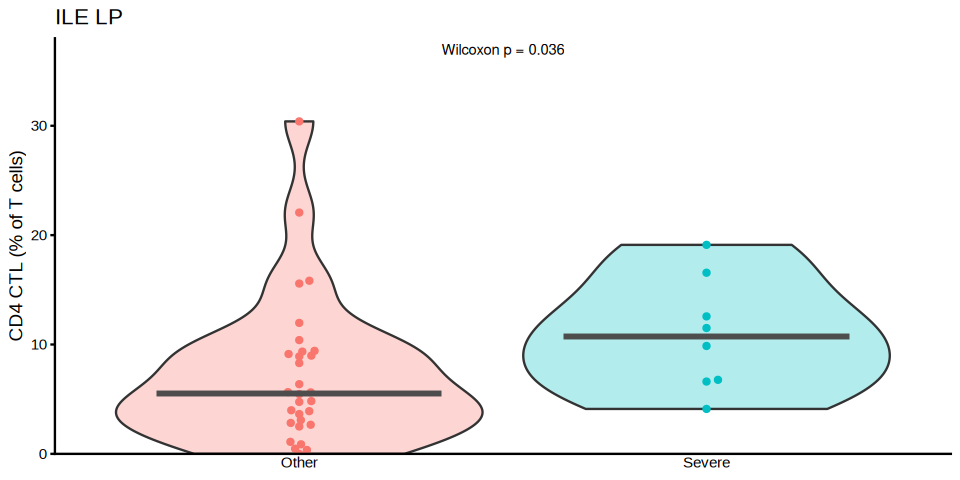

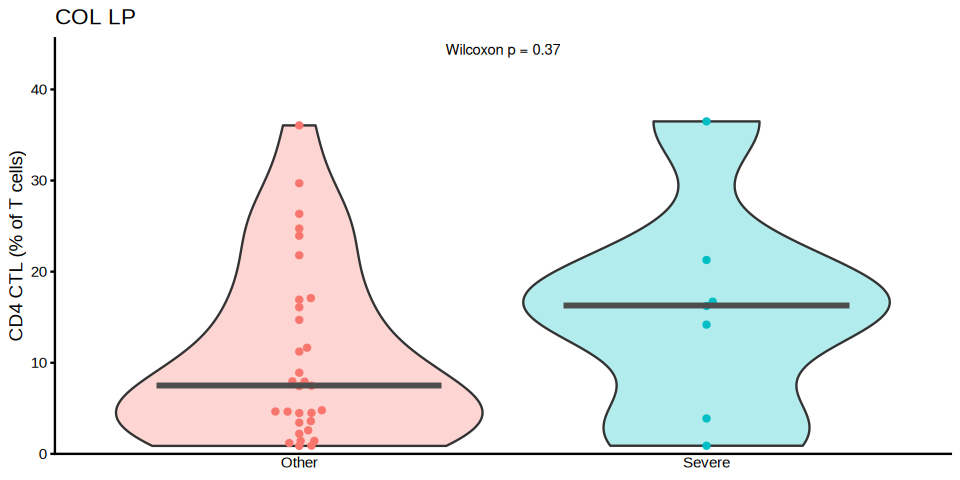

In [343]:
library(dplyr)
library(ggplot2)
library(ggbeeswarm)

out_dir <- "figures/cd4_freq_violin/final"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

df_weighted <- df_all %>%
  dplyr::filter(
    timepoint == "T0",
    tissue %in% c("ILE", "COL"),
    layer == "LP",
    as.character(weighted_score_range) %in%
      c("Remission", "Mild", "Moderate", "Severe"),
    !is.na(freq_pct)
  ) %>%
  dplyr::mutate(
    severity_group = factor(
      dplyr::if_else(
        as.character(weighted_score_range) == "Severe",
        "Severe",
        "Other"
      ),
      levels = c("Other", "Severe")
    )
  )

# Wilcoxon test separately for each tissue
wilcox_results <- df_weighted %>%
  dplyr::group_by(tissue) %>%
  dplyr::group_modify(~ {
    d <- .x

    n_other <- sum(d$severity_group == "Other")
    n_severe <- sum(d$severity_group == "Severe")

    p <- if (n_other >= 2 && n_severe >= 2) {
      stats::wilcox.test(
        freq_pct ~ severity_group,
        data = d,
        exact = FALSE
      )$p.value
    } else {
      NA_real_
    }

    tibble::tibble(
      n_other = n_other,
      n_severe = n_severe,
      p = p,
      p.format = format_p(p)
    )
  }) %>%
  dplyr::ungroup()

print(wilcox_results)

readr::write_csv(
  wilcox_results,
  file.path(out_dir, "weighted_severity_severe_vs_other_wilcox.csv")
)

# Plot separately for ILE LP and COL LP
for (tissue_i in c("ILE", "COL")) {

  d <- df_weighted %>%
    dplyr::filter(tissue == tissue_i)

  if (nrow(d) == 0) next

  stat <- wilcox_results %>%
    dplyr::filter(tissue == tissue_i)

  p <- ggplot(
    d,
    aes(x = severity_group, y = freq_pct)
  ) +
    geom_violin(
      aes(fill = severity_group),
      alpha = 0.3,
      scale = "width"
    ) +
    ggbeeswarm::geom_beeswarm(
      aes(color = severity_group),
      size = 1.3,
      cex = 1.5,
      corral = "random"
    ) +
    stat_summary(
      fun = median,
      geom = "crossbar",
      width = 0.7,
      color = "grey30"
    ) +
    annotate(
      "text",
      x = 1.5,
      y = Inf,
      label = paste0("Wilcoxon p = ", stat$p.format),
      vjust = 1.5,
      size = 3
    ) +
    scale_y_continuous(
      limits = c(0, NA),
      expand = expansion(mult = c(0, 0.25))
    ) +
    labs(
      title = paste(tissue_i, "LP"),
      x = NULL,
      y = "CD4 CTL (% of T cells)"
    ) +
    theme_classic() +
    theme(
      text = element_text(family = "Arial"),
      legend.position = "none",
      axis.ticks.x = element_blank()
    )

  ggsave(
    file.path(
      out_dir,
      paste0(tissue_i, "_weighted_severe_vs_other.svg")
    ),
    p,
    width = 3.5,
    height = 5
  )

  ggsave(
    file.path(
      out_dir,
      paste0(tissue_i, "_weighted_severe_vs_other.png")
    ),
    p,
    width = 3.5,
    height = 5,
    dpi = 300
  )

  print(p)
}

# A tibble: 1 × 5
  tissue n_other n_severe      p p.format
  <chr>    <int>    <int>  <dbl> <chr>   
1 BLD         29        6 0.0763 0.076   


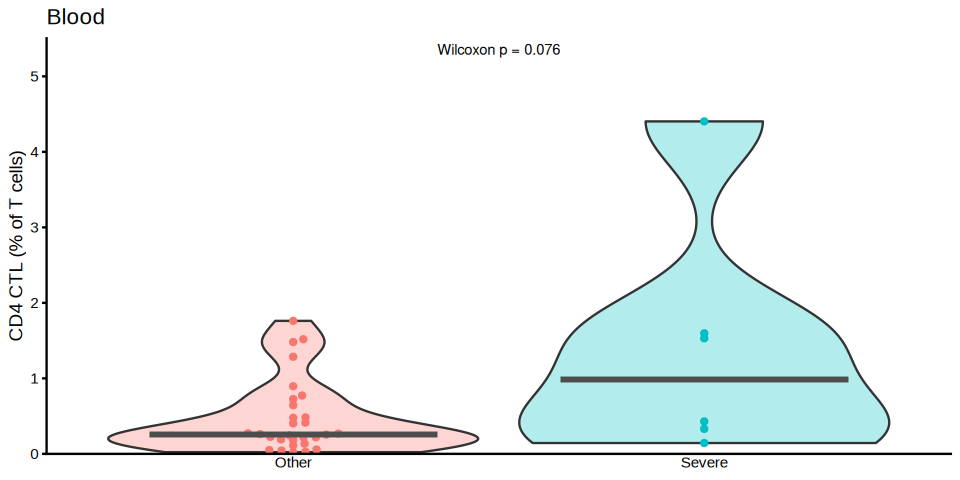

In [345]:
library(dplyr)
library(ggplot2)
library(ggbeeswarm)
library(readr)

out_dir <- "figures/cd4_freq_violin/final_BLD"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

# Helper: retain a unique nonmissing metadata value
get_nonmissing <- function(x) {
  values <- unique(x[!is.na(x)])
  if (length(values) == 0) return(x[NA_integer_][1])
  if (length(values) > 1) stop("Conflicting metadata values.")
  values[1]
}

# ============================================================
# 1. Prepare blood data: T0 only
# ============================================================

df_bld <- df_all_data_severity %>%
  dplyr::filter(
    tissue == "BLD",
    as.character(annotations2) == "TRUE",
    timepoint == "T0",
    diagnosis == "CD",
    dataset %in% c("BLD 3p", "BLD 5p"),
    !is.na(participant_id2),
    !is.na(freq)
  ) %>%
  dplyr::mutate(
    participant_id2 = as.character(participant_id2)
  )

# Average duplicate samples within each chemistry
df_bld <- df_bld %>%
  dplyr::group_by(
    dataset, participant_id2, timepoint, tissue
  ) %>%
  dplyr::summarise(
    freq = mean(freq),
    weighted_score_range = get_nonmissing(weighted_score_range),
    .groups = "drop"
  )

# Average across chemistries for overlapping participants
df_bld <- df_bld %>%
  dplyr::group_by(participant_id2, timepoint, tissue) %>%
  dplyr::summarise(
    freq = mean(freq),
    weighted_score_range = get_nonmissing(weighted_score_range),
    n_datasets = dplyr::n_distinct(dataset),
    .groups = "drop"
  ) %>%
  dplyr::mutate(
    freq_pct = freq * 100
  )

# ============================================================
# 2. Define severity groups
# ============================================================

df_weighted_bld <- df_bld %>%
  dplyr::filter(
    as.character(weighted_score_range) %in%
      c("Remission", "Mild", "Moderate", "Severe")
  ) %>%
  dplyr::mutate(
    severity_group = factor(
      dplyr::if_else(
        as.character(weighted_score_range) == "Severe",
        "Severe",
        "Other"
      ),
      levels = c("Other", "Severe")
    )
  )

# ============================================================
# 3. Wilcoxon test
# ============================================================

n_other <- sum(df_weighted_bld$severity_group == "Other")
n_severe <- sum(df_weighted_bld$severity_group == "Severe")

p_value <- if (n_other >= 2 && n_severe >= 2) {
  stats::wilcox.test(
    freq_pct ~ severity_group,
    data = df_weighted_bld,
    exact = FALSE
  )$p.value
} else {
  NA_real_
}

p_format <- if (is.na(p_value)) {
  "NA"
} else {
  format(signif(p_value, 2), scientific = FALSE, trim = TRUE)
}

stats_bld <- tibble::tibble(
  tissue = "BLD",
  n_other = n_other,
  n_severe = n_severe,
  p = p_value,
  p.format = p_format
)

print(stats_bld)

# ============================================================
# 4. Plot
# ============================================================

p <- ggplot(
  df_weighted_bld,
  aes(x = severity_group, y = freq_pct)
) +
  geom_violin(
    aes(fill = severity_group),
    alpha = 0.3,
    scale = "width"
  ) +
  ggbeeswarm::geom_beeswarm(
    aes(color = severity_group),
    size = 1.3,
    cex = 1.5,
    corral = "random"
  ) +
  stat_summary(
    fun = median,
    geom = "crossbar",
    width = 0.7,
    color = "grey30"
  ) +
  annotate(
    "text",
    x = 1.5,
    y = Inf,
    label = paste0("Wilcoxon p = ", p_format),
    vjust = 1.5,
    size = 3
  ) +
  scale_y_continuous(
    limits = c(0, NA),
    expand = expansion(mult = c(0, 0.25))
  ) +
  labs(
    title = "Blood",
    x = NULL,
    y = "CD4 CTL (% of T cells)"
  ) +
  theme_classic() +
  theme(
    text = element_text(family = "Arial"),
    legend.position = "none",
    axis.ticks.x = element_blank()
  )

ggsave(
  file.path(out_dir, "BLD_weighted_severe_vs_other.svg"),
  p, width = 3.5, height = 5
)

ggsave(
  file.path(out_dir, "BLD_weighted_severe_vs_other.png"),
  p, width = 3.5, height = 5, dpi = 300
)

print(p)

# ============================================================
# 5. Export source data and statistics
# ============================================================

readr::write_csv(
  df_weighted_bld,
  file.path(out_dir, "BLD_weighted_severe_vs_other_data.csv")
)

readr::write_csv(
  stats_bld,
  file.path(out_dir, "BLD_weighted_severe_vs_other_stats.csv")
)